# Bài tập lớn hợp nhất – Xử lý ảnh & Thị giác máy tính (121036)

Nhóm: Tấn Hiệp (NT), Huỳnh Nam, Hồng Sen, Tấn Lên, Hồng Gấm

**Quy định:** code các hàm tự viết, không dùng AI. Ô thí nghiệm có dùng AI phải có ô markdown khai báo prompt ngay phía trên (mẫu ở cuối notebook).

## 0. Import chung
_Chỉ dùng thư viện được phép trong phần cài đặt: numpy, matplotlib, time._

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2  # CHỈ dùng để đọc ảnh và trong các ô ĐỐI CHIẾU

# PHẦN A – 5 Demo của slide Bài 1

## Demo 1 – Ảnh là bảng số  _(Hồng Gấm)_

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2
from pathlib import Path

# Tìm thư mục images/ từ thư mục đang chạy trở lên (chạy từ lam_viec/ hay gốc repo đều được)
IMG_DIR = next(p / "images" for p in [Path.cwd(), *Path.cwd().parents] if (p / "images").is_dir())

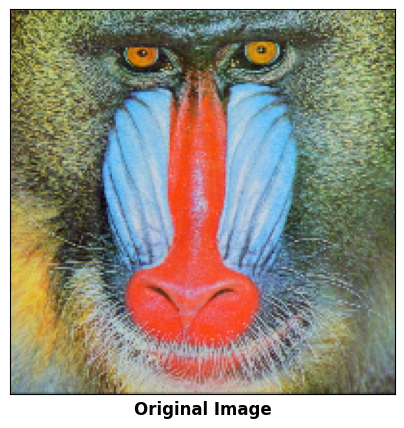

In [3]:
img = cv2.imread(str(IMG_DIR / "baboon.jpg"))

if img is None:
    raise FileNotFoundError("Không tìm thấy baboon.jpg")

img = cv2.resize(img, (200, 200))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.xlabel("Original Image", fontsize=12, fontweight="bold")
plt.xticks([])
plt.yticks([])
plt.show()

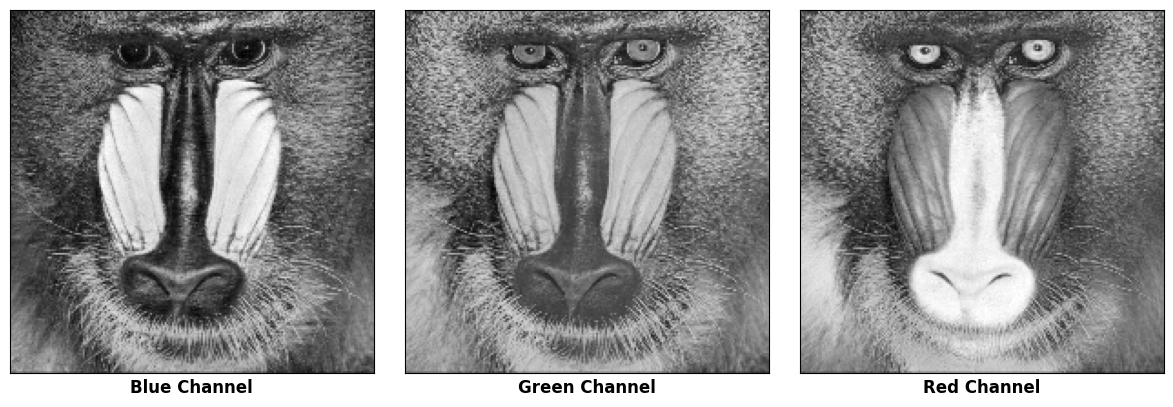

In [4]:
B, G, R = cv2.split(img)

channels = [B, G, R]
labels = ["Blue Channel", "Green Channel", "Red Channel"]

plt.figure(figsize=(12, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(channels[i], cmap="gray", vmin=0, vmax=255)
    plt.xlabel(labels[i], fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

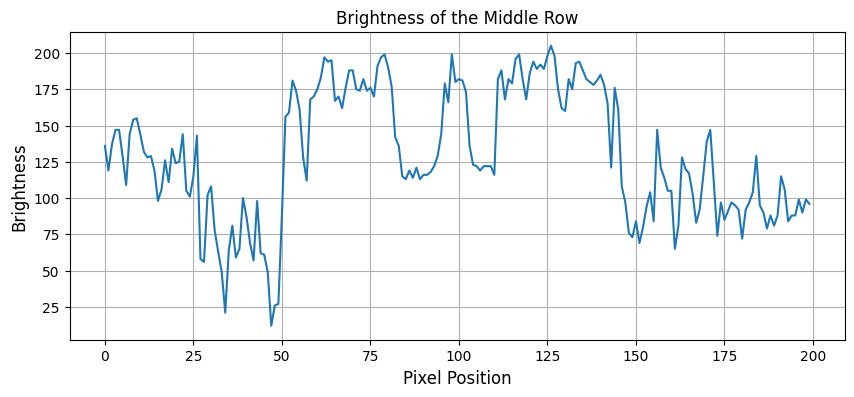

In [5]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

row = gray.shape[0] // 2

plt.figure(figsize=(10, 4))
plt.plot(gray[row, :])

plt.xlabel("Pixel Position", fontsize=12)
plt.ylabel("Brightness", fontsize=12)
plt.title("Brightness of the Middle Row")

plt.grid(True)
plt.show()

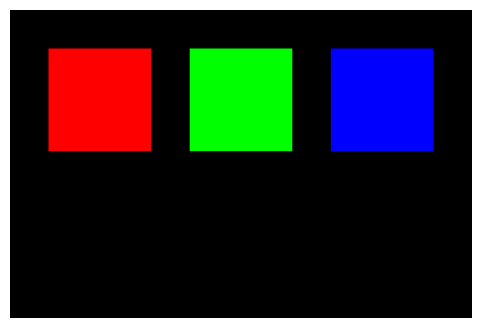

In [6]:

color_img = np.zeros((240, 360, 3), dtype=np.uint8)

color_img[30:110, 30:110] = (0, 0, 255)
color_img[30:110, 140:220] = (0, 255, 0)
color_img[30:110, 250:330] = (255, 0, 0)

plt.figure(figsize=(8, 4))
plt.imshow(cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

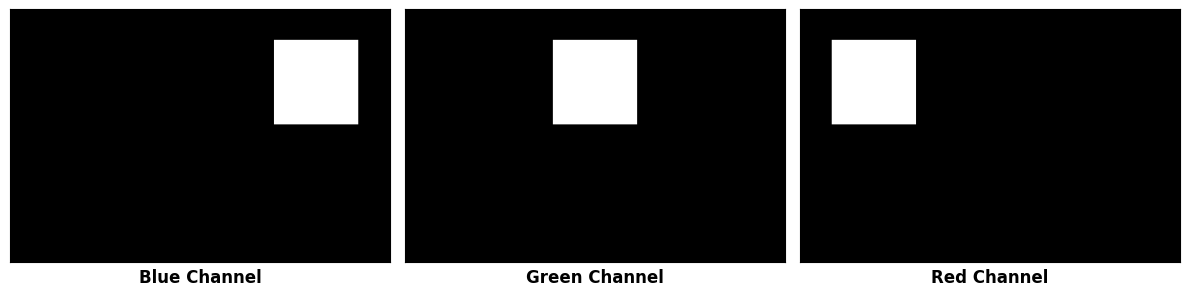

In [7]:

cB, cG, cR = cv2.split(color_img)

plt.figure(figsize=(12, 3))

for i, (ch, label) in enumerate(zip([cB, cG, cR], ["Blue Channel", "Green Channel", "Red Channel"])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(ch, cmap="gray", vmin=0, vmax=255)
    plt.xlabel(label, fontsize=12, fontweight="bold")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

## Demo 2 – Toán tử điểm: αI+β, gamma, cân bằng histogram  _(Huỳnh Nam)_

Hàm

In [8]:
def IShow(*I,T = None):
    n = len(I)
    f, ax = plt.subplots(1, n, figsize=(2 * n, 2))
    if n == 1:
        ax = [ax]
    for i, (a, Im) in enumerate(zip(ax, I)):
        a.imshow(Im.astype(np.uint8),cmap='gray',vmin=0,vmax=255)
        a.axis('off')  
        if T is not None:
            a.set_title(T[i], fontsize=9)        
    plt.tight_layout()
    plt.show()
def LShow(*I,T = None):
    n = len(I)
    f, ax = plt.subplots(1, n, figsize=(3 * n, 5))
    if n == 1:
        ax = [ax]
    for i, (a, Im) in enumerate(zip(ax, I)):
        a.bar(range(256), Hist(Im), width=1, color='k')  
        if T is not None:
            a.set_title(T[i], fontsize=9)        
    plt.tight_layout()
    plt.show()
def HShow(*H, T=None):
    n = len(H)
    f, ax = plt.subplots(1, n, figsize=(2 * n, 1.5))
    if n == 1:
        ax = [ax]
    for i, (a, h) in enumerate(zip(ax, H)):
        a.bar(range(len(h)), h, width=1, color='k')
        a.set_xlim(0, 255)
        a.set_yticks([])
        if T is not None:
            a.set_title(T[i], fontsize=9)
    plt.tight_layout()
    plt.show() 
def LnrOp(I, A, B):
    G = A*I.astype(float)+B
    return np.clip(G,0,255).astype(np.uint8)

def GmaCorc(I,Gma):
    G = ((I.astype(float)/255)**Gma)*255
    return G.astype(np.uint8)

def Hist(K):
    return np.bincount(K.ravel(),minlength=256)
def LUT(H):
    CDF = H.cumsum()
    CDF_Min = CDF[CDF > 0].min()
    return (((CDF-CDF_Min)/(CDF[-1]-CDF_Min))*255).astype(np.uint8)
def EqHist(I):
    H = Hist(I)
    G= LUT(H)[I]
    return G.astype(np.uint8)
def Blnr(Q11, Q21, Q12, Q22, dx, dy):
    R1 = (1 - dx) * Q11 + dx * Q21
    R2 = (1 - dx) * Q12 + dx * Q22
    return (1 - dy) * R1 + dy * R2

Nguồn :
https://github.com/opencv/opencv/blob/5.x/samples/data/home.jpg 
https://github.com/opencv/opencv/blob/5.x/samples/data/sudoku.png
https://github.com/opencv/opencv/blob/5.x/samples/data/orange.jpg

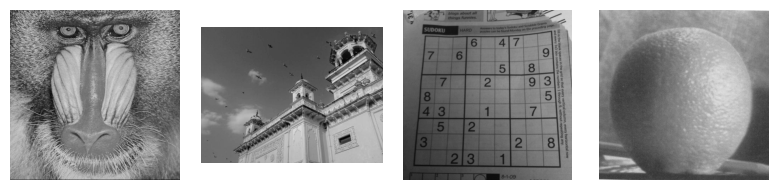

In [9]:
I = cv2.imread("images/baboon.jpg", cv2.IMREAD_GRAYSCALE)
Home = cv2.imread("images/home.jpg", cv2.IMREAD_GRAYSCALE)
Sudoku = cv2.imread("images/sudoku.png", cv2.IMREAD_GRAYSCALE)
Orange = cv2.imread("images/orange.jpg", cv2.IMREAD_GRAYSCALE)
IShow(I,Home,Sudoku,Orange)

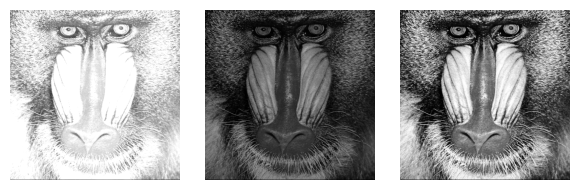

In [10]:
IShow(LnrOp(I,1.5,40),GmaCorc(I,2.2),EqHist(I))

## Demo 3a – Tích chập convolve2d, lọc hộp, Gaussian  _(Hồng Gấm)_

In [11]:
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

In [12]:

test_image = np.arange(1, 26, dtype=np.float64).reshape(5, 5)

test_kernel = np.array([
    [1, 2, 3],
    [0, 4, 5],
    [6, 7, 8]
], dtype=np.float64) / 36

border_types = {
    "constant": cv2.BORDER_CONSTANT,
    "reflect": cv2.BORDER_REFLECT_101,
    "edge": cv2.BORDER_REPLICATE
}

for padding, border in border_types.items():
    custom_result = convolve2d(
        test_image,
        test_kernel,
        padding
    )

    opencv_result = cv2.filter2D(
        test_image,
        ddepth=-1,
        kernel=np.flip(test_kernel, axis=(0, 1)),
        borderType=border
    )

    max_error = np.max(
        np.abs(custom_result - opencv_result)
    )

    print(f"{padding}: max error = {max_error:.12f}")

constant: max error = 0.000000000000
reflect: max error = 0.000000000000
edge: max error = 0.000000000000


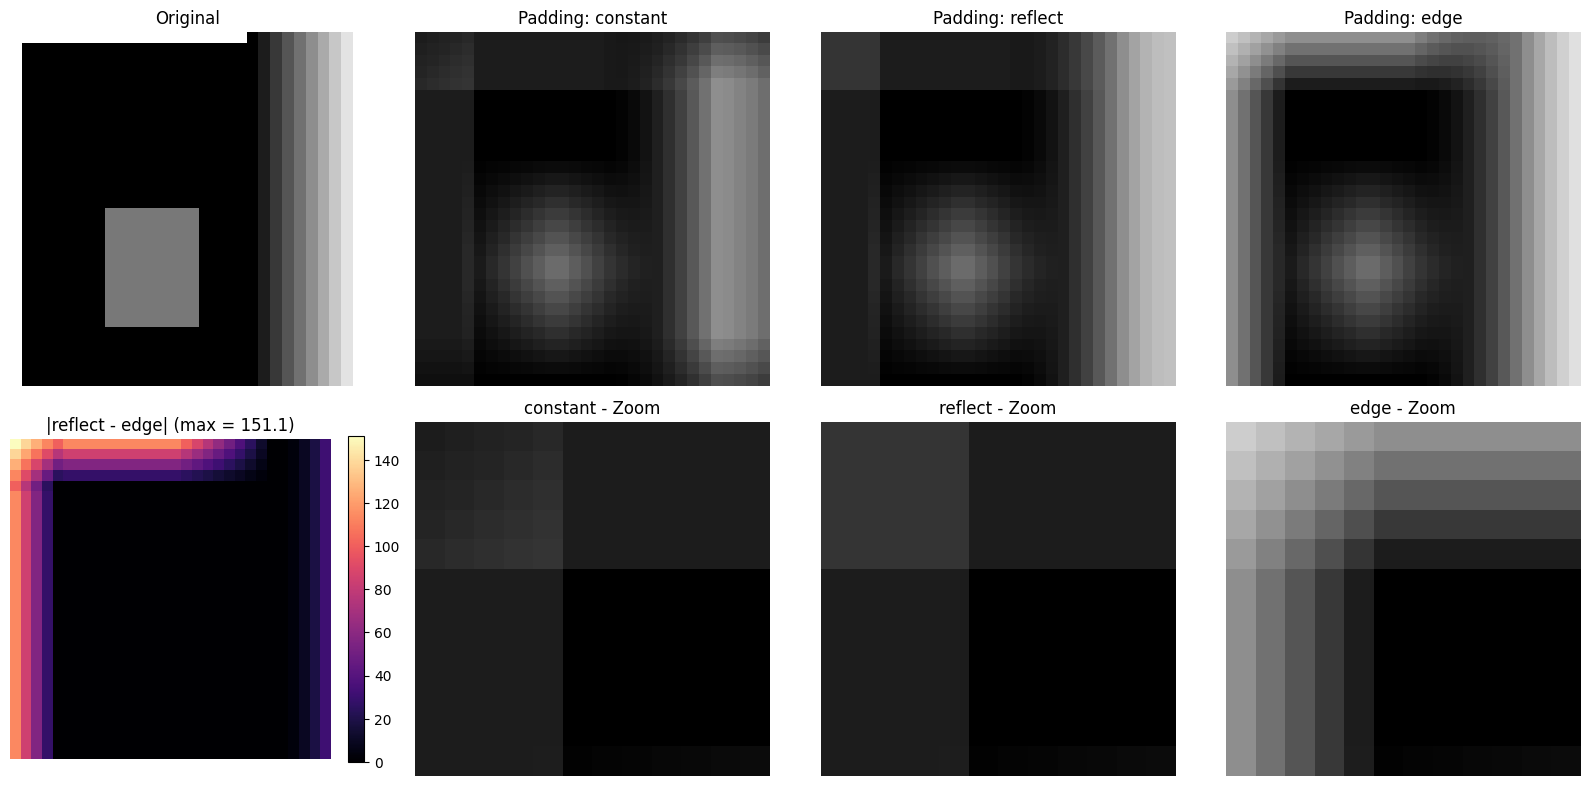

In [13]:
# Ảnh có biến đổi ngay sát mép: hàng/cột ở mép khác hẳn hàng/cột kế bên,
# nên reflect (lấy đối xứng bỏ qua pixel mép) và edge (lặp lại pixel mép) cho kết quả khác nhau
test_img = np.zeros((30, 30), dtype=np.float64)
test_img[0, :] = 255                                   # vạch sáng nằm đúng hàng mép trên
test_img[:, 0] = 255                                   # vạch sáng nằm đúng cột mép trái
test_img[:, 20:] = np.linspace(0, 255, 10)             # dải sáng dần ra mép phải
test_img[15:25, 8:16] = 120

kernel = np.ones((9, 9), dtype=np.float64) / 81

results = {
    mode: convolve2d(test_img, kernel, mode)
    for mode in ("constant", "reflect", "edge")
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].imshow(test_img, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

diff = np.abs(results["reflect"] - results["edge"])
im = axes[1, 0].imshow(diff, cmap="magma", interpolation="nearest")
axes[1, 0].set_title(f"|reflect - edge| (max = {diff.max():.1f})")
axes[1, 0].axis("off")
fig.colorbar(im, ax=axes[1, 0], fraction=0.046)

for col, (mode, result) in enumerate(results.items(), 1):
    axes[0, col].imshow(
        result,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[0, col].set_title(f"Padding: {mode}")
    axes[0, col].axis("off")

    axes[1, col].imshow(
        result[:12, :12],
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest"
    )
    axes[1, col].set_title(f"{mode} - Zoom")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

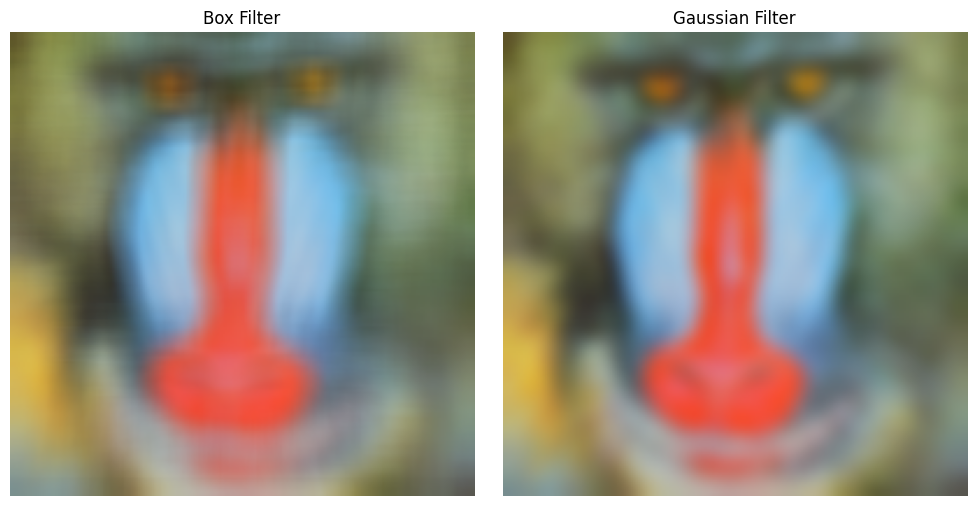

In [14]:

box_kernel = np.ones((15, 15), dtype=np.float64) / 225

g = cv2.getGaussianKernel(15, 4)
gaussian_kernel = g @ g.T

box_channels = [
    convolve2d(img[:, :, c], box_kernel, "reflect")
    for c in range(3)
]

gaussian_channels = [
    convolve2d(img[:, :, c], gaussian_kernel, "reflect")
    for c in range(3)
]

box_blur = np.clip(
    np.round(cv2.merge(box_channels)), 0, 255
).astype(np.uint8)

gaussian_blur = np.clip(
    np.round(cv2.merge(gaussian_channels)), 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(box_blur, cv2.COLOR_BGR2RGB))
axes[0].set_title("Box Filter")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(gaussian_blur, cv2.COLOR_BGR2RGB))
axes[1].set_title("Gaussian Filter")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [15]:

opencv_box = cv2.blur(img, (15, 15), borderType=cv2.BORDER_REFLECT_101)
opencv_gaussian = cv2.GaussianBlur(img, (15, 15), 4, borderType=cv2.BORDER_REFLECT_101)

box_error = np.max(np.abs(box_blur.astype(int) - opencv_box.astype(int)))
gaussian_error = np.max(np.abs(gaussian_blur.astype(int) - opencv_gaussian.astype(int)))

print(f"Box filter vs cv2.blur: max error = {box_error}")
print(f"Gaussian vs cv2.GaussianBlur: max error = {gaussian_error}")

Box filter vs cv2.blur: max error = 0
Gaussian vs cv2.GaussianBlur: max error = 1


In [16]:
cv2.imwrite(str(IMG_DIR / "box_blur.jpg"), box_blur)
cv2.imwrite(str(IMG_DIR / "gaussian_blur.jpg"), gaussian_blur)

True

## Demo 3b – Sobel, làm sắc nét  _(Tấn Lên)_

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

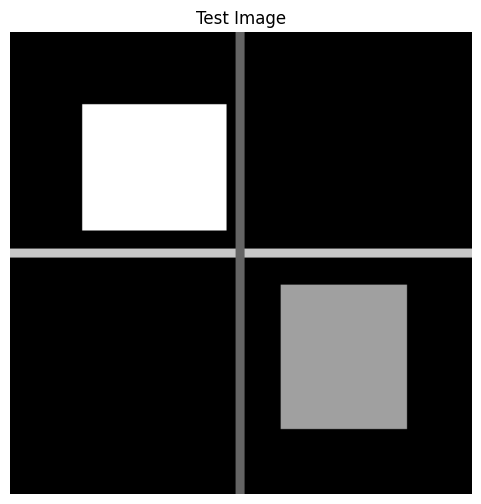

In [17]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [18]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


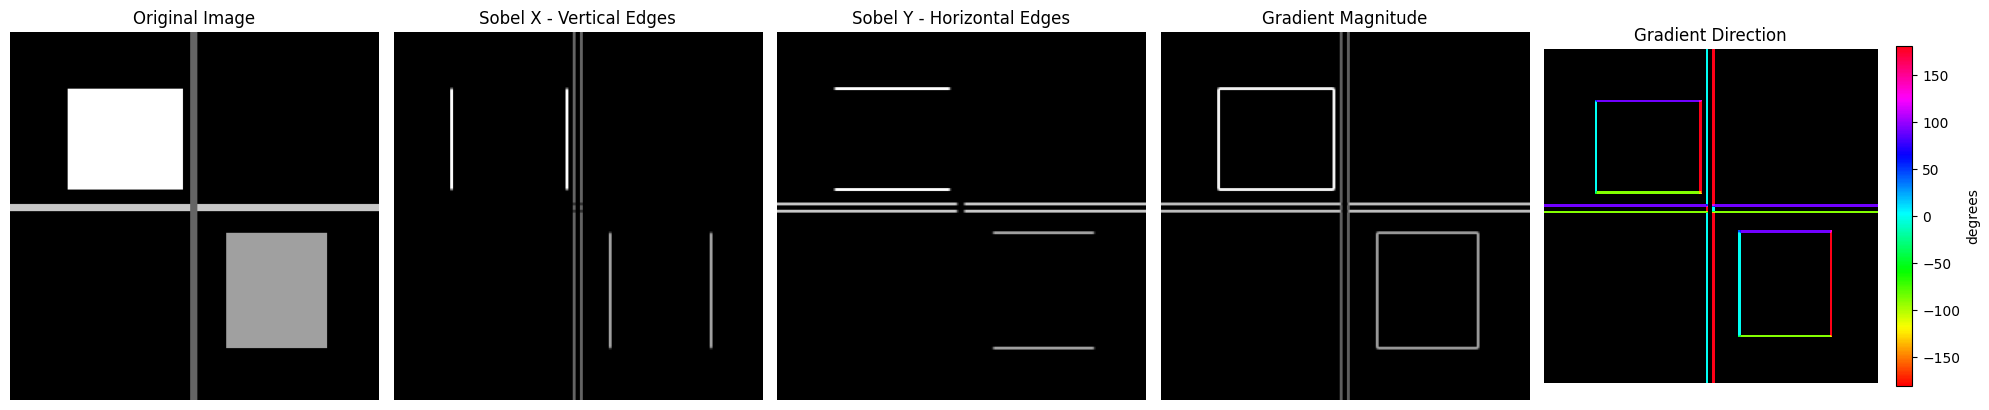

In [19]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

# Chỉ tô màu hướng ở pixel có cạnh; vùng phẳng (gx = gy = 0) để đen
direction_display = np.where(edge_magnitude > 0, edge_direction, np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")
im = axes[4].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[4].set_title("Gradient Direction")
fig.colorbar(im, ax=axes[4], fraction=0.046, label="degrees")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét Sobel:**
- Sobel X phản ứng với thay đổi cường độ theo chiều ngang nên chỉ hiện các **cạnh dọc** (mép trái/phải hình chữ nhật, vạch dọc); Sobel Y ngược lại chỉ hiện **cạnh ngang**.
- Độ lớn gradient $\sqrt{g_x^2 + g_y^2}$ gộp cả hai hướng nên ra đủ viền. Hình chữ nhật trắng (255) cho viền sáng hơn hình xám (160) vì bước nhảy cường độ lớn hơn.
- Hướng gradient chỉ từ tối sang sáng: mép trái hình sáng ≈ 0°, mép phải ≈ ±180°, mép trên ≈ −90°, mép dưới ≈ 90°. Vùng phẳng không có hướng nên để đen.

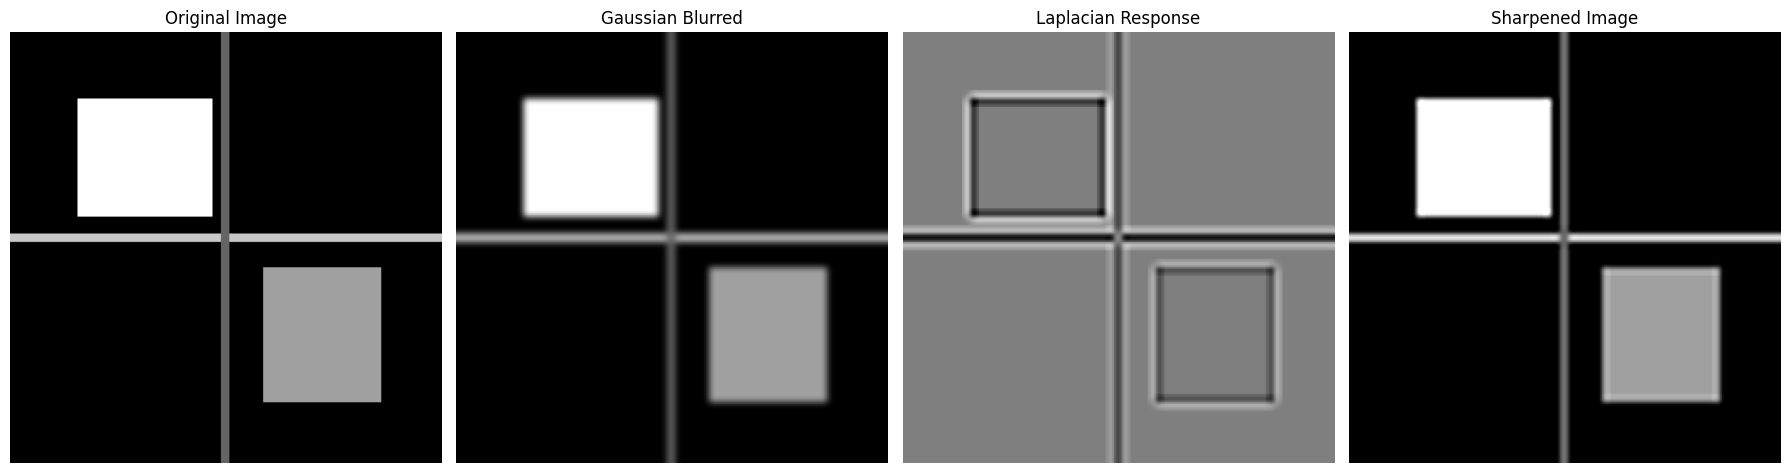

In [20]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Kernel Gauss tự viết, làm mờ bằng convolve2d của nhóm
def gaussian_kernel(size, sigma):
    r = size // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

# Blur the image first to make the sharpening effect more visible
img_blurred = convolve2d(
    img_float,
    gaussian_kernel(9, 2.0),
    padding="reflect"
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 3.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

# Kéo giãn quanh mức xám 127.5 theo giá trị tuyệt đối lớn nhất để thấy rõ viền
laplacian_display = np.clip(
    127.5 + 127.5 * laplacian / np.abs(laplacian).max(), 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

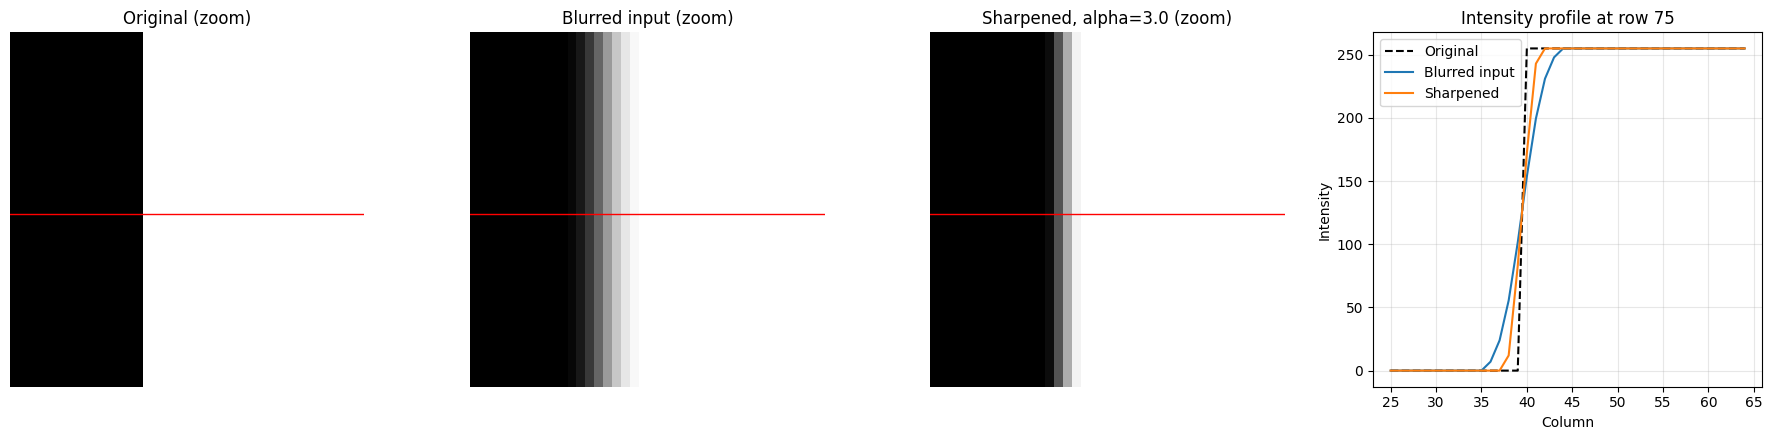

Edge width - blurred:   4 px
Edge width - sharpened: 2 px


In [21]:
# Phóng to vùng cạnh để so sánh gốc / mờ / sắc nét
r0, r1, c0, c1 = 55, 95, 25, 65   # vùng quanh cạnh trái của hình chữ nhật sáng
row = 75                          # hàng dùng để vẽ mặt cắt cường độ

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, im, title in zip(
    axes[:3],
    [img_demo, img_blurred_display, sharpened],
    ["Original (zoom)", "Blurred input (zoom)", f"Sharpened, alpha={alpha} (zoom)"]
):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.axhline(row - r0, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")

cols = np.arange(c0, c1)
axes[3].plot(cols, img_demo[row, c0:c1], "k--", label="Original")
axes[3].plot(cols, img_blurred[row, c0:c1], label="Blurred input")
axes[3].plot(cols, sharpened[row, c0:c1], label="Sharpened")
axes[3].set_xlabel("Column")
axes[3].set_ylabel("Intensity")
axes[3].set_title(f"Intensity profile at row {row}")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Độ rộng vùng chuyển (pixel có cường độ 10%–90%) càng nhỏ thì cạnh càng sắc
def edge_width(profile):
    return int(np.sum((profile > 25.5) & (profile < 229.5)))

print("Edge width - blurred:  ", edge_width(img_blurred[row, c0:c1]), "px")
print("Edge width - sharpened:", edge_width(sharpened[row, c0:c1]), "px")

**Nhận xét làm sắc nét:**
- Laplacian bằng 0 ở vùng phẳng và đổi dấu hai bên cạnh, nên $I - \alpha \nabla^2 I$ kéo phía tối tối hơn, phía sáng sáng hơn → cạnh dốc lại (độ rộng vùng chuyển giảm từ 4 px còn 2 px).
- Làm sắc nét không khôi phục được chi tiết đã mất do làm mờ, chỉ làm tăng tương phản tại cạnh. Với cạnh 0 → 255, phần vọt lố bị cắt ở 0 và 255 nên không thấy trên mặt cắt.
- $\alpha$ càng lớn cạnh càng sắc nhưng càng dễ sinh viền sáng/tối giả (vọt lố) và khuếch đại nhiễu.

In [22]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


## Demo 4 – Nhiễu, lọc trung vị  _(Hồng Sen)_

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

img_dir = Path("images") if Path("images").exists() else Path("../images")
img_dir.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)


def add_salt_pepper(img, amount):
    """Nhiễu muối-tiêu: tỉ lệ `amount` điểm ảnh bị đổi thành 0 hoặc 255 (mỗi loại một nửa)."""
    noisy = img.copy()
    u = rng.random(img.shape)
    noisy[u < amount / 2] = 0
    noisy[u > 1 - amount / 2] = 255
    return noisy


def add_gaussian_noise(img, sigma):
    """Cộng nhiễu N(0, sigma^2) rồi kẹp về [0, 255]."""
    noisy = img.astype(np.float64) + rng.normal(0, sigma, img.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)


def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)


def median_filter_3x3(img):
    """Lọc trung vị 3x3, đệm viền lặp lại (giống cv2.medianBlur).
    Xếp 9 lân cận của mọi điểm ảnh thành 9 lớp rồi lấy phần tử giữa (v5) theo trục lớp."""
    H, W = img.shape
    padded = np.pad(img, 1, mode="edge")
    stack = np.stack([padded[dy:dy + H, dx:dx + W] for dy in range(3) for dx in range(3)])
    return np.sort(stack, axis=0)[4].astype(img.dtype)


K_GAUSS = np.array([[1, 2, 1],
                    [2, 4, 2],
                    [1, 2, 1]], dtype=np.float64) / 16.0


def gaussian_filter_3x3(img):
    """Lọc Gaussian 3x3 (slide 49: K_G = 1/16 [1 2 1; 2 4 2; 1 2 1]), đệm viền lặp lại."""
    H, W = img.shape
    padded = np.pad(img, 1, mode="edge").astype(np.float64)
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(3):
        for dx in range(3):
            out += K_GAUSS[dy, dx] * padded[dy:dy + H, dx:dx + W]
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

In [24]:
# Ảnh thử trơn: mặt dốc độ sáng + một vùng sáng lồi mềm (không có cạnh gắt)
x = np.linspace(0, 1, 256)
yy, xx = np.mgrid[0:256, 0:256]
bump = 70 * np.exp(-((xx - 160) ** 2 + (yy - 100) ** 2) / (2 * 45 ** 2))
img_demo4 = np.clip(np.add.outer(x, x) * 70 + 50 + bump, 0, 255).astype(np.uint8)

# Ô đối chiếu: so với hàm của OpenCV
noisy = add_salt_pepper(img_demo4, 0.05)
err_med = np.abs(median_filter_3x3(noisy).astype(int) - cv2.medianBlur(noisy, 3).astype(int)).max()
err_gau = np.abs(gaussian_filter_3x3(noisy).astype(int) - cv2.GaussianBlur(noisy, (3, 3), 0, borderType=cv2.BORDER_REPLICATE).astype(int)).max()
print(f"median_filter_3x3   vs cv2.medianBlur  : sai khác lớn nhất = {err_med}")
print(f"gaussian_filter_3x3 vs cv2.GaussianBlur: sai khác lớn nhất = {err_gau}")

median_filter_3x3   vs cv2.medianBlur  : sai khác lớn nhất = 0
gaussian_filter_3x3 vs cv2.GaussianBlur: sai khác lớn nhất = 1


In [25]:
# Minh họa slide 58: một hàng có điểm nhiễu 255
row = np.array([[82, 80, 255, 81, 79, 83]], dtype=np.uint8)
row3 = np.repeat(row, 3, axis=0)          # 3 hàng giống nhau để có cửa sổ 3x3
print("Hàng có nhiễu :", row[0])
print("Sau Gaussian  :", gaussian_filter_3x3(row3)[1])
print("Sau trung vị  :", median_filter_3x3(row3)[1])

Hàng có nhiễu : [ 82  80 255  81  79  83]
Sau Gaussian  : [ 82 124 168 124  80  82]
Sau trung vị  : [82 82 81 81 81 83]


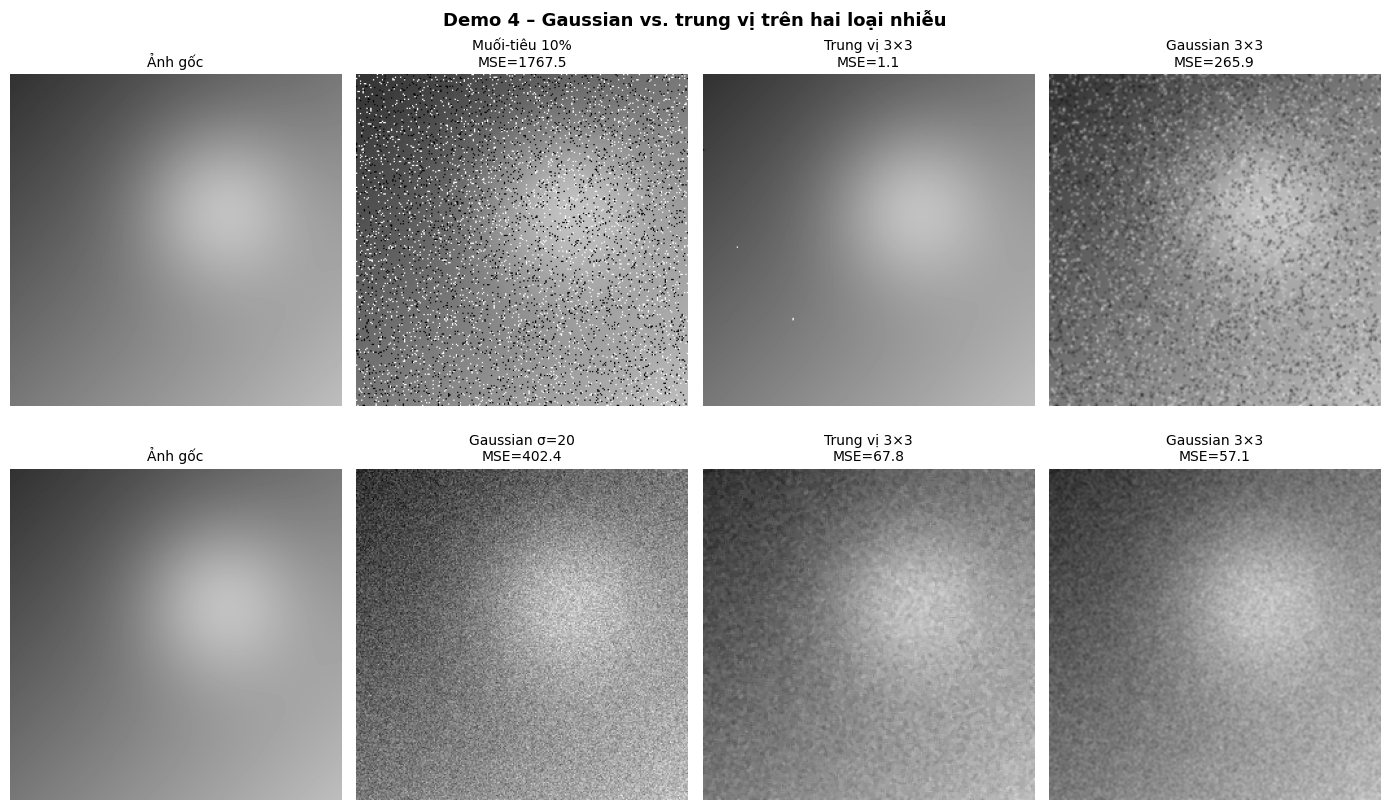

In [26]:
noisy_sp = add_salt_pepper(img_demo4, 0.10)
noisy_gs = add_gaussian_noise(img_demo4, 20)

cases = [
    ("Muối-tiêu 10%", noisy_sp),
    ("Gaussian σ=20", noisy_gs),
]

fig, axes = plt.subplots(2, 4, figsize=(14, 8.5))
for r, (name, noisy_img) in enumerate(cases):
    med = median_filter_3x3(noisy_img)
    gau = gaussian_filter_3x3(noisy_img)
    panels = [
        (img_demo4, "Ảnh gốc"),
        (noisy_img, f"{name}\nMSE={mse(img_demo4, noisy_img):.1f}"),
        (med, f"Trung vị 3×3\nMSE={mse(img_demo4, med):.1f}"),
        (gau, f"Gaussian 3×3\nMSE={mse(img_demo4, gau):.1f}"),
    ]
    for c, (im, title) in enumerate(panels):
        axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(title, fontsize=10)
        axes[r, c].axis("off")
fig.suptitle("Demo 4 – Gaussian vs. trung vị trên hai loại nhiễu", fontsize=13, fontweight="bold")
fig.tight_layout(h_pad=2.5)
fig.savefig(img_dir / "comparison_result.png", dpi=150, bbox_inches="tight")
plt.show()

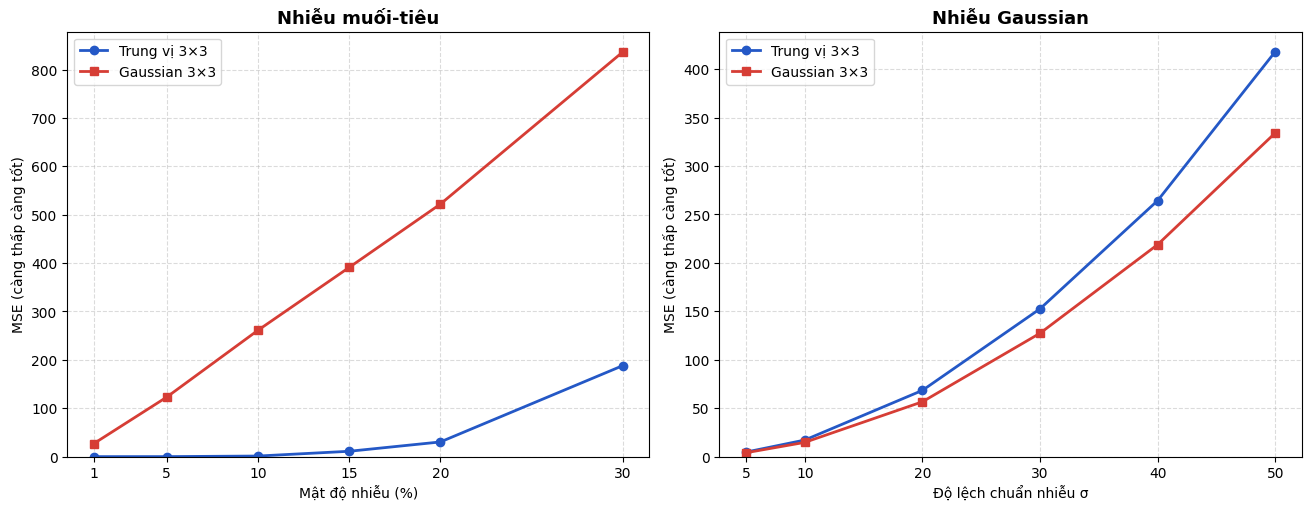

Muối-tiêu:
    1%: trung vị=     0.0  Gaussian=    26.7  -> trung vị thắng
    5%: trung vị=     0.0  Gaussian=   122.9  -> trung vị thắng
   10%: trung vị=     1.2  Gaussian=   261.0  -> trung vị thắng
   15%: trung vị=    11.1  Gaussian=   391.0  -> trung vị thắng
   20%: trung vị=    30.3  Gaussian=   521.9  -> trung vị thắng
   30%: trung vị=   188.2  Gaussian=   836.4  -> trung vị thắng
Nhiễu Gaussian:
  σ= 5: trung vị=     4.7  Gaussian=     4.0  -> Gaussian thắng
  σ=10: trung vị=    17.1  Gaussian=    14.7  -> Gaussian thắng
  σ=20: trung vị=    68.3  Gaussian=    56.6  -> Gaussian thắng
  σ=30: trung vị=   152.5  Gaussian=   127.3  -> Gaussian thắng
  σ=40: trung vị=   264.2  Gaussian=   218.8  -> Gaussian thắng
  σ=50: trung vị=   417.9  Gaussian=   334.0  -> Gaussian thắng


In [27]:
sp_levels = [0.01, 0.05, 0.10, 0.15, 0.20, 0.30]
sigmas = [5, 10, 20, 30, 40, 50]

sp_med, sp_gau = [], []
for amount in sp_levels:
    noisy_img = add_salt_pepper(img_demo4, amount)
    sp_med.append(mse(img_demo4, median_filter_3x3(noisy_img)))
    sp_gau.append(mse(img_demo4, gaussian_filter_3x3(noisy_img)))

gs_med, gs_gau = [], []
for sigma in sigmas:
    noisy_img = add_gaussian_noise(img_demo4, sigma)
    gs_med.append(mse(img_demo4, median_filter_3x3(noisy_img)))
    gs_gau.append(mse(img_demo4, gaussian_filter_3x3(noisy_img)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, title, xs, y_med, y_gau, xlabel in [
    (axes[0], "Nhiễu muối-tiêu", [a * 100 for a in sp_levels], sp_med, sp_gau, "Mật độ nhiễu (%)"),
    (axes[1], "Nhiễu Gaussian", sigmas, gs_med, gs_gau, "Độ lệch chuẩn nhiễu σ"),
]:
    ax.plot(xs, y_med, "o-", lw=2, color="#2458c6", label="Trung vị 3×3")
    ax.plot(xs, y_gau, "s-", lw=2, color="#d63d35", label="Gaussian 3×3")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("MSE (càng thấp càng tốt)")
    ax.set_xticks(xs)
    ax.set_ylim(bottom=0)
    ax.grid(True, ls="--", alpha=0.45)
    ax.legend(loc="upper left")
fig.savefig(img_dir / "MSE.png", dpi=200, bbox_inches="tight")
plt.show()

print("Muối-tiêu:")
for a, m, g in zip(sp_levels, sp_med, sp_gau):
    print(f"  {a:4.0%}: trung vị={m:8.1f}  Gaussian={g:8.1f}  -> {'trung vị' if m < g else 'Gaussian'} thắng")
print("Nhiễu Gaussian:")
for s, m, g in zip(sigmas, gs_med, gs_gau):
    print(f"  σ={s:2d}: trung vị={m:8.1f}  Gaussian={g:8.1f}  -> {'trung vị' if m < g else 'Gaussian'} thắng")

## Demo 5 – Xoay ảnh, warping ngược, nội suy  _(Tấn Hiệp)_

### Quy ước góc xoay

Slide 65 của Computer_Vision_18 dùng hệ tọa độ toán học, với trục y hướng lên. Trong ảnh, x hướng sang phải còn y hướng xuống. Để góc dương vẫn xoay ngược chiều kim đồng hồ khi nhìn ảnh, ma trận dùng `[[cos theta, sin theta], [-sin theta, cos theta]]`. Vì vậy dấu của hai phần tử sin khác slide; quy ước này cũng khớp với ô đối chiếu OpenCV bên dưới.


In [28]:
def tao_ban_co(kich_thuoc=200, o=25, sang=220, toi=60):
    ban_co = np.zeros((kich_thuoc, kich_thuoc), dtype=np.uint8)
    for y in range(kich_thuoc):
        for x in range(kich_thuoc):
            if (x // o + y // o) % 2 == 0:
                ban_co[y, x] = sang
            else:
                ban_co[y, x] = toi
    return ban_co


def ma_tran_xoay(goc_do, cx, cy):
    t = np.deg2rad(goc_do)
    c, s = np.cos(t), np.sin(t)

    T_ve_goc = np.array([[1, 0, -cx],
                         [0, 1, -cy],
                         [0, 0, 1]])
    R = np.array([[c, s, 0],
                  [-s, c, 0],
                  [0, 0, 1]])
    T_ve_tam = np.array([[1, 0, cx],
                         [0, 1, cy],
                         [0, 0, 1]])

    return T_ve_tam @ R @ T_ve_goc


ban_co = tao_ban_co()
h, w = ban_co.shape
cx, cy = (w - 1) / 2, (h - 1) / 2

M = ma_tran_xoay(30, cx, cy)
tam_sau_xoay = M @ np.array([cx, cy, 1])
print("Ma trận xoay 30 độ:\n", np.round(M, 3))
print(f"Tâm trước khi xoay: ({cx:.2f}, {cy:.2f})")
print(f"Tâm sau khi xoay:  ({tam_sau_xoay[0]:.2f}, {tam_sau_xoay[1]:.2f})")
print("Tâm không đổi:", "Có" if np.allclose(tam_sau_xoay[:2], [cx, cy]) else "Không")

Ma trận xoay 30 độ:
 [[  0.866   0.5   -36.42 ]
 [ -0.5     0.866  63.08 ]
 [  0.      0.      1.   ]]
Tâm trước khi xoay: (99.50, 99.50)
Tâm sau khi xoay:  (99.50, 99.50)
Tâm không đổi: Có


In [29]:
def lay_gan_nhat(anh, x, y):
    h, w = anh.shape
    xi = int(np.round(x))
    yi = int(np.round(y))
    if xi < 0 or xi >= w or yi < 0 or yi >= h:
        return 0.0
    return float(anh[yi, xi])


def lay_song_tuyen(anh, x, y):
    h, w = anh.shape
    eps = 1e-6
    if x < -eps or x > w - 1 + eps or y < -eps or y > h - 1 + eps:
        return 0.0

    x = min(max(x, 0.0), w - 1)
    y = min(max(y, 0.0), h - 1)

    x0 = int(np.floor(x))
    y0 = int(np.floor(y))
    x1 = min(x0 + 1, w - 1)
    y1 = min(y0 + 1, h - 1)

    dx = x - x0
    dy = y - y0

    Q11 = float(anh[y0, x0])
    Q21 = float(anh[y0, x1])
    Q12 = float(anh[y1, x0])
    Q22 = float(anh[y1, x1])

    R1 = (1 - dx) * Q11 + dx * Q21
    R2 = (1 - dx) * Q12 + dx * Q22
    P = (1 - dy) * R1 + dy * R2
    return P


def xoay_anh(anh, goc_do, kieu="song_tuyen"):
    if kieu == "gan_nhat":
        lay_mau = lay_gan_nhat
    elif kieu == "song_tuyen":
        lay_mau = lay_song_tuyen
    else:
        raise ValueError("kieu phải là 'gan_nhat' hoặc 'song_tuyen'")

    h, w = anh.shape
    M = ma_tran_xoay(goc_do, (w - 1) / 2, (h - 1) / 2)
    M_nguoc = np.linalg.inv(M)

    ket_qua = np.zeros((h, w), dtype=np.float64)
    for y_dich in range(h):
        for x_dich in range(w):
            x_nguon, y_nguon, _ = M_nguoc @ np.array([x_dich, y_dich, 1.0])
            ket_qua[y_dich, x_dich] = lay_mau(anh, x_nguon, y_nguon)

    return np.clip(np.round(ket_qua), 0, 255).astype(np.uint8)

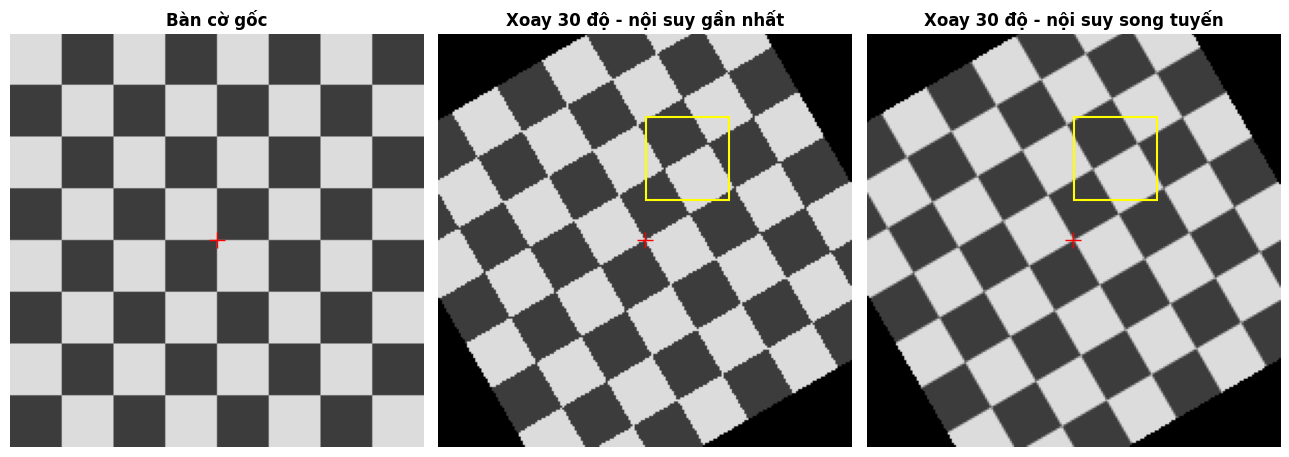

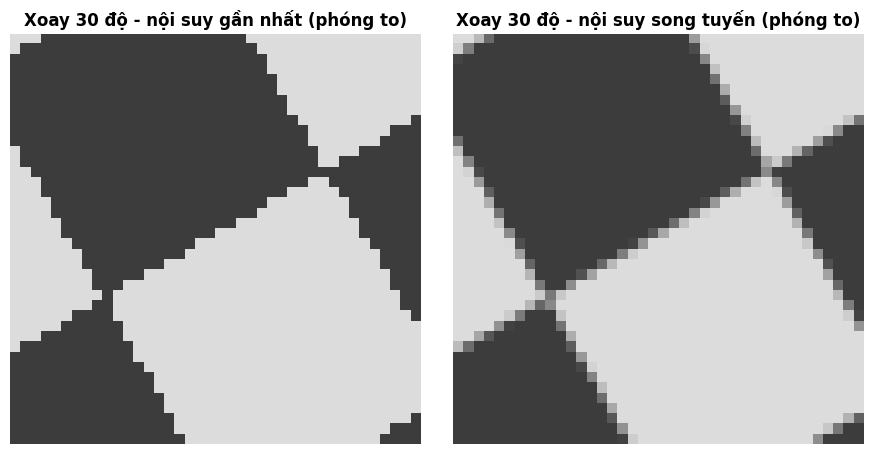

In [30]:
goc = 30
anh_gan_nhat = xoay_anh(ban_co, goc, "gan_nhat")
anh_song_tuyen = xoay_anh(ban_co, goc, "song_tuyen")

anh_list = [ban_co, anh_gan_nhat, anh_song_tuyen]
ten_list = ["Bàn cờ gốc", f"Xoay {goc} độ - nội suy gần nhất", f"Xoay {goc} độ - nội suy song tuyến"]

y1, y2, x1, x2 = 40, 80, 100, 140

plt.figure(figsize=(13, 4.5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(anh_list[i], cmap="gray", vmin=0, vmax=255)
    plt.plot(cx, cy, "r+", markersize=12)
    if i > 0:
        plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                          fill=False, edgecolor="yellow", linewidth=1.5))
    plt.title(ten_list[i], fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
for i in range(1, 3):
    plt.subplot(1, 2, i)
    plt.imshow(anh_list[i][y1:y2, x1:x2], cmap="gray", vmin=0, vmax=255,
               interpolation="nearest")
    plt.title(ten_list[i] + " (phóng to)", fontsize=12, fontweight="bold")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Ô đối chiếu thư viện (chỉ ở đây mới gọi `cv2.getRotationMatrix2D`, `cv2.warpAffine`)

### Có dùng AI hỗ trợ

Công cụ: Codex (OpenAI)

Mục đích: Dựng khung đối chiếu ma trận xoay và kết quả nội suy gần nhất, song tuyến với OpenCV.

Prompt:
> Viết giúp tôi ô so sánh ma trận xoay và hai ảnh xoay gần nhất, song tuyến của tôi với OpenCV. In ra ma trận có khớp không và sai lệch trung bình của hai ảnh. Giữ nguyên các hàm tôi đã viết.

Đã sửa lại những gì: Chưa chỉnh sửa thêm. Giữ nguyên các hàm đã viết, chỉ dùng OpenCV để đối chiếu kết quả.


In [31]:
M_cv = cv2.getRotationMatrix2D((cx, cy), goc, 1.0)
cv_gan_nhat = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_NEAREST)
cv_song_tuyen = cv2.warpAffine(ban_co, M_cv, (w, h), flags=cv2.INTER_LINEAR)

print("Ma trận tự xây trùng với OpenCV:", "Có" if np.allclose(ma_tran_xoay(goc, cx, cy)[:2], M_cv) else "Không")
print("Gần nhất   - sai lệch trung bình so với OpenCV:",
      round(np.mean(np.abs(anh_gan_nhat.astype(int) - cv_gan_nhat)), 4))
print("Song tuyến - sai lệch trung bình so với OpenCV:",
      round(np.mean(np.abs(anh_song_tuyen.astype(int) - cv_song_tuyen)), 4))

Ma trận tự xây trùng với OpenCV: Có
Gần nhất   - sai lệch trung bình so với OpenCV: 0.0
Song tuyến - sai lệch trung bình so với OpenCV: 0.6021


### Có dùng AI hỗ trợ

Công cụ: Codex (OpenAI)

Mục đích: Kiểm thử các góc xoay đặc biệt và kiểm tra lỗ bên trong ảnh khi xoay 30 độ.

Prompt:
> Dùng hàm xoay_anh mình đã viết để thử các góc 0, 90, 180, 270 và 360 độ với cả gần nhất và song tuyến. Thử trên ảnh sáng đều để đếm xem có pixel đen nào không, rồi so ảnh bàn cờ sau xoay với np.rot90. In kết quả từng góc giúp mình, giữ nguyên hàm xoay nhé.

Đã sửa lại những gì: Bổ sung phép thử 30 độ trên ảnh sáng đều; chỉ kiểm tra vùng có tọa độ nguồn nằm trong ảnh, không tính nền đen ngoài ảnh xoay.


In [32]:
anh_sang = np.full((200, 200), 200, dtype=np.uint8)

ten_kieu = {"gan_nhat": "gần nhất", "song_tuyen": "song tuyến"}

for goc_thu, k in [(0, 0), (90, 1), (180, 2), (270, 3), (360, 0)]:
    for kieu in ["gan_nhat", "song_tuyen"]:
        kq_sang = xoay_anh(anh_sang, goc_thu, kieu)
        kq_ban_co = xoay_anh(ban_co, goc_thu, kieu)
        so_den = int(np.sum(kq_sang == 0))
        dung_rot90 = np.array_equal(kq_ban_co, np.rot90(ban_co, k))
        ket_luan = "Có" if dung_rot90 else "Không"
        print(f"{goc_thu:3d} độ {ten_kieu[kieu]:10s}: {so_den} pixel đen, "
              f"trùng với np.rot90 (k={k}): {ket_luan}")

# Chỉ đếm lỗ ở vùng ánh xạ về bên trong ảnh nguồn.
goc_thu = 30
hs, ws = anh_sang.shape
cxs, cys = (ws - 1) / 2, (hs - 1) / 2
yd, xd = np.indices(anh_sang.shape)
c, s = np.cos(np.deg2rad(goc_thu)), np.sin(np.deg2rad(goc_thu))
xn = c * (xd - cxs) - s * (yd - cys) + cxs
yn = s * (xd - cxs) + c * (yd - cys) + cys
vung_trong = (xn >= 0) & (xn <= ws - 1) & (yn >= 0) & (yn <= hs - 1)
print(f"\nXoay 30 độ: kiểm tra {vung_trong.sum()} pixel có tọa độ nguồn nằm trong ảnh.")
for kieu in ["gan_nhat", "song_tuyen"]:
    kq_30 = xoay_anh(anh_sang, goc_thu, kieu)
    so_lo = int(np.count_nonzero(kq_30[vung_trong] == 0))
    giu_muc_sang = bool(np.all(kq_30[vung_trong] == 200))
    print(f"30 độ {ten_kieu[kieu]:10s}: {so_lo} lỗ bên trong, giữ mức sáng 200: {giu_muc_sang}")
    assert so_lo == 0 and giu_muc_sang, f"Xoay 30 độ chưa đạt: {kieu}"


  0 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=0): Có
  0 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=0): Có
 90 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=1): Có
 90 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=1): Có
180 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=2): Có
180 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=2): Có
270 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=3): Có
270 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=3): Có
360 độ gần nhất  : 0 pixel đen, trùng với np.rot90 (k=0): Có
360 độ song tuyến: 0 pixel đen, trùng với np.rot90 (k=0): Có

Xoay 30 độ: kiểm tra 33640 pixel có tọa độ nguồn nằm trong ảnh.
30 độ gần nhất  : 0 lỗ bên trong, giữ mức sáng 200: True
30 độ song tuyến: 0 lỗ bên trong, giữ mức sáng 200: True


### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Hỗ trợ phần lưu ảnh của thí nghiệm xoay: đổi cv2.imwrite sang plt.imsave.

Prompt:
> Đổi giúp mình phần lưu hai ảnh xoay từ cv2.imwrite sang plt.imsave, lưu vào thư mục images với tên xoay_gan_nhat.png và xoay_song_tuyen.png. Giữ ảnh xám đúng thang 0-255 và in thông báo sau khi lưu. Không đổi phần tính ảnh xoay của mình nhé.

Đã sửa lại những gì: Chưa chỉnh sửa thêm, chỉ đổi cách lưu hai ảnh sang plt.imsave.


In [33]:
plt.imsave("images/xoay_gan_nhat.png", anh_gan_nhat, cmap="gray", vmin=0, vmax=255)
plt.imsave("images/xoay_song_tuyen.png", anh_song_tuyen, cmap="gray", vmin=0, vmax=255)
print("Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png")

Đã lưu: ../images/xoay_gan_nhat.png, ../images/xoay_song_tuyen.png


# KỸ THUẬT 1 – CLAHE  _(Huỳnh Nam)_

## Hàm tự viết

In [34]:
def Climit(I,S,Gr=(8,8)):
    L=256
    H,W = I.shape
    N = (-(-H // Gr[0])) * (-(-W // Gr[1]))
    return S * N / L

def clip_histogram(hist, clip_limit):
    B = clip_limit
    H = hist
    L = 256
    E = np.maximum(H-B,0)
    H = np.minimum(H,B)
    E_T = E.sum()
    H = H + (E_T / L)
    return H

def build_tile_luts(img, grid=(8, 8), clip_limit=2.0):
    I = img
    Gy,Gx= grid
    L = 256
    h,w = I.shape
    Th = -(-h//Gy) 
    Tw = -(-w//Gx)
    pad = np.pad(I, ((0, Gy * Th - h), (0, Gx * Tw - w)), mode='reflect')
    n_tile =Th*Tw
    B = Climit(I,clip_limit,grid)
    T = np.empty((Gy, Gx, L), dtype=np.uint8)
    for i in range(Gy):
        for j in range(Gx):
            tile = pad[i * Th:(i + 1) * Th, j * Tw:(j + 1) * Tw]
            H = clip_histogram(Hist(tile),B)
            lut = (L - 1) / n_tile * np.cumsum(H)
            T[i, j] = np.clip(np.round(lut), 0, L - 1).astype(np.uint8)
    return T
def clahe(img, grid=(8, 8), clip_limit=2.0):
    I=img
    Gy, Gx = grid
    T = build_tile_luts(I, grid, clip_limit)
    h, w = img.shape
    Th, Tw = -(-h // Gy), -(-w // Gx) 
    fy = np.clip((np.arange(h) + 0.5) / Th - 0.5, 0, Gy - 1)
    fx = np.clip((np.arange(w) + 0.5) / Tw - 0.5, 0, Gx - 1)
    i0 = np.floor(fy).astype(int); i1 = np.minimum(i0 + 1, Gy - 1)
    j0 = np.floor(fx).astype(int); j1 = np.minimum(j0 + 1, Gx - 1)
    b = (fy - i0)[:, None]
    a = (fx - j0)[None, :]

    I0, I1 = i0[:, None], i1[:, None]
    J0, J1 = j0[None, :], j1[None, :]
    Q11, Q21 = T[I0, J0, I], T[I0, J1, I]
    Q12, Q22 = T[I1, J0, I], T[I1, J1, I] 
    G = Blnr(Q11, Q21, Q12, Q22, a, b)
    return np.clip(np.round(G),0,255).astype(np.uint8)
    

## Ô đối chiếu thư viện (chỉ ở đây mới được gọi hàm bị cấm)

## Thí nghiệm

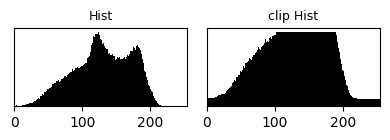

In [36]:
HShow(Hist(I),clip_histogram(Hist(I),Climit(I,1.5,(1,1))),T=['Hist','clip Hist'])

### Có dùng AI hỗ trợ
Công cụ: Claude (Anthropic), mô hình Claude Opus 5.5, qua claude.ai
Mục đích: chọn ảnh thử phù hợp, chọn tham số

Prompt:
> chọn ảnh để clahe thắng và thua
> chọn tham số như thế nào ?
Đã sửa lại những gì: Sửa lại gamma để trông nó làm rõ sáng tối hơn

a


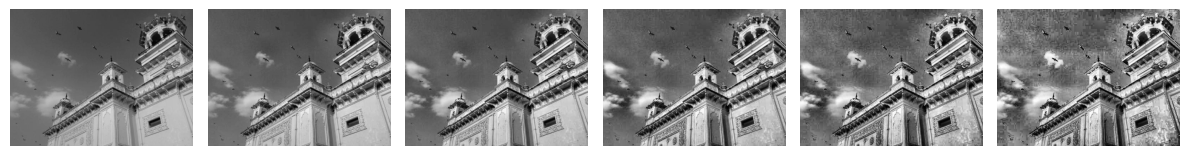

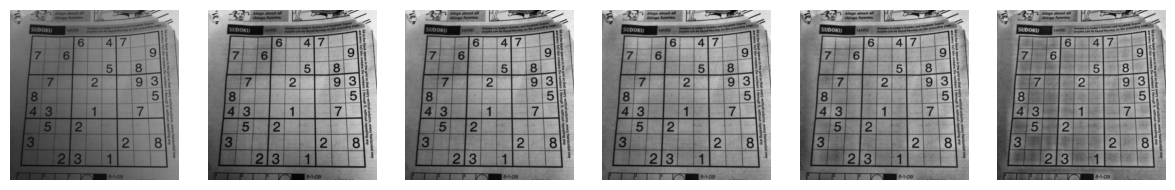

b
Với ảnh Clahe thắng


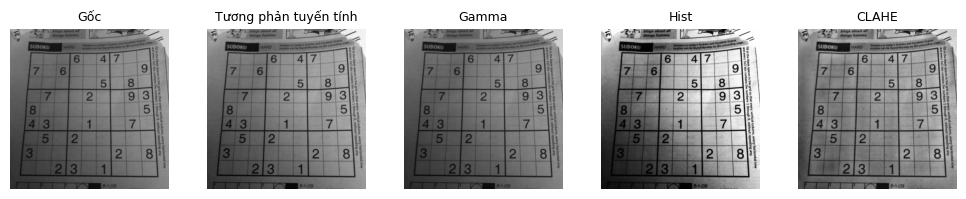

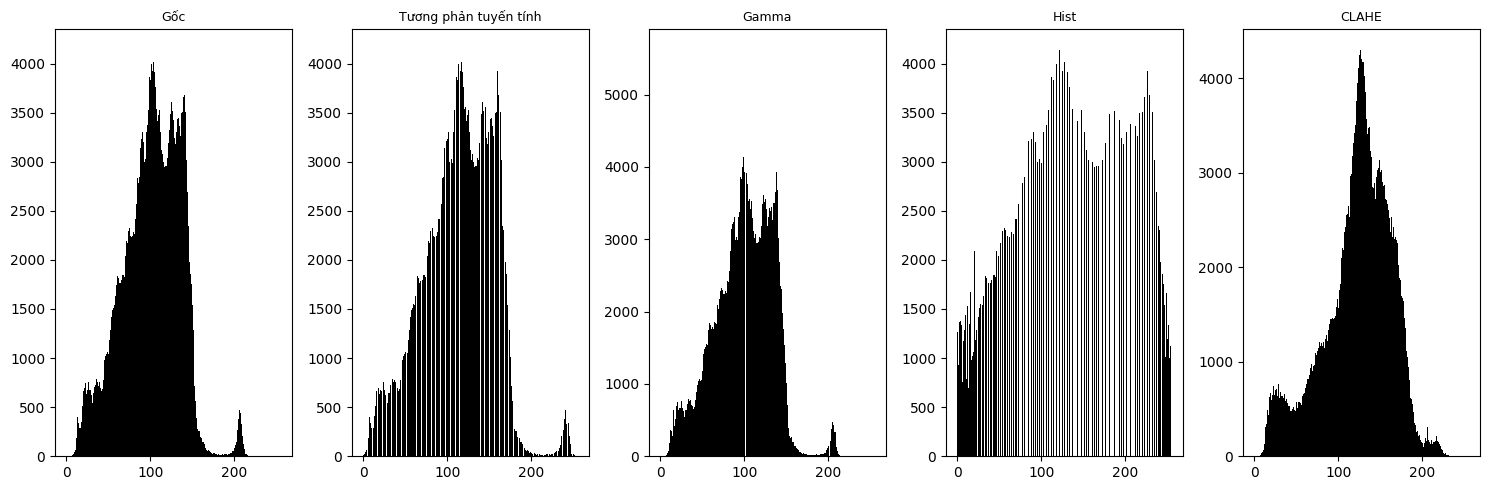

Với CLAHE thua


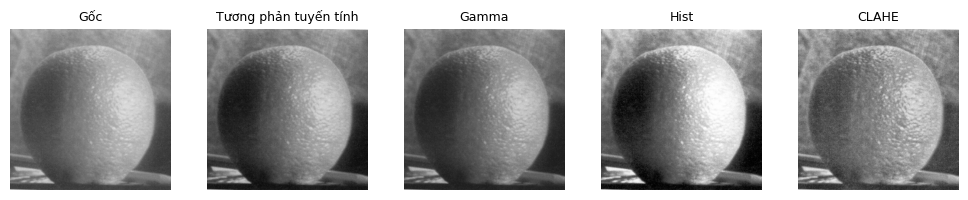

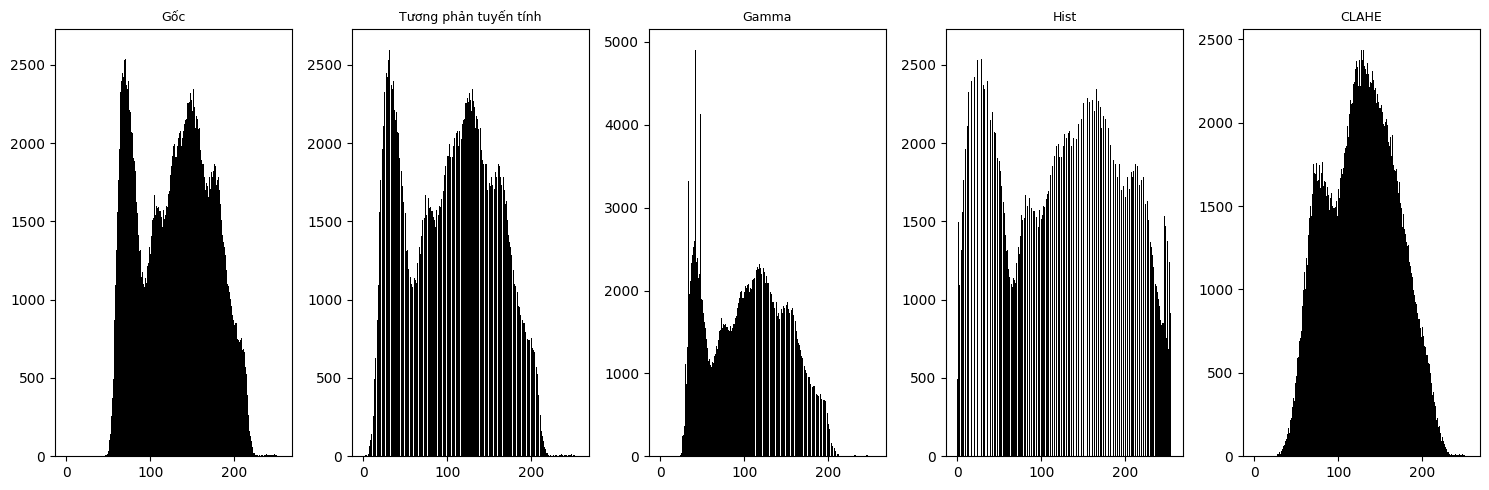

In [37]:
"""A """
print("a")
IShow(Home,*[clahe(Home, (8, 8), s) for s in [1, 2, 5, 10, 20]])
IShow(Sudoku, *[clahe(Sudoku, g, 2)   for g in [(2, 2), (4, 4), (8, 8), (16, 16),(32, 32)]])
"""B"""
print("b")
print("Với ảnh Clahe thắng")
Title = ['Gốc','Tương phản tuyến tính','Gamma','Hist','CLAHE']
lo, hi = Sudoku.min(), Sudoku.max() 
A = 255 / (hi - lo); B = -A * lo          
Gma = np.log(0.4) / np.log(np.median(Sudoku) / 255) 
Img = Sudoku
IShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
LShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
print("Với CLAHE thua")
lo, hi = Orange.min(), Orange.max() 
A = 255 / (hi - lo); B = -A * lo          
Gma = np.log(0.4) / np.log(np.median(Orange) / 255) 
Img = Orange
IShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)
LShow(Img,LnrOp(Img,A,B),GmaCorc(Img,Gma),EqHist(Img),clahe(Img,(16, 16),1.5),T = Title)


# KỸ THUẬT 2 – Ngưỡng thích nghi bằng ảnh tích phân  _(Hồng Sen)_

## Hàm tự viết

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Hỗ trợ tối ưu hóa cấu trúc code khảo sát tham số r, t (Bradley) và quét tham số k (Sauvola).

integral_image == cv2.integral: True
local_mean sai khác lớn nhất so với cv2.blur: 2.842170943040401e-14


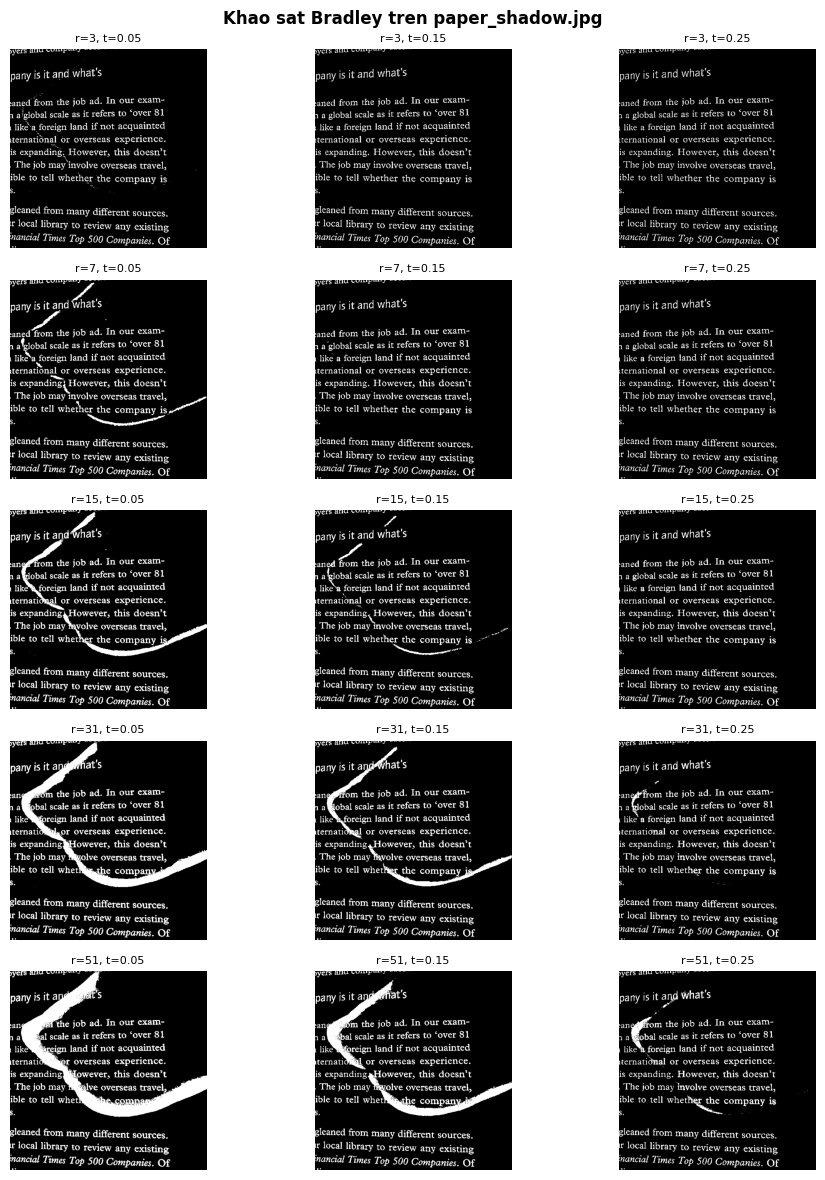

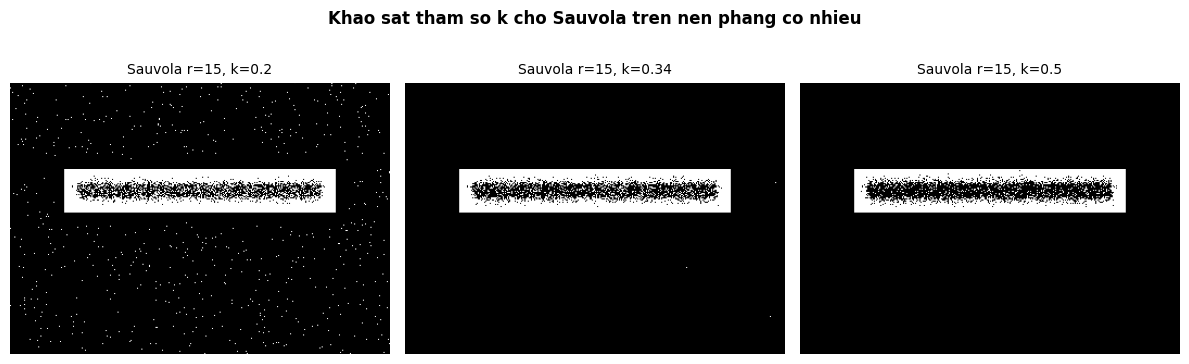

In [38]:
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

img_dir = Path("images") if Path("images").exists() else Path("../images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    dtype = np.float64 if np.issubdtype(img.dtype, np.floating) else np.int64
    S = np.zeros((H + 1, W + 1), dtype=dtype)
    S[1:, 1:] = np.cumsum(np.cumsum(img, axis=0, dtype=dtype), axis=1, dtype=dtype)
    return S

def box_sum(S, y1, x1, y2, x2):
    """Tổng vùng [y1..y2, x1..x2] (bao gồm biên) theo ảnh tích phân S có đệm viền.
    Các chỉ số có thể là số nguyên hoặc mảng numpy (vectơ hóa)."""
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    padded = np.pad(img, radius, mode='edge').astype(np.int64)
    S1 = integral_image(padded)
    S2 = integral_image(padded * padded)
    # Cửa sổ quanh điểm (y, x) của ảnh gốc là [y..y+2r, x..x+2r] trên ảnh đã đệm
    ys = np.arange(H)[:, None]
    xs = np.arange(W)[None, :]
    sum1 = box_sum(S1, ys, xs, ys + 2 * radius, xs + 2 * radius).astype(np.float64)
    sum2 = box_sum(S2, ys, xs, ys + 2 * radius, xs + 2 * radius).astype(np.float64)
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34, R=128.0):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    mean, std = local_mean_std(img, radius)
    img_f = img.astype(np.float64)
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
    binary = np.where(img_f < T, 255, 0).astype(np.uint8)
    return binary

# Ô đối chiếu: so với cv2.integral
_test = np.random.randint(0, 256, (60, 80), dtype=np.uint8)
print("integral_image == cv2.integral:", np.array_equal(integral_image(_test), cv2.integral(_test).astype(np.int64)))
_m, _ = local_mean_std(_test, 3)
print("local_mean sai khác lớn nhất so với cv2.blur:",
      np.abs(_m - cv2.blur(_test.astype(np.float64), (7, 7), borderType=cv2.BORDER_REPLICATE)).max())

# 1. Khảo sát Bradley trên ảnh bóng mờ (paper_shadow.jpg) từ repo
shadow_path = img_dir / "paper_shadow.jpg"
if shadow_path.exists():
    shadow_img = cv2.imread(str(shadow_path), cv2.IMREAD_GRAYSCALE)
    radii_sweep = [3, 7, 15, 31, 51]
    t_sweep = [0.05, 0.15, 0.25]
    
    fig, axes = plt.subplots(len(radii_sweep), len(t_sweep), figsize=(10, 12))
    for i, r in enumerate(radii_sweep):
        for j, t_val in enumerate(t_sweep):
            res = adaptive_threshold(shadow_img, radius=r, method='bradley', t=t_val)
            axes[i, j].imshow(res, cmap='gray', vmin=0, vmax=255)
            axes[i, j].set_title(f"r={r}, t={t_val}", fontsize=8)
            axes[i, j].axis('off')
    plt.suptitle("Khao sat Bradley tren paper_shadow.jpg", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# 2. Tạo ảnh nền phẳng rộng có nhiễu và quét tham số k cho Sauvola (>= 3 giá trị)
np.random.seed(42)
flat_img = np.ones((250, 350), dtype=np.uint8) * 200
flat_img[80:120, 50:300] = 40
noise = np.random.normal(0, 15, flat_img.shape).astype(np.int32)
flat_noisy = np.clip(flat_img.astype(np.int32) + noise, 0, 255).astype(np.uint8)

k_sweep = [0.2, 0.34, 0.5]
fig, axes = plt.subplots(1, len(k_sweep), figsize=(12, 4))
for j, k_val in enumerate(k_sweep):
    res_s = adaptive_threshold(flat_noisy, radius=15, method='sauvola', k=k_val)
    axes[j].imshow(res_s, cmap='gray', vmin=0, vmax=255)
    axes[j].set_title(f"Sauvola r=15, k={k_val}", fontsize=10)
    axes[j].axis('off')
plt.suptitle("Khao sat tham so k cho Sauvola tren nen phang co nhieu", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Ô đối chiếu thư viện (chỉ ở đây mới được gọi hàm bị cấm)

## Thí nghiệm

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Hỗ trợ so sánh trực quan 4 phương pháp ngưỡng hóa trên ảnh bóng mờ và ảnh nền phẳng có nhiễu.

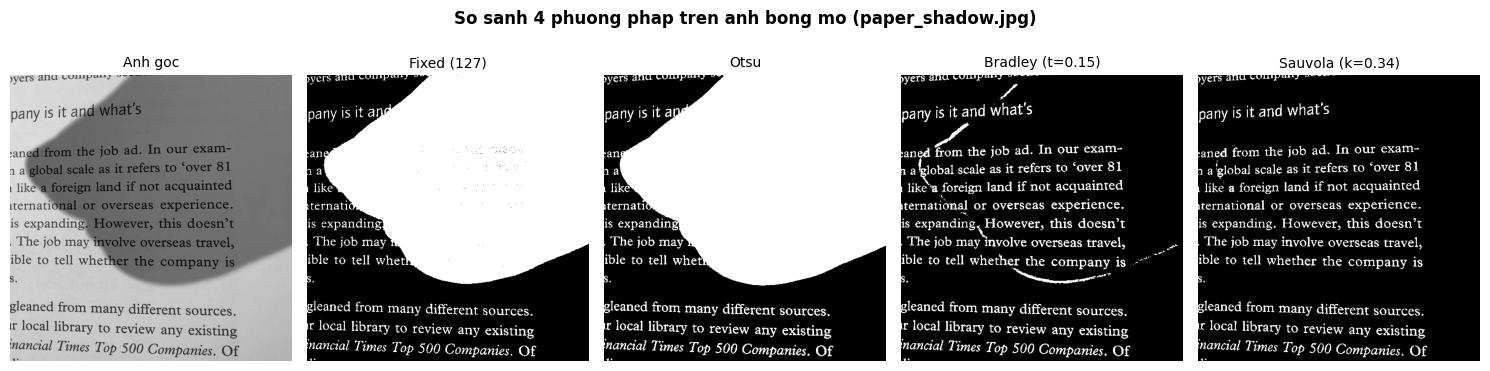

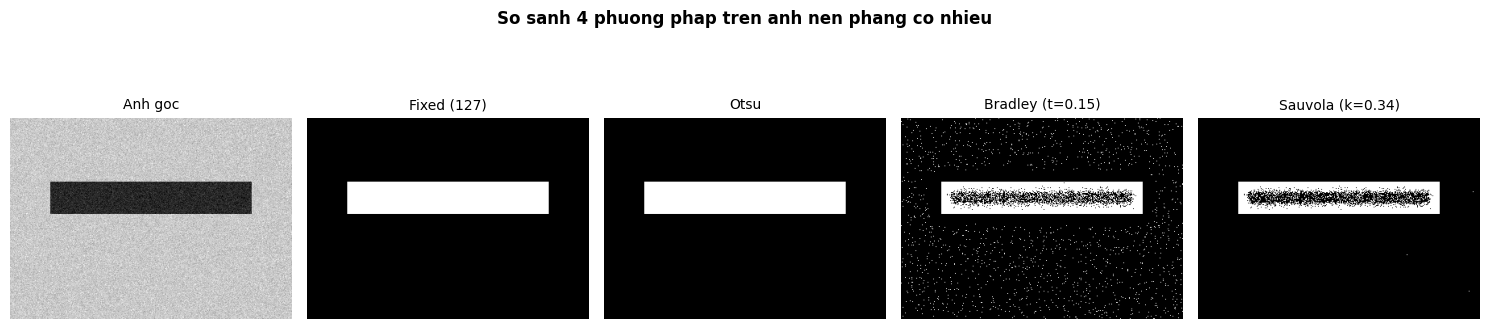

In [40]:
def manual_fixed_threshold(img, thresh=127):
    return np.where(img.astype(np.float64) < thresh, 255, 0).astype(np.uint8)

def manual_otsu_threshold(img):
    _, res = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return res

methods_titles = ["Anh goc", "Fixed (127)", "Otsu", "Bradley (t=0.15)", "Sauvola (k=0.34)"]

# A. So sánh 4 phương pháp trên ảnh bóng mờ (paper_shadow.jpg)
if shadow_path.exists():
    s_img = cv2.imread(str(shadow_path), cv2.IMREAD_GRAYSCALE)
    images_shadow = [
        s_img,
        manual_fixed_threshold(s_img, 127),
        manual_otsu_threshold(s_img),
        adaptive_threshold(s_img, radius=15, method='bradley', t=0.15),
        adaptive_threshold(s_img, radius=15, method='sauvola', k=0.34)
    ]
    
    fig, axes = plt.subplots(1, 5, figsize=(15, 4))
    for ax, img_item, title in zip(axes, images_shadow, methods_titles):
        ax.imshow(img_item, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.suptitle("So sanh 4 phuong phap tren anh bong mo (paper_shadow.jpg)", fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# B. So sánh 4 phương pháp trên ảnh nền phẳng có nhiễu
images_flat = [
    flat_noisy,
    manual_fixed_threshold(flat_noisy, 127),
    manual_otsu_threshold(flat_noisy),
    adaptive_threshold(flat_noisy, radius=15, method='bradley', t=0.15),
    adaptive_threshold(flat_noisy, radius=15, method='sauvola', k=0.34)
]

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, img_item, title in zip(axes, images_flat, methods_titles):
    ax.imshow(img_item, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
plt.suptitle("So sanh 4 phuong phap tren anh nen phang co nhieu", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Có dùng AI hỗ trợ
Công cụ: Google Gemini
Mục đích: Hỗ trợ cấu hình biểu đồ độ phức tạp thời gian chạy thang log.

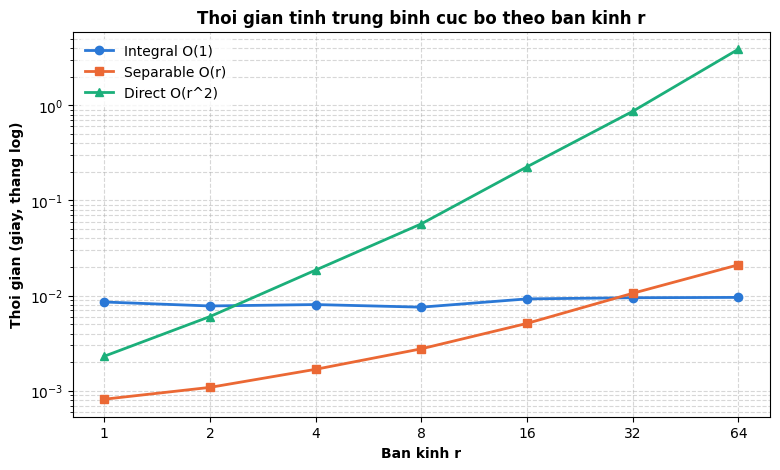

In [41]:
import time

def separable_filter_1d_numpy(img, radius):
    w = 2 * radius + 1
    H, W = img.shape
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    rows = np.zeros((H + 2 * radius, W), dtype=np.float64)
    for dx in range(w):
        rows += padded[:, dx:dx + W]
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(w):
        out += rows[dy:dy + H, :]
    return out / (w * w)

def box_filter_direct(img, kernel):
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float64)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for dy in range(h_k):
        for dx in range(w_k):
            out += kernel[dy, dx] * padded[dy:dy + H, dx:dx + W]
    return out

def bench(fn, repeat=3):
    best = float('inf')
    for _ in range(repeat):
        start = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - start)
    return best

radii_list = [1, 2, 4, 8, 16, 32, 64]
dummy_img = np.random.randint(0, 256, (512, 512), dtype=np.uint8)

t_integral, t_separable, t_direct = [], [], []
for r in radii_list:
    w = 2 * r + 1
    kernel_2d = np.ones((w, w), dtype=np.float64) / (w * w)
    t_integral.append(bench(lambda: local_mean_std(dummy_img, radius=r), 3))
    t_separable.append(bench(lambda: separable_filter_1d_numpy(dummy_img, radius=r), 3))
    t_direct.append(bench(lambda: box_filter_direct(dummy_img, kernel_2d), 1 if r > 16 else 2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(radii_list, t_integral, marker='o', label='Integral O(1)', color='#2a78d6', linewidth=2)
ax.plot(radii_list, t_separable, marker='s', label='Separable O(r)', color='#eb6834', linewidth=2)
ax.plot(radii_list, t_direct, marker='^', label='Direct O(r^2)', color='#1baf7a', linewidth=2)

ax.set_xscale('log', base=2)
ax.set_yscale('log')
ax.set_xticks(radii_list)
ax.set_xticklabels([str(r) for r in radii_list])
ax.set_xlabel('Ban kinh r', fontweight='bold')
ax.set_ylabel('Thoi gian (giay, thang log)', fontweight='bold')
ax.set_title('Thoi gian tinh trung binh cuc bo theo ban kinh r', fontweight='bold')
ax.legend(loc="upper left", frameon=True, facecolor='white', edgecolor='none')
ax.grid(True, which="both", ls="--", alpha=0.5)

chart_path = img_dir / "time_complexity.png"
fig.savefig(str(chart_path), dpi=300, bbox_inches='tight')
plt.show()

## KT2 (c) - Đo thời gian 3 cách tính trung bình cục bộ

Tích chập trực tiếp, tách 2 lần 1 chiều, ảnh tích phân; r = 1, 2, 4, 8, 16, 32, 64; ảnh `images/paper_shadow.jpg`.

In [42]:
from pathlib import Path

thu_muc = Path.cwd()
if not (thu_muc / "len.ipynb").is_file():
    thu_muc = thu_muc / "lam_viec"


### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung thí nghiệm KT2(c): nạp hàm của nhóm, kiểm tra kết quả tương đương và đo thời gian ba cách tính trung bình cục bộ theo bán kính r.

Prompt:
> Dùng hàm convolve2d của Gấm và các hàm ảnh tích phân của Sen để dựng giúp mình phần đo thời gian ba cách tính trung bình cục bộ: tích chập trực tiếp, tách thành hai lần một chiều và ảnh tích phân. Thử trên ảnh paper_shadow.jpg với bán kính 1, 2, 4, 8, 16, 32, 64. Kiểm tra ba cách cho kết quả gần giống nhau trước khi đo. Mỗi trường hợp chạy ba lần, lấy thời gian nhỏ nhất rồi in thành bảng giúp mình. Giữ nguyên các hàm của nhóm nhé.

Đã sửa lại những gì: Chưa chỉnh sửa thêm. Giữ nguyên các hàm của nhóm, chỉ bổ sung phần gọi hàm, kiểm tra kết quả và đo thời gian.


In [43]:
import time


anh_mau = plt.imread(thu_muc.parent / "images" / "paper_shadow.jpg")
if anh_mau.dtype != np.uint8:
    anh_mau = np.round(anh_mau * 255)
anh_mau = anh_mau[..., :3].astype(np.float64)
anh_do = np.round(0.299 * anh_mau[..., 0] + 0.587 * anh_mau[..., 1] + 0.114 * anh_mau[..., 2]).astype(np.uint8)
print("Ảnh đo:", anh_do.shape, "giá trị", anh_do.min(), "-", anh_do.max())


def tb_truc_tiep(anh, r):
    w = 2 * r + 1
    return convolve2d(anh, np.ones((w, w)) / (w * w), padding="edge")


def tb_tach_doi(anh, r):
    w = 2 * r + 1
    hang = convolve2d(anh, np.ones((1, w)) / w, padding="edge")
    return convolve2d(hang, np.ones((w, 1)) / w, padding="edge")


def tb_tich_phan(anh, r):
    return local_mean_std(anh, r)[0]


def do_thoi_gian(ham, r, so_lan=3):
    cac_lan = []
    for _ in range(so_lan):
        t0 = time.perf_counter()
        ham(anh_do, r)
        cac_lan.append(time.perf_counter() - t0)
    return min(cac_lan)


CAC_CACH = {"Tích chập trực tiếp O(r^2)": tb_truc_tiep,
            "Tách 2 lần 1 chiều O(r)": tb_tach_doi,
            "Ảnh tích phân O(1)": tb_tich_phan}
BAN_KINH = [1, 2, 4, 8, 16, 32, 64]

for r in (1, 8):
    m = [ham(anh_do, r) for ham in CAC_CACH.values()]
    assert np.allclose(m[0], m[2]) and np.allclose(m[1], m[2])
    print(f"r = {r}: 3 cách lệch nhau lớn nhất {max(np.abs(m[0] - m[2]).max(), np.abs(m[1] - m[2]).max()):.1e}")

thoi_gian = {ten: [do_thoi_gian(ham, r) for r in BAN_KINH] for ten, ham in CAC_CACH.items()}
print(f"\n{'r':>3} | " + " | ".join(f"{ten:>26s}" for ten in CAC_CACH))
for i, r in enumerate(BAN_KINH):
    print(f"{r:>3} | " + " | ".join(f"{thoi_gian[ten][i]:>24.4f} s" for ten in CAC_CACH))

Ảnh đo: (544, 536) giá trị 0 - 241
r = 1: 3 cách lệch nhau lớn nhất 8.5e-14
r = 8: 3 cách lệch nhau lớn nhất 5.7e-14

  r | Tích chập trực tiếp O(r^2) |    Tách 2 lần 1 chiều O(r) |         Ảnh tích phân O(1)
  1 |                   0.5028 s |                   0.9774 s |                   0.0110 s
  2 |                   0.5030 s |                   0.9885 s |                   0.0112 s
  4 |                   0.5142 s |                   0.9975 s |                   0.0107 s
  8 |                   0.5611 s |                   0.9810 s |                   0.0110 s
 16 |                   0.6926 s |                   0.9807 s |                   0.0103 s
 32 |                   1.2792 s |                   0.9895 s |                   0.0103 s
 64 |                   3.4235 s |                   1.0258 s |                   0.0115 s


### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung vẽ biểu đồ thời gian ba phương pháp với trục y thang log và in tỉ lệ thời gian giữa r = 64 và r = 1.

Prompt:
> Dùng số liệu thời gian đã đo để vẽ giúp mình biểu đồ so sánh ba cách tính trung bình cục bộ. Vẽ đủ các bán kính 1, 2, 4, 8, 16, 32, 64, cho trục y dùng thang log và ghi tên từng đường. In thêm thời gian ở r = 1, r = 64 và tăng bao nhiêu lần, rồi lưu biểu đồ thành ảnh. Giữ nguyên số liệu đã đo nhé.

Đã sửa lại những gì: Chưa chỉnh sửa thêm, dùng nguyên số liệu đã đo để vẽ biểu đồ và in tỉ lệ thời gian.


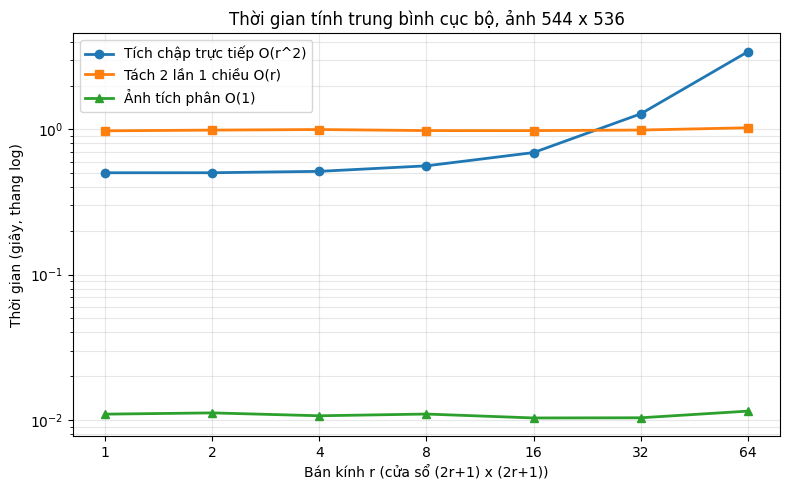

Tích chập trực tiếp O(r^2)  : r=1 0.5028 s, r=64 3.4235 s, gấp 6.8 lần
Tách 2 lần 1 chiều O(r)     : r=1 0.9774 s, r=64 1.0258 s, gấp 1.0 lần
Ảnh tích phân O(1)          : r=1 0.0110 s, r=64 0.0115 s, gấp 1.0 lần


In [44]:
fig, ax = plt.subplots(figsize=(8, 5))
for ten, dau in zip(CAC_CACH, ["o-", "s-", "^-"]):
    ax.plot(BAN_KINH, thoi_gian[ten], dau, linewidth=2, label=ten)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(BAN_KINH, [str(r) for r in BAN_KINH])
ax.set_xlabel("Bán kính r (cửa sổ (2r+1) x (2r+1))")
ax.set_ylabel("Thời gian (giây, thang log)")
ax.set_title(f"Thời gian tính trung bình cục bộ, ảnh {anh_do.shape[0]} x {anh_do.shape[1]}")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(thu_muc.parent / "images" / "kt2c_thoi_gian.png", dpi=150)
plt.show()

for ten, t in thoi_gian.items():
    print(f"{ten:28s}: r=1 {t[0]:.4f} s, r=64 {t[-1]:.4f} s, gấp {t[-1] / t[0]:.1f} lần")

# KỸ THUẬT 3 – Hough đa tỉ lệ  _(Tấn Lên, Tấn Hiệp, Hồng Gấm)_

## Hàm tự viết

# KT3 – Bỏ phiếu Hough: `hough_accumulate`, `find_peaks`  _(Tấn Lên)_

Theo Computer_Vision_40.pdf, mục 4.1, 4.4–4.6.

**Quy ước** (giống ảnh thử của Gấm và `hough_multiscale` của Hiệp):
- Đường thẳng: $\rho = x\cos\theta + y\sin\theta$, gốc tọa độ ở góc trên trái, $x$ = cột, $y$ = hàng.
- Mặc định $\theta \in [0, \pi)$ (180 giá trị), $\rho \in [-D, D]$ với $D$ = đường chéo ảnh, bước 1 px.
- Hai cặp $(\rho, \theta)$ và $(-\rho, \theta + \pi)$ là cùng một đường → cột $\theta$ cuối nối với cột $\theta = 0$ khi lật dấu $\rho$ (mục 4.3, bẫy quấn vòng).

**Giao diện** (theo đặc tả mục 4.6; các tham số có giá trị mặc định là nhóm thêm cho tiện gọi):
- `hough_accumulate(edges, theta_range=(0, π), rho_range=None, n_theta=180, n_rho=None, grad_dir=None, delta_deg=None)` → `(A, thetas, rhos)`, với `A[i, j]` là số phiếu của $(\rho_i, \theta_j)$.
  - `theta_range` tính bằng radian, lấy `n_theta` giá trị cách đều, không lấy đầu mút cuối.
  - `rho_range` lấy `n_rho` giá trị cách đều, có cả hai đầu mút.
  - Khi truyền `grad_dir` (radian), mỗi điểm cạnh chỉ bỏ phiếu cho các $\theta$ lệch không quá `delta_deg` **độ** so với hướng gradient, so sánh theo modulo 180° (mục 4.4). Nếu `delta_deg=None` thì dùng 15°, trong khoảng 5°–15° tài liệu gợi ý.
- `find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0, thetas=None, rhos=None)` → danh sách `(rho, theta, votes)` sắp giảm dần theo `votes`.
  - Đặc tả chỉ có `A` nên nhóm thêm `thetas`, `rhos` (tùy chọn, đặt sau cùng) để đổi chỉ số ô ra giá trị $(\rho, \theta)$. Nếu không truyền thì trả về chỉ số ô.
  - Chỉ quấn vòng $\theta$ khi có `thetas`, `rhos`, lưới phủ đúng $[0, \pi)$ và trục $\rho$ đối xứng.

**Quy ước của nhóm cho `find_peaks`** (tài liệu mục 4.5 chỉ ghi "tích chập với nhân Gauss nhỏ, σ ≈ 1 ô", không ghi làm mờ theo trục nào, cũng không ghi `votes` lấy trước hay sau làm mờ):
- `smooth_sigma` là độ lệch chuẩn Gauss **theo trục $\rho$**, tính bằng ô tích lũy; `smooth_sigma=0` là không làm mờ. Đây là **lựa chọn của nhóm**: làm mờ theo $\rho$ đủ để gom phiếu bị chẻ sang ô $\rho$ kề nhau, còn làm mờ thêm theo $\theta$ kéo lệch đỉnh của đoạn ngắn. Phần so sánh hai cách nằm ở ô kiểm thử bên dưới.
- `votes` là **điểm tích lũy sau làm mờ**: giá trị tại đỉnh trên bảng đã làm mờ (số thực). Khi `smooth_sigma=0`, đó là số phiếu gốc. Danh sách đỉnh sắp giảm dần theo chính giá trị này.
- Triệt phi cực đại: lặp lấy ô lớn nhất → xóa hình vuông bán kính `nms_radius` ô quanh nó → lấy ô lớn tiếp theo. Kết quả là chỉ giữ đỉnh trội trong bán kính cho trước (mục 4.5).

In [45]:
def hough_accumulate(edges, theta_range=(0, np.pi), rho_range=None,
                     n_theta=180, n_rho=None, grad_dir=None, delta_deg=None):
    """Bỏ phiếu vào mảng tích lũy. Nếu grad_dir khác None, chỉ bỏ phiếu
    trong dải +/- delta_deg (độ) quanh hướng gradient.
    Trả về (A, thetas, rhos), A có kích thước (n_rho, n_theta)."""
    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")

    h, w = edges.shape
    ys, xs = np.nonzero(edges)

    # Trục theta: n_theta giá trị cách đều trong [theta_min, theta_max)
    theta_min, theta_max = theta_range
    if int(n_theta) != n_theta or n_theta < 1 or not theta_min < theta_max:
        raise ValueError("theta_range, n_theta không hợp lệ")
    n_theta = int(n_theta)
    thetas = theta_min + np.arange(n_theta) * (theta_max - theta_min) / n_theta

    # Trục rho: mặc định [-D, D] với D = đường chéo ảnh, bước 1 px
    if rho_range is None:
        D = np.ceil(np.hypot(h - 1, w - 1))
        rho_range = (-D, D)
    rho_min, rho_max = rho_range
    if n_rho is None:
        n_rho = int(round(rho_max - rho_min)) + 1
    if int(n_rho) != n_rho or n_rho < 2 or not rho_min < rho_max:
        raise ValueError("rho_range, n_rho không hợp lệ")
    n_rho = int(n_rho)
    rhos = np.linspace(rho_min, rho_max, n_rho)
    rho_step = (rho_max - rho_min) / (n_rho - 1)

    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir, dtype=np.float64)
        if grad_dir.shape != edges.shape:
            raise ValueError("grad_dir phải cùng kích thước với edges")
        if delta_deg is None:
            delta_deg = 15.0   # tài liệu gợi ý 5°–15°
        if not 0 < delta_deg <= 90:
            raise ValueError("delta_deg phải thuộc (0, 90] độ")
        # Hướng pháp tuyến chỉ có nghĩa theo modulo 180°
        g = grad_dir[ys, xs] % np.pi
        delta = np.deg2rad(delta_deg)

    A = np.zeros((n_rho, n_theta), dtype=np.int64)

    # Với mỗi theta, mọi điểm cạnh cùng bỏ phiếu cho ô rho của mình
    for j, theta in enumerate(thetas):
        rho = xs * np.cos(theta) + ys * np.sin(theta)
        idx = np.rint((rho - rho_min) / rho_step).astype(int)
        hop_le = (idx >= 0) & (idx < n_rho)

        if grad_dir is not None:
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            hop_le &= lech <= delta

        A[:, j] = np.bincount(idx[hop_le], minlength=n_rho)

    return A, thetas, rhos

In [46]:
def smooth_accumulator(A, smooth_sigma=1.0):
    """Làm mờ bảng phiếu theo trục rho bằng kernel Gauss 1 chiều."""
    A = np.asarray(A, dtype=np.float64)
    if smooth_sigma <= 0:
        return A.copy()
    r = int(np.ceil(3 * smooth_sigma))
    x = np.arange(-r, r + 1)
    kernel = np.exp(-x**2 / (2 * smooth_sigma**2))
    kernel = (kernel / kernel.sum())[:, None]   # cột (2r+1) x 1: chỉ làm mờ theo rho
    return convolve2d(A, kernel, padding="constant")


def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0,
               thetas=None, rhos=None, threshold=0):
    """Làm mượt A bằng convolve2d của nhóm (Gauss theo trục rho, smooth_sigma
    tính bằng ô), triệt phi cực đại, trả về danh sách (rho, theta, votes) sắp
    giảm dần. votes là điểm tích lũy trên bảng đã làm mờ; smooth_sigma=0 thì
    votes là số phiếu gốc. Không truyền thetas, rhos thì rho, theta là chỉ số ô."""
    A = np.asarray(A)
    if A.ndim != 2:
        raise ValueError("A phải là mảng hai chiều")
    if int(n_peaks) != n_peaks or n_peaks < 1:
        raise ValueError("n_peaks phải là số nguyên dương")
    radii = (nms_radius, nms_radius) if np.isscalar(nms_radius) else tuple(nms_radius)
    if len(radii) != 2 or any(int(v) != v or v < 0 for v in radii):
        raise ValueError("nms_radius phải là số nguyên không âm hoặc cặp (rho, theta)")
    rho_radius, theta_radius = map(int, radii)
    if (thetas is None) != (rhos is None):
        raise ValueError("Phải truyền cả thetas và rhos, hoặc không truyền cả hai")
    if thetas is not None:
        thetas, rhos = np.asarray(thetas), np.asarray(rhos)
        if A.shape != (len(rhos), len(thetas)):
            raise ValueError("A phải có kích thước (len(rhos), len(thetas))")

    # Không làm mờ theo theta: kéo đỉnh của đoạn ngắn lệch góc (xem kiểm thử bên dưới)
    S = smooth_accumulator(A, smooth_sigma)
    n_rho, n_theta = S.shape

    # Chỉ quấn vòng theta khi lưới phủ đúng [0, pi) và trục rho đối xứng quanh 0
    wrap = (thetas is not None
            and np.isclose(thetas[0], 0) and np.isclose(thetas[-1] + np.pi / n_theta, np.pi)
            and np.allclose(rhos, -rhos[::-1]))

    remaining = S.copy()
    peaks = []

    for _ in range(int(n_peaks)):
        i, j = np.unravel_index(np.argmax(remaining), remaining.shape)
        if remaining[i, j] <= threshold:
            break
        if thetas is None:
            peaks.append((float(i), float(j), float(S[i, j])))
        else:
            peaks.append((float(rhos[i]), float(thetas[j]), float(S[i, j])))

        # Xóa vùng lân cận với bán kính riêng theo rho và theta
        for dj in range(-theta_radius, theta_radius + 1):
            jj, ii = j + dj, i
            if jj < 0 or jj >= n_theta:
                if not wrap:
                    continue
                jj %= n_theta
                ii = n_rho - 1 - i      # cột bên kia biên: rho đổi dấu
            r0 = max(0, ii - rho_radius)
            r1 = min(n_rho, ii + rho_radius + 1)
            remaining[r0:r1, jj] = 0

    # Sắp giảm dần theo điểm tích lũy sau làm mờ
    peaks.sort(key=lambda peak: peak[2], reverse=True)
    return peaks

In [47]:
def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8,
                     n_peaks=10, rho_step=2.0, theta_step_deg=1.0,
                     delta_deg=10.0):
    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")
    if int(n_levels) != n_levels or n_levels < 0:
        raise ValueError("n_levels phải là số nguyên không âm")
    if int(refine_factor) != refine_factor or refine_factor <= 1:
        raise ValueError("refine_factor phải là số nguyên lớn hơn 1")
    if rho_step <= 0 or not 0 < theta_step_deg < 180:
        raise ValueError("Bước rho và theta không hợp lệ")
    n_levels = int(n_levels)
    refine_factor = int(refine_factor)
    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir)

    h, w = edges.shape
    ys, xs = np.nonzero(edges)
    if len(xs) == 0:
        return []

    D = np.ceil(np.sqrt(h*h + w*w) / rho_step) * rho_step
    n_rho = int(round(2 * D / rho_step)) + 1
    n_theta = int(np.ceil(180 / theta_step_deg))
    A, thetas, rhos = hough_accumulate(
        edges, (0, np.pi), (-D, D), n_theta, n_rho,
        grad_dir=grad_dir, delta_deg=delta_deg)
    peaks = find_peaks(A, n_peaks, thetas=thetas, rhos=rhos)
    ket_qua = []

    for rho, theta, _ in peaks:
        rho_diem = xs * np.cos(theta) + ys * np.sin(theta)
        chi_so = np.rint((rho_diem + D) / rho_step).astype(int)
        o_rho = int(round((rho + D) / rho_step))
        chon = chi_so == o_rho
        if grad_dir is not None:
            g = grad_dir[ys, xs]
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            chon &= lech <= np.deg2rad(delta_deg)
        if not np.any(chon):
            continue

        canh_chon = np.zeros_like(edges, dtype=bool)
        canh_chon[ys[chon], xs[chon]] = True
        dr, dt = rho_step, np.pi / n_theta

        for _ in range(n_levels):
            rho_range = (rho - dr, rho + dr)
            theta_range = (theta - dt, theta + dt + dt / refine_factor)
            A_moi, t_moi, r_moi = hough_accumulate(
                canh_chon, theta_range, rho_range,
                2 * refine_factor + 1, 2 * refine_factor + 1,
                grad_dir=grad_dir, delta_deg=delta_deg)
            dinh_moi = find_peaks(A_moi, 1, thetas=t_moi, rhos=r_moi)
            if not dinh_moi:
                break
            rho, theta, _ = dinh_moi[0]
            dr /= refine_factor
            dt /= refine_factor

        while theta < 0:
            theta += np.pi
            rho = -rho
        while theta >= np.pi:
            theta -= np.pi
            rho = -rho

        ket_qua.append((float(rho), float(theta)))

    return ket_qua


In [48]:
def angle_error(theta_true, theta_detected):
    difference = abs(theta_true - theta_detected) % 180
    return min(difference, 180 - difference)


def rho_error(rho_true, theta_true, rho_detected, theta_detected):
    t1 = np.deg2rad(theta_true)
    t2 = np.deg2rad(theta_detected)

    n1 = np.array([np.cos(t1), np.sin(t1)])
    n2 = np.array([np.cos(t2), np.sin(t2)])

    if np.dot(n1, n2) < 0:
        rho_detected = -rho_detected

    return abs(rho_true - rho_detected)


print("Sai số góc 3° và 5°:", angle_error(3, 5))
print("Sai số góc 0.5° và 179.5°:", angle_error(0.5, 179.5))
print("Sai số rho khi quấn vòng:", rho_error(200, 0.5, -200, 180.5))

Sai số góc 3° và 5°: 2
Sai số góc 0.5° và 179.5°: 1.0
Sai số rho khi quấn vòng: 0


## Thí nghiệm

## KT3 – Ảnh thử

Ảnh `hough_test.png` của Gấm, đáp án: đoạn dài $\rho_0 = 110,\ \theta_0 = 3^\circ$ (300 px) và đoạn ngắn $\rho = 270,\ \theta = 3^\circ$ (20 px).

**Lấy điểm cạnh bằng Sobel tự viết** (không lấy thẳng các pixel của đường): đường chỉ dày 1 px nên ngay trên đường hai bên đều tối, Sobel cho $g_x \approx g_y \approx 0$ → hướng gradient vô nghĩa. Điểm cạnh thật nằm ở hai mép đường, ở đó hướng gradient đúng bằng pháp tuyến ($\approx 3^\circ$ hoặc $183^\circ$, cùng là $3^\circ$ theo modulo 180°).

In [49]:
from pathlib import Path
import numpy as np
import cv2

# Tìm ảnh ở cả images/ và lam_viec/images/
current_dir = Path.cwd().resolve()
folders = []

for parent in [current_dir, *current_dir.parents]:
    for folder in [parent / "images", parent / "lam_viec" / "images"]:
        if folder not in folders:
            folders.append(folder)

image_path = next(
    (folder / "hough_test.png"
     for folder in folders
     if (folder / "hough_test.png").is_file()),
    None
)

if image_path is None:
    print("Thư mục Python đang chạy:", current_dir)
    print("Các vị trí đã tìm:")
    for folder in folders:
        print(" -", folder / "hough_test.png")

    raise FileNotFoundError(
        "Chưa tìm thấy hough_test.png. "
        "Kiểm tra file ảnh trong thư mục images của nhóm."
    )

IMAGE_DIR = image_path.parent


def read_gray_image(path):
    """Đọc ảnh kể cả khi đường dẫn chứa tiếng Việt."""
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"Thiếu ảnh: {path}")

    data = np.frombuffer(path.read_bytes(), dtype=np.uint8)
    if data.size == 0:
        raise ValueError(f"File ảnh rỗng: {path}")

    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"File không phải ảnh hợp lệ hoặc bị hỏng: {path}")

    return image


test_image = read_gray_image(image_path)

print("Đã đọc thành công:", Path(image_path.parent.name) / image_path.name)
print("Kích thước ảnh:", test_image.shape)

Đã đọc thành công: images/hough_test.png
Kích thước ảnh: (400, 400)


## KT3 – Thí nghiệm: bỏ phiếu thường và bỏ phiếu theo gradient

Kích thước ảnh cạnh: (400, 400)
Kích thước hướng gradient: (400, 400)
Số điểm cạnh: 728


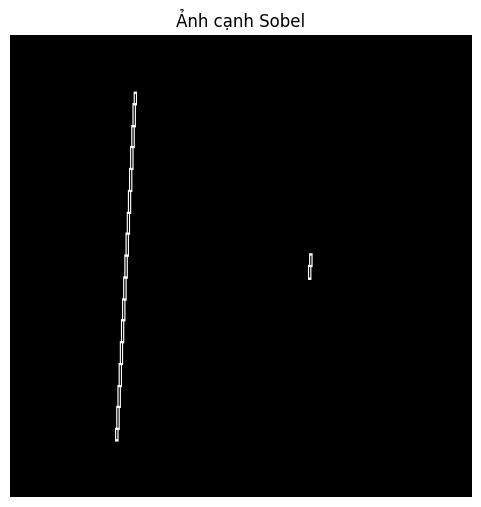

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Kiểm tra các phần cần chạy trước
if "test_image" not in globals():
    raise RuntimeError("Hãy chạy cell đọc ảnh trước.")

if not callable(globals().get("convolve2d")):
    raise RuntimeError("Hãy chạy cell định nghĩa convolve2d trước.")

# Thông tin đường chuẩn trong ảnh thử của Gấm
ground_truth = [(110, 3, 300), (270, 3, 20)]
rho0, theta0_deg = 110, 3

# Kernel Sobel
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = sobel_x.T


def sobel_edges(image, ratio=0.3):
    image = image.astype(np.float64)

    # Lật kernel vì convolve2d của nhóm thực hiện tích chập
    gx = convolve2d(
        image, np.flip(sobel_x), padding="reflect"
    )
    gy = convolve2d(
        image, np.flip(sobel_y), padding="reflect"
    )

    magnitude = np.hypot(gx, gy)
    edges = magnitude > ratio * magnitude.max()
    direction = np.arctan2(gy, gx)  # Radian, dùng cho Hough

    return edges, direction


# Tạo hai biến mà cell Hough đang cần
edge_map, gradient_direction = sobel_edges(test_image)

print("Kích thước ảnh cạnh:", edge_map.shape)
print("Kích thước hướng gradient:", gradient_direction.shape)
print("Số điểm cạnh:", int(edge_map.sum()))

plt.figure(figsize=(6, 6))
plt.imshow(edge_map, cmap="gray")
plt.title("Ảnh cạnh Sobel")
plt.axis("off")
plt.show()

## KT3 – Kiểm tra đỉnh đúng $(\rho_0, \theta_0)$

In [51]:

import numpy as np

# ============================================================
# KT3 - KIỂM TRA ĐỈNH ĐÚNG (rho0, theta0)
# Khôi phục dữ liệu để các cell phía sau dùng thống nhất
# ============================================================

rho0, theta0_deg = 110, 3

# Tính lại bản đồ cạnh và hướng gradient từ ảnh thử
edge_map, gradient_direction = sobel_edges(test_image)

# Tạo lại kết quả Hough, tránh phụ thuộc vào biến results cũ
results = {}

for name, grad in [
    ("thường", None),
    ("theo gradient", gradient_direction)
]:
    A, th, rh = hough_accumulate(
        edge_map,
        grad_dir=grad
    )

    A_smooth_mode = smooth_accumulator(A, smooth_sigma=1.0)

    peaks = find_peaks(
        A,
        n_peaks=5,
        nms_radius=3,
        smooth_sigma=1.0,
        thetas=th,
        rhos=rh
    )

    results[name] = (A, A_smooth_mode, peaks)

    if name == "thường":
        thetas, rhos = th, rh

    print(f"{name}: tìm được {len(peaks)} đỉnh")

# Giữ các biến tương thích với những cell cũ
A_plain = results["thường"][0]
A_grad = results["theo gradient"][0]
A_smooth = results["thường"][1]

print("\nCác chế độ:", list(results.keys()))


def angle_distance_deg(a, b):
    """Sai số góc modulo 180 độ."""
    d = abs(a - b) % 180
    return min(d, 180 - d)


def check_peak(peak, rho0, theta0_deg,
               rho_tol=2, theta_tol_deg=1):
    """Kiểm tra sai số của đỉnh Hough."""
    rho, theta, _ = peak
    theta_deg = np.rad2deg(theta)

    # Xử lý tính tương đương (rho, theta)
    if abs(theta_deg - theta0_deg) > 90:
        rho = -rho

    e_theta = angle_distance_deg(theta_deg, theta0_deg)
    e_rho = abs(rho - rho0)

    ok = e_rho <= rho_tol and e_theta <= theta_tol_deg

    return ok, e_rho, e_theta


print(f"\nĐáp án: rho0 = {rho0}, theta0 = {theta0_deg}°")
print("Dung sai nhóm tự đặt: 2 px, 1°\n")

for name, (_, _, peaks) in results.items():

    if len(peaks) == 0:
        print(f"Bỏ phiếu {name}: không tìm được đỉnh")
        continue

    ok, e_rho, e_theta = check_peak(
        peaks[0], rho0, theta0_deg
    )

    print(
        f"Bỏ phiếu {name:13s}: "
        f"đỉnh mạnh nhất = "
        f"({peaks[0][0]:.0f}, "
        f"{np.rad2deg(peaks[0][1]):.0f}°)"
        f" | sai số rho = {e_rho:.1f} px"
        f" | sai số góc = {e_theta:.1f}°"
        f" -> {'ĐẠT' if ok else 'KHÔNG ĐẠT'}"
    )

# Kiểm tra đoạn ngắn tại đáp án (270, 3°)
i270 = np.argmin(np.abs(rhos - 270))
j3 = np.argmin(np.abs(np.rad2deg(thetas) - 3))

short_score = A_smooth[i270, j3]
plain_peaks = results["thường"][2]

print(
    f"\nĐoạn ngắn (270, 3°): "
    f"điểm tích lũy tại ô đáp án = {short_score:.1f}"
)

if len(plain_peaks) >= 2:
    print(
        f"Điểm tích lũy đỉnh mạnh thứ hai = "
        f"{plain_peaks[1][2]:.1f}"
    )

print("\nHoàn thành kiểm tra đỉnh Hough.")


thường: tìm được 5 đỉnh
theo gradient: tìm được 5 đỉnh

Các chế độ: ['thường', 'theo gradient']

Đáp án: rho0 = 110, theta0 = 3°
Dung sai nhóm tự đặt: 2 px, 1°

Bỏ phiếu thường       : đỉnh mạnh nhất = (110, 3°) | sai số rho = 0.0 px | sai số góc = 0.0° -> ĐẠT
Bỏ phiếu theo gradient: đỉnh mạnh nhất = (110, 3°) | sai số rho = 0.0 px | sai số góc = 0.0° -> ĐẠT

Đoạn ngắn (270, 3°): điểm tích lũy tại ô đáp án = 13.4
Điểm tích lũy đỉnh mạnh thứ hai = 122.0

Hoàn thành kiểm tra đỉnh Hough.


Tâm đoạn ngắn: (259.5, 200.0), độ phân giải góc ≈ 2.9°

Bỏ phiếu thường:
  smooth_sigma = 0: (-256, 179°) | sai số rho = 14 px, sai số góc = 4° | cách tâm đoạn 0.1 px | 11 ô có điểm ≥ 90% đỉnh
  smooth_sigma = 1.0: (263, 1°) | sai số rho = 7 px, sai số góc = 2° | cách tâm đoạn 0.1 px | 21 ô có điểm ≥ 90% đỉnh

Bỏ phiếu theo gradient:
  smooth_sigma = 0: (275, 5°) | sai số rho = 5 px, sai số góc = 2° | cách tâm đoạn 0.9 px | 4 ô có điểm ≥ 90% đỉnh
  smooth_sigma = 1.0: (276, 5°) | sai số rho = 6 px, sai số góc = 2° | cách tâm đoạn 0.1 px | 16 ô có điểm ≥ 90% đỉnh



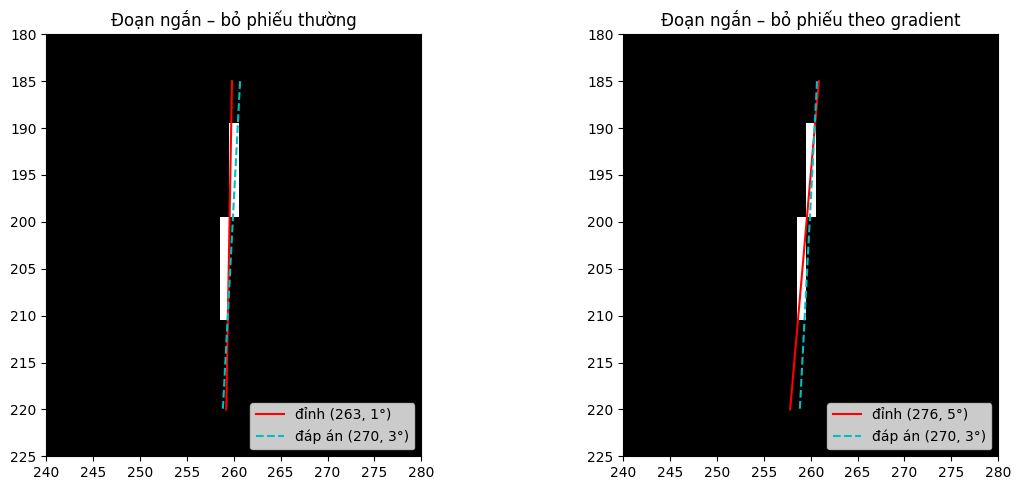

In [52]:
short_image = test_image.copy()
short_image[:, :250] = 0
short_edges, short_grad = sobel_edges(short_image)

ys_s, xs_s = np.nonzero(short_image > 127)
center_x, center_y = xs_s.mean(), ys_s.mean()
length = 20
resolution_deg = np.rad2deg(1 / length)
print(f"Tâm đoạn ngắn: ({center_x:.1f}, {center_y:.1f}), độ phân giải góc ≈ {resolution_deg:.1f}°\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, g) in zip(axes, [("thường", None), ("theo gradient", short_grad)]):
    A, thetas_s, rhos_s = hough_accumulate(short_edges, grad_dir=g)
    print(f"Bỏ phiếu {name}:")
    for sigma in [0, 1.0]:
        peaks = find_peaks(A, 1, smooth_sigma=sigma, thetas=thetas_s, rhos=rhos_s)
        A_used = smooth_accumulator(A, sigma)
        rho, theta, score = peaks[0]
        dist = abs(center_x * np.cos(theta) + center_y * np.sin(theta) - rho)
        e_theta = angle_distance_deg(np.rad2deg(theta), 3)
        _, e_rho, _ = check_peak(peaks[0], 270, 3)
        n_best = int(np.sum(A_used >= 0.9 * score))
        print(f"  smooth_sigma = {sigma}: ({rho:.0f}, {np.rad2deg(theta):.0f}°)"
              f" | sai số rho = {e_rho:.0f} px, sai số góc = {e_theta:.0f}°"
              f" | cách tâm đoạn {dist:.1f} px | {n_best} ô có điểm ≥ 90% đỉnh")
        if sigma > 0:
            ys_line = np.arange(185, 221)
            ax.plot((rho - ys_line * np.sin(theta)) / np.cos(theta), ys_line, "r-", label=f"đỉnh ({rho:.0f}, {np.rad2deg(theta):.0f}°)")
    ax.imshow(short_image, cmap="gray", vmin=0, vmax=255)
    ys_true = np.arange(185, 221)
    t3 = np.deg2rad(3)
    ax.plot((270 - ys_true * np.sin(t3)) / np.cos(t3), ys_true, "c--", label="đáp án (270, 3°)")
    ax.set_xlim(240, 280)
    ax.set_ylim(225, 180)
    ax.set_title(f"Đoạn ngắn – bỏ phiếu {name}")
    ax.legend(loc="lower right")
    print()
plt.tight_layout()
plt.show()

### So sánh hai cách làm mờ: chỉ theo $\rho$ (nhóm chọn) và Gauss 2 chiều
Cùng σ = 1 ô. Bản 2 chiều chỉ viết trong ô này để so sánh, không phải hàm nộp; nó nối cột θ quấn vòng (lật ρ) trước khi tích chập. Báo đỉnh mạnh nhất cùng sai số $\rho$ và sai số góc so với đáp án.

In [53]:
def smooth_2d(A, sigma=1.0):
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1)
    k = np.exp(-x**2 / (2 * sigma**2))
    k /= k.sum()
    extended = np.hstack([A[::-1, -r:], A, A[::-1, :r]])
    return convolve2d(extended, np.outer(k, k), padding="constant")[:, r:-r]


print(f"{'ảnh':10s} {'bỏ phiếu':14s} | {'chỉ theo rho':28s} | {'Gauss 2 chiều':28s}")
for label, edges_c, grad_c, (r_true, t_true) in [
        ("đoạn dài", edge_map, gradient_direction, (rho0, theta0_deg)),
        ("đoạn ngắn", short_edges, short_grad, (270, 3))]:
    for name, g in [("thường", None), ("theo gradient", grad_c)]:
        A, th, rh = hough_accumulate(edges_c, grad_dir=g)
        row = []
        for S_c in [smooth_accumulator(A, 1.0), smooth_2d(A, 1.0)]:
            i, j = np.unravel_index(np.argmax(S_c), S_c.shape)
            peak = (rh[i], th[j], S_c[i, j])
            _, e_rho, e_theta = check_peak(peak, r_true, t_true)
            row.append(f"({rh[i]:.0f}, {np.rad2deg(th[j]):.0f}°) lệch {e_rho:.0f} px, {e_theta:.0f}°")
        print(f"{label:10s} {name:14s} | {row[0]:28s} | {row[1]:28s}")

ảnh        bỏ phiếu       | chỉ theo rho                 | Gauss 2 chiều               
đoạn dài   thường         | (110, 3°) lệch 0 px, 0°      | (110, 3°) lệch 0 px, 0°     
đoạn dài   theo gradient  | (110, 3°) lệch 0 px, 0°      | (111, 3°) lệch 1 px, 0°     
đoạn ngắn  thường         | (263, 1°) lệch 7 px, 2°      | (308, 18°) lệch 38 px, 15°  
đoạn ngắn  theo gradient  | (276, 5°) lệch 6 px, 2°      | (298, 13°) lệch 28 px, 10°  


### Kiểm tra thêm: lưới góc và tham số `theta_range`, `rho_range`, `n_theta`, `n_rho`
Lưới $\theta$ được tạo từ `n_theta` (không còn tham số bước góc), nên luôn phủ đủ `theta_range`: góc cuối + bước = đầu mút trên. Ví dụ `n_theta = 22` cho bước ≈ 8.18° và không bỏ sót góc nào ở cuối như trường hợp bước 8° trước đây (chỉ tới 168°, mất 176°).

In [54]:
for label, kwargs in [("mặc định", dict()),
                      ("n_theta=22", dict(n_theta=22)),
                      ("n_theta=45", dict(n_theta=45)),
                      ("theta_range=(0, π/2), n_theta=90", dict(theta_range=(0, np.pi / 2), n_theta=90))]:
    A, th, rh = hough_accumulate(edge_map, **kwargs)
    step = np.rad2deg(th[1] - th[0])
    print(f"{label:34s}: {len(th):3d} góc, {np.rad2deg(th[0]):.1f}° → {np.rad2deg(th[-1]):6.2f}°,"
          f" bước {step:.2f}°, góc cuối + bước = {np.rad2deg(th[-1]) + step:.0f}°")

# Thu hẹp vùng tìm quanh đáp án: theta trong [0°, 10°) bước 0.5°, rho trong [100, 120] bước 1 px
A, th, rh = hough_accumulate(edge_map, theta_range=(0, np.deg2rad(10)), n_theta=20,
                             rho_range=(100, 120), n_rho=21)
rho_p, theta_p, votes_p = find_peaks(A, 1, thetas=th, rhos=rh)[0]
print(f"\nVùng hẹp, A có kích thước {A.shape}: đỉnh ({rho_p:.1f}, {np.rad2deg(theta_p):.1f}°), điểm tích lũy = {votes_p:.1f}")
print("Lưu ý: smooth_sigma tính bằng số ô rho, nên nếu đổi bước rho thì chỉnh smooth_sigma theo"
      " (hai mép đường cách nhau khoảng 2 px).")

mặc định                          : 180 góc, 0.0° → 179.00°, bước 1.00°, góc cuối + bước = 180°
n_theta=22                        :  22 góc, 0.0° → 171.82°, bước 8.18°, góc cuối + bước = 180°
n_theta=45                        :  45 góc, 0.0° → 176.00°, bước 4.00°, góc cuối + bước = 180°
theta_range=(0, π/2), n_theta=90  :  90 góc, 0.0° →  89.00°, bước 1.00°, góc cuối + bước = 90°

Vùng hẹp, A có kích thước (21, 20): đỉnh (110.0, 3.0°), điểm tích lũy = 160.3
Lưu ý: smooth_sigma tính bằng số ô rho, nên nếu đổi bước rho thì chỉnh smooth_sigma theo (hai mép đường cách nhau khoảng 2 px).


# VÒNG 3 – Tấn Lên: Thí nghiệm KT3 (b)

**Nhiệm vụ:** so sánh Hough thô / mịn / đa tỉ lệ theo sai số góc, độ rõ đỉnh và thời gian; bật/tắt bỏ phiếu theo gradient; lập bảng và nhận xét.

**Nguồn kế thừa:** `main` tại commit `74a07c2fe7021b60c11a957f53705d7e57c93ede`:
- `len.ipynb`: `convolve2d`, `sobel_edges`, `hough_accumulate`, `smooth_accumulator`, `find_peaks`.
- `hiep.ipynb`: `hough_multiscale` (chỉ nạp để tham khảo; bảng so sánh dùng quy trình chung `v3_detect` để cả ba phương pháp dùng cùng `hough_accumulate`, làm mượt và NMS).
- `gam.ipynb`: `angle_error`, `rho_error` và các ảnh thử trong `images/`.
 

**Thiết kế so sánh**

| Phương pháp | Bước góc | Bước rho | Phạm vi |
|---|---:|---:|---|
| Thô | 1° | 2 px | Toàn miền |
| Mịn | 0.125° | 0.25 px | Toàn miền |
| Đa tỉ lệ | 1° → 0.125° | 2 → 0.25 px | Thô toàn miền, một lần tinh chỉnh quanh mỗi đỉnh |

`n_levels=1` nghĩa là **một lần tinh chỉnh sau lưới thô**, không phải chỉ có một lưới. Dùng hệ số 8 để lưới cuối của đa tỉ lệ có cùng độ phân giải với Hough mịn. Cả ba lấy tối đa 10 đỉnh; `find_peaks` dùng mặc định sigma=1 ô rho, NMS=3 ô theo code nhóm. Do đó bề rộng làm mượt và NMS theo đơn vị vật lý không giống nhau giữa lưới thô/mịn. Đây là so sánh các cấu hình hiện có, không tách riêng ảnh hưởng của từng tham số.

Tất cả dùng **cùng ảnh cạnh Sobel** (`ratio=0.3`). Gradient là hướng Sobel tính từ ảnh, không dùng góc đáp án để bỏ phiếu. Bật gradient với `delta_deg=10`; tắt bằng `None`. Thời gian chỉ tính gọi bộ phát hiện (bỏ phiếu, làm mượt, tìm đỉnh và tinh chỉnh), không gồm đọc ảnh, Sobel, đánh giá hay vẽ. Báo trung vị 3 lượt và khoảng min–max; đổi thứ tự chạy giữa các lượt. Bản Python dùng vòng lặp tích chập nên toàn bộ notebook có thể cần nhiều phút.

**Ba chỉ số chính**
1. Sai số góc: $e_\theta=\min(|\theta-\theta_0|\bmod180,180-(|\theta-\theta_0|\bmod180))$, đơn vị độ.
2. Độ rõ đỉnh: **PSR tại nghiệm trên lưới đánh giá chung**: $(P-\mu_B)/\sigma_B$. Lập bảng phiếu cục bộ quanh đường trả về bằng *toàn bộ* điểm cạnh của ảnh và cùng chế độ gradient; bước 0.25 px / 0.125°, vùng ±6 px / ±3°, làm mượt sigma=1 ô rho. $P$ là điểm tại đúng nghiệm, không lấy lại cực đại. Nền $B$ loại hình chữ nhật ±1 px / ±0.5° quanh nghiệm. Chỉ số lớn nghĩa là điểm tại nghiệm nổi bật hơn nền cục bộ; có thể thấp hoặc âm nếu nghiệm không trùng đỉnh của lưới đánh giá. **Không so trực tiếp số phiếu đỉnh giữa bảng thô và bảng tinh chỉnh dùng tập điểm khác nhau.** PSR này là quy ước bổ sung để so sánh công bằng, không phải độ cao đỉnh nội bộ của hàm đa tỉ lệ.
3. Thời gian (ms): trung vị và min–max qua 3 lượt, phụ thuộc máy chạy.

**Ghép đường để đánh giá:** ghép một–một các đỉnh trả về với đường chuẩn, trong cửa sổ sai số rho ≤6 px và góc ≤10°. Trong cửa sổ, ưu tiên đỉnh xuất hiện trước trong danh sách bộ phát hiện; nếu một đỉnh cùng phù hợp nhiều đường chuẩn, ưu tiên tổng sai số chuẩn hóa nhỏ hơn. Không dùng đáp án để chọn đỉnh có góc đẹp nhất trong top-10. Đây là dung sai *ghép*, không phải tiêu chí kết luận chính xác. Không tìm được ứng viên thì ghi `KHÔNG TÌM THẤY` và NaN, không tính thành sai số 0. Đoạn ngắn được báo riêng để tránh chỉ đánh giá đoạn dài. Các ảnh chuẩn là nét raster 1 px; Sobel tạo hai mép nên rho có thể lệch đường tâm.

In [55]:
from pathlib import Path

v3_root = Path.cwd()
if v3_root.name == 'lam_viec':
    v3_root = v3_root.parent

for v3_name in ['convolve2d', 'sobel_edges', 'hough_accumulate',
                'smooth_accumulator', 'find_peaks']:
    if not callable(globals().get(v3_name)):
        raise RuntimeError(f'Hãy chạy phần vòng 1–2 trước: thiếu {v3_name}.')

v3_original_multiscale = hough_multiscale
v3_angle_error = angle_error
v3_rho_error = rho_error
print('Đã nạp hàm gốc của Hiệp để tham khảo và hai hàm đo sai số của Gấm. Bảng so sánh dùng quy trình chung ở ô v3_detect bên dưới.')

Đã nạp hàm gốc của Hiệp để tham khảo và hai hàm đo sai số của Gấm. Bảng so sánh dùng quy trình chung ở ô v3_detect bên dưới.


OK: Gần 0° | Ảnh: hough_angle_0_5.png | Kích thước: (400, 400) | Điểm cạnh: 622
Đáp án chuẩn: [('Dài', 200, 0.5, 300)]
-------------------------------------------------------
OK: Gần 180° | Ảnh: hough_angle_179_5.png | Kích thước: (400, 400) | Điểm cạnh: 622
Đáp án chuẩn: [('Dài', -200, 179.5, 300)]
-------------------------------------------------------
OK: Dài + ngắn | Ảnh: hough_test.png | Kích thước: (400, 400) | Điểm cạnh: 728
Đáp án chuẩn: [('Dài', 110, 3, 300), ('Ngắn', 270, 3, 20)]
-------------------------------------------------------


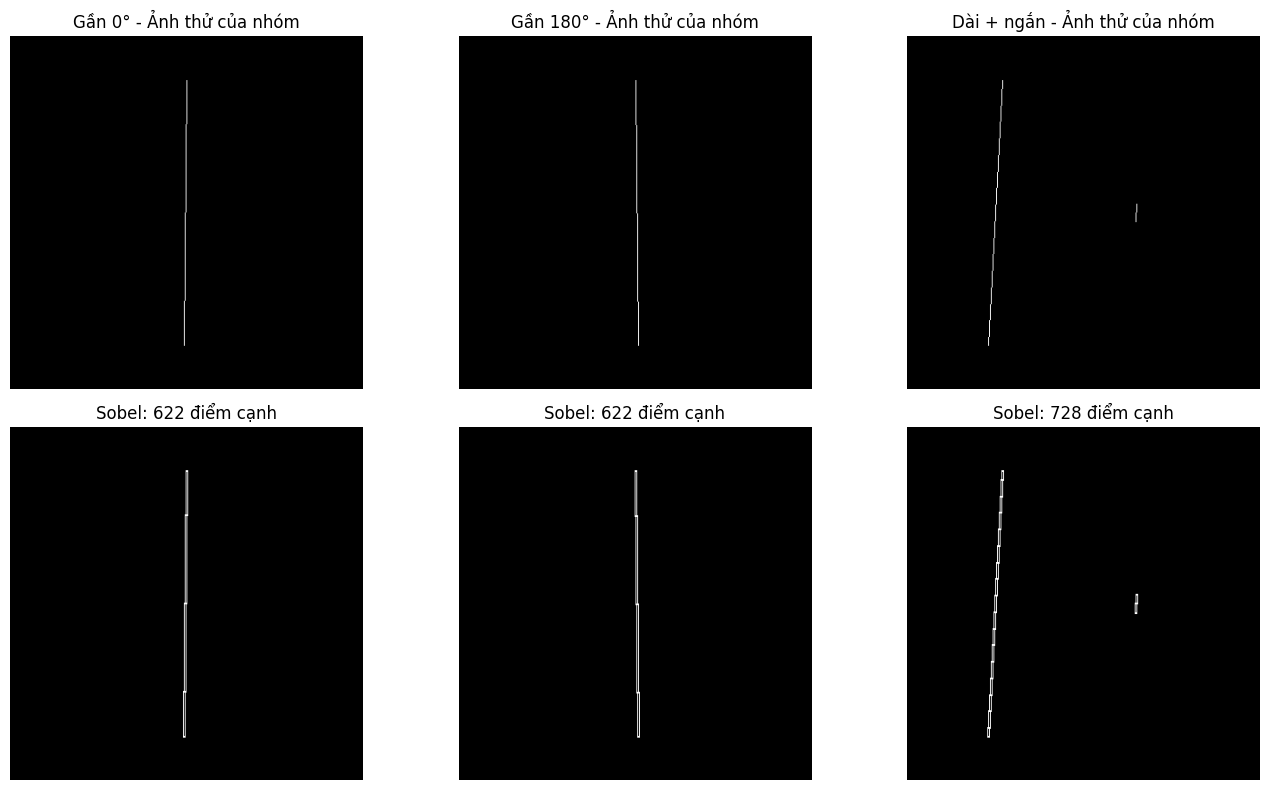


KIỂM TRA HOÀN THÀNH CELL V3.1
Số trường hợp thí nghiệm: 3
Các phương pháp: ['Thô', 'Mịn', 'Đa tỉ lệ']
Bỏ phiếu theo gradient: ['Tắt', 'Bật']

THÀNH CÔNG - Sẵn sàng chạy cell V3.2!


In [56]:

# ============================================================
# VÒNG 3 - CELL V3.1: NẠP ĐÚNG HÀM VÀ DỮ LIỆU CỦA NHÓM
# FIX LỖI ĐỌC ẢNH ĐƯỜNG DẪN TIẾNG VIỆT
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. Cấu hình thí nghiệm vòng 3
V3_REPEATS = 3
V3_N_PEAKS = 10
V3_DELTA_DEG = 10.0
V3_REFINE = 8
V3_COARSE_DR = 2.0
V3_COARSE_DT = 1.0
V3_SMOOTH_RHO = 0.5
V3_NMS_RHO = 6.0
V3_NMS_THETA = 3.0

V3_METHODS = ['Thô', 'Mịn', 'Đa tỉ lệ']
V3_MODES = ['Tắt', 'Bật']

# 2. Danh sách ảnh và đáp án chuẩn
v3_specs = [
    (
        'Gần 0°',
        'hough_angle_0_5.png',
        [('Dài', 200, 0.5, 300)]
    ),
    (
        'Gần 180°',
        'hough_angle_179_5.png',
        [('Dài', -200, 179.5, 300)]
    ),
    (
        'Dài + ngắn',
        'hough_test.png',
        [
            ('Dài', 110, 3, 300),
            ('Ngắn', 270, 3, 20)
        ]
    )
]

# 3. Hàm đọc ảnh hỗ trợ Unicode trên Windows
def v3_read_image(path):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy file ảnh: {path}"
        )

    data = np.fromfile(str(path), dtype=np.uint8)

    if data.size == 0:
        raise ValueError(f"File ảnh rỗng: {path}")

    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(
            f"Không giải mã được ảnh: {path}"
        )

    return image


# 4. Nạp ảnh, tính Sobel và tạo dữ liệu thí nghiệm
v3_cases = []

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

for col, (name, filename, truth) in enumerate(v3_specs):

    image_path = v3_root / 'images' / filename

    # FIX: Không sử dụng cv2.imread với đường dẫn Unicode
    image = v3_read_image(image_path)

    # Sử dụng hàm Sobel tự viết của nhóm
    edges, grad = sobel_edges(
        image,
        ratio=0.3
    )

    # Kiểm tra dữ liệu
    assert edges.shape == image.shape, \
        "Kích thước edge map không khớp ảnh"

    assert grad.shape == image.shape, \
        "Kích thước gradient không khớp ảnh"

    assert np.isfinite(grad[edges]).all(), \
        "Gradient chứa giá trị không hợp lệ"

    # Giữ nguyên cấu trúc dữ liệu cho các cell phía sau
    v3_cases.append(
        dict(
            name=name,
            image=image,
            edges=edges,
            grad=grad,
            truth=truth
        )
    )

    # Hiển thị ảnh gốc
    axes[0, col].imshow(
        image,
        cmap='gray',
        vmin=0,
        vmax=255
    )
    axes[0, col].set_title(
        f'{name} - Ảnh thử của nhóm'
    )

    # Hiển thị biên Sobel
    axes[1, col].imshow(
        edges,
        cmap='gray'
    )
    axes[1, col].set_title(
        f'Sobel: {int(edges.sum())} điểm cạnh'
    )

    print(
        f"OK: {name} | "
        f"Ảnh: {filename} | "
        f"Kích thước: {image.shape} | "
        f"Điểm cạnh: {int(edges.sum())}"
    )
    print(f"Đáp án chuẩn: {truth}")
    print("-" * 55)

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

# 5. Kiểm tra dữ liệu đầu ra
print("\n" + "=" * 55)
print("KIỂM TRA HOÀN THÀNH CELL V3.1")
print("=" * 55)

print("Số trường hợp thí nghiệm:", len(v3_cases))
print("Các phương pháp:", V3_METHODS)
print("Bỏ phiếu theo gradient:", V3_MODES)

assert len(v3_cases) == 3, \
    "Số lượng trường hợp thí nghiệm không đúng"

print("\nTHÀNH CÔNG - Sẵn sàng chạy cell V3.2!")


In [57]:
def v3_stage(edges, grad, theta_range, rho_range, n_theta, n_rho,
             n_peaks, nms_rho, nms_theta, crop_rho=0):
    A, th, rh = hough_accumulate(
        edges, theta_range=theta_range, rho_range=rho_range,
        n_theta=n_theta, n_rho=n_rho,
        grad_dir=grad, delta_deg=V3_DELTA_DEG)
    dr = float(rh[1] - rh[0])
    dt = float(np.rad2deg(th[1] - th[0]))
    S = smooth_accumulator(A, smooth_sigma=V3_SMOOTH_RHO / dr)
    if crop_rho:
        S, rh = S[crop_rho:-crop_rho], rh[crop_rho:-crop_rho]
    radii = (int(np.ceil(nms_rho / dr)), int(np.ceil(nms_theta / dt)))
    return find_peaks(S, n_peaks, nms_radius=radii, smooth_sigma=0,
                      thetas=th, rhos=rh)


def v3_detect(edges, grad, method, n_peaks=None, nms_rho=None, nms_theta=None):
    if method not in V3_METHODS:
        raise ValueError(method)
    n_peaks = V3_N_PEAKS if n_peaks is None else n_peaks
    nms_rho = V3_NMS_RHO if nms_rho is None else nms_rho
    nms_theta = V3_NMS_THETA if nms_theta is None else nms_theta
    h, w = edges.shape
    D = np.ceil(np.hypot(h, w) / V3_COARSE_DR) * V3_COARSE_DR
    factor = V3_REFINE if method == 'Mịn' else 1
    dr, dt = V3_COARSE_DR / factor, V3_COARSE_DT / factor
    peaks = v3_stage(
        edges, grad, (0, np.pi), (-D, D),
        int(np.ceil(180 / dt)), int(round(2 * D / dr)) + 1,
        n_peaks, nms_rho, nms_theta)
    if method != 'Đa tỉ lệ':
        return [(float(r), float(t)) for r, t, _ in peaks]

    # Theo mục 4.3: chỉ các điểm đã bỏ phiếu cho ô thô được tinh chỉnh.
    fine_dr = V3_COARSE_DR / V3_REFINE
    fine_dt = np.deg2rad(V3_COARSE_DT / V3_REFINE)
    coarse_dt = np.deg2rad(V3_COARSE_DT)
    pad = int(np.ceil(3 * V3_SMOOTH_RHO / fine_dr))
    refined = []
    ys, xs = np.nonzero(edges)
    for rho, theta, _ in peaks:
        bins = np.rint((xs * np.cos(theta) + ys * np.sin(theta) + D)
                       / V3_COARSE_DR).astype(int)
        chosen = bins == int(round((rho + D) / V3_COARSE_DR))
        if grad is not None:
            directions = np.asarray(grad)[ys, xs]
            difference = np.abs((directions - theta + np.pi / 2) % np.pi - np.pi / 2)
            chosen &= difference <= np.deg2rad(V3_DELTA_DEG)
        if not chosen.any():
            continue
        local_edges = np.zeros_like(edges, dtype=bool)
        local_edges[ys[chosen], xs[chosen]] = True
        local = v3_stage(
            local_edges, grad,
            (theta - coarse_dt, theta + coarse_dt + fine_dt),
            (rho - V3_COARSE_DR - pad * fine_dr,
             rho + V3_COARSE_DR + pad * fine_dr),
            2 * V3_REFINE + 1, 2 * V3_REFINE + 1 + 2 * pad,
            1, nms_rho, nms_theta, crop_rho=pad)
        if not local:
            continue
        r, t, score = local[0]
        if int(np.floor(t / np.pi)) % 2:
            r = -r
        t = float(t % np.pi)
        if t >= np.pi:  # Sai số làm tròn có thể đưa góc âm rất nhỏ thành đúng pi.
            t, r = 0.0, -r
        refined.append((float(r), t, score))
    refined.sort(key=lambda peak: peak[2], reverse=True)
    return [(r, t) for r, t, _ in refined]

print('Cả ba cách dùng hough_accumulate, smooth_accumulator, find_peaks của nhóm.')
print(f'Làm mượt rho: sigma={V3_SMOOTH_RHO} px; NMS: {V3_NMS_RHO} px / {V3_NMS_THETA} độ.')
print('Lưới cuối mịn/đa tỉ lệ: 0.125 độ, 0.25 px; đa tỉ lệ tinh chỉnh 1 lần.')


Cả ba cách dùng hough_accumulate, smooth_accumulator, find_peaks của nhóm.
Làm mượt rho: sigma=0.5 px; NMS: 6.0 px / 3.0 độ.
Lưới cuối mịn/đa tỉ lệ: 0.125 độ, 0.25 px; đa tỉ lệ tinh chỉnh 1 lần.


In [58]:
def v3_match(peaks, truth, rho_tol=6.0, theta_tol=10.0):
    candidates = []
    for ti, (_, r0, t0, _) in enumerate(truth):
        for pi, (r, t) in enumerate(peaks):
            td = float(np.rad2deg(t))
            er = v3_rho_error(r0, t0, r, td)
            et = v3_angle_error(t0, td)
            if er <= rho_tol and et <= theta_tol:
                candidates.append((pi, er / rho_tol + et / theta_tol, ti))
    matched, used = {}, set()
    for pi, _, ti in sorted(candidates):
        if ti not in matched and pi not in used:
            matched[ti] = pi
            used.add(pi)
    return matched

def v3_peak_metrics(edges, grad, rho, theta):
    dr, dt = 0.25, np.deg2rad(0.125)
    # ±6 px, ±3°; thêm 3 ô rho để đủ biên kernel sigma=1.
    nr, nt = 24, 24
    pad = int(np.ceil(3 * V3_SMOOTH_RHO / dr))
    A, th, rh = hough_accumulate(
        edges, theta_range=(theta - nt * dt, theta + (nt + 1) * dt),
        rho_range=(rho - (nr + pad) * dr, rho + (nr + pad) * dr),
        n_theta=2 * nt + 1, n_rho=2 * (nr + pad) + 1,
        grad_dir=grad, delta_deg=V3_DELTA_DEG)
    S = smooth_accumulator(A, smooth_sigma=V3_SMOOTH_RHO / dr)[pad:-pad]
    offsets_r = np.arange(-nr, nr + 1) * dr
    offsets_t = np.arange(-nt, nt + 1) * 0.125
    main_lobe = ((np.abs(offsets_r[:, None]) <= 1.0)
                 & (np.abs(offsets_t[None, :]) <= 0.5))
    background = S[~main_lobe]
    peak = float(S[nr, nt])
    mean, std = float(background.mean()), float(background.std())
    ratio = peak / mean if mean > 1e-12 else np.nan
    psr = (peak - mean) / std if std > 1e-12 else np.nan
    return dict(peak=peak, background=mean, peak_ratio=ratio, psr=psr)

# Kiểm tra quy ước góc và dấu rho trước khi đo.
assert np.isclose(v3_angle_error(0.5, 179.5), 1.0)
assert np.isclose(v3_rho_error(200, 0.5, -200, 180.5), 0.0)
assert v3_match([], v3_cases[0]['truth']) == {}
print('Quy ước quấn vòng góc và trường hợp không có đỉnh: OK.')

Quy ước quấn vòng góc và trường hợp không có đỉnh: OK.


In [59]:
if V3_REPEATS < 3:
    raise ValueError('Dùng ít nhất 3 lượt cho bảng so sánh chính.')

v3_warm_edges = np.zeros((32, 32), dtype=bool)
v3_warm_edges[4:28, 16] = True
for v3_method in V3_METHODS:
    v3_detect(v3_warm_edges, None, v3_method)

v3_runs = {}
for case in v3_cases:
    for mode in V3_MODES:
        grad = case['grad'] if mode == 'Bật' else None
        for method in V3_METHODS:
            v3_runs[(case['name'], mode, method)] = dict(times=[], peaks=None)
        for repeat in range(V3_REPEATS):
            order = V3_METHODS[repeat % 3:] + V3_METHODS[:repeat % 3]
            for method in order:
                started = time.perf_counter()
                peaks = v3_detect(case['edges'], grad, method)
                elapsed_ms = (time.perf_counter() - started) * 1000
                item = v3_runs[(case['name'], mode, method)]
                item['times'].append(elapsed_ms)
                if item['peaks'] is not None:
                    assert np.allclose(np.asarray(peaks), np.asarray(item['peaks']))
                item['peaks'] = peaks
            print(f"{case['name']} | gradient {mode} | lượt {repeat + 1}/{V3_REPEATS}",
                  flush=True)
print('Đã đo xong 18 cấu hình, mỗi cấu hình 3 lượt.')

Gần 0° | gradient Tắt | lượt 1/3
Gần 0° | gradient Tắt | lượt 2/3
Gần 0° | gradient Tắt | lượt 3/3
Gần 0° | gradient Bật | lượt 1/3
Gần 0° | gradient Bật | lượt 2/3
Gần 0° | gradient Bật | lượt 3/3
Gần 180° | gradient Tắt | lượt 1/3
Gần 180° | gradient Tắt | lượt 2/3
Gần 180° | gradient Tắt | lượt 3/3
Gần 180° | gradient Bật | lượt 1/3
Gần 180° | gradient Bật | lượt 2/3
Gần 180° | gradient Bật | lượt 3/3
Dài + ngắn | gradient Tắt | lượt 1/3
Dài + ngắn | gradient Tắt | lượt 2/3
Dài + ngắn | gradient Tắt | lượt 3/3
Dài + ngắn | gradient Bật | lượt 1/3
Dài + ngắn | gradient Bật | lượt 2/3
Dài + ngắn | gradient Bật | lượt 3/3
Đã đo xong 18 cấu hình, mỗi cấu hình 3 lượt.


### Bảng so sánh đủ ba chỉ số

Báo riêng từng đường chuẩn. Thời gian là của toàn ảnh nên hai hàng dài/ngắn cùng cấu hình có chung thời gian; không cộng hai hàng đó. PSR càng lớn càng nổi bật, sai số góc và thời gian càng nhỏ càng tốt.



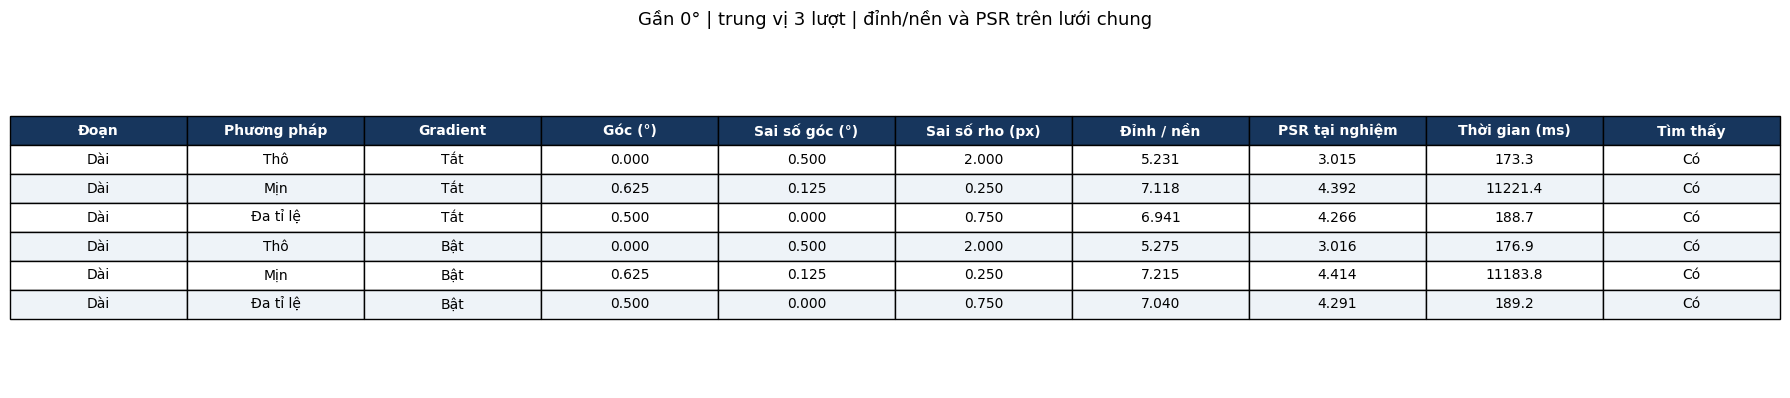

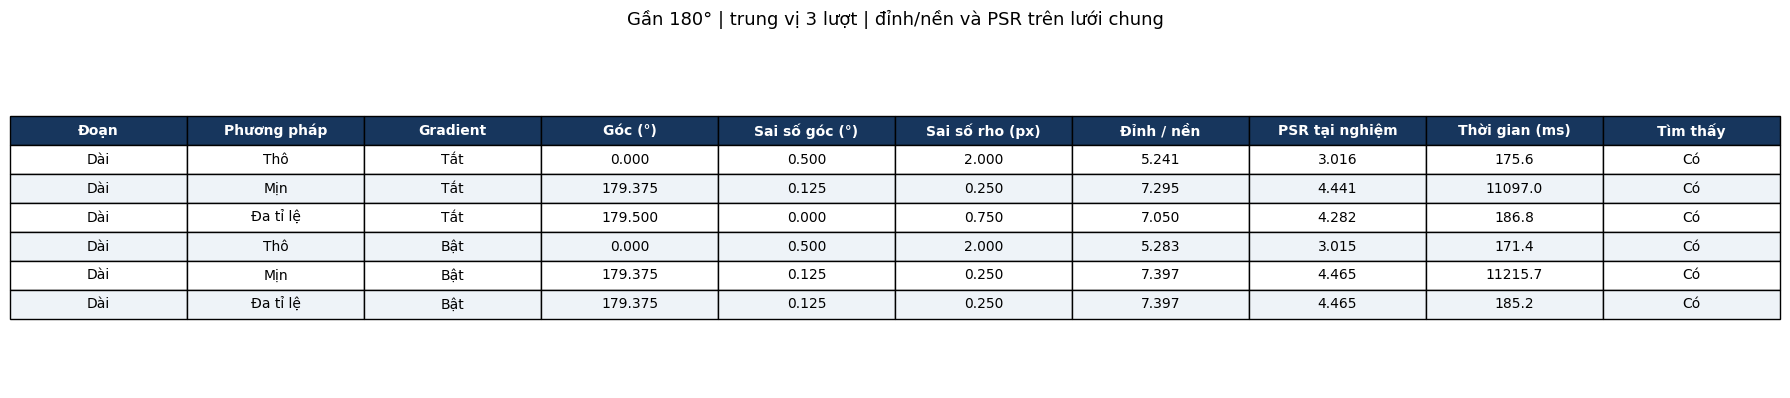

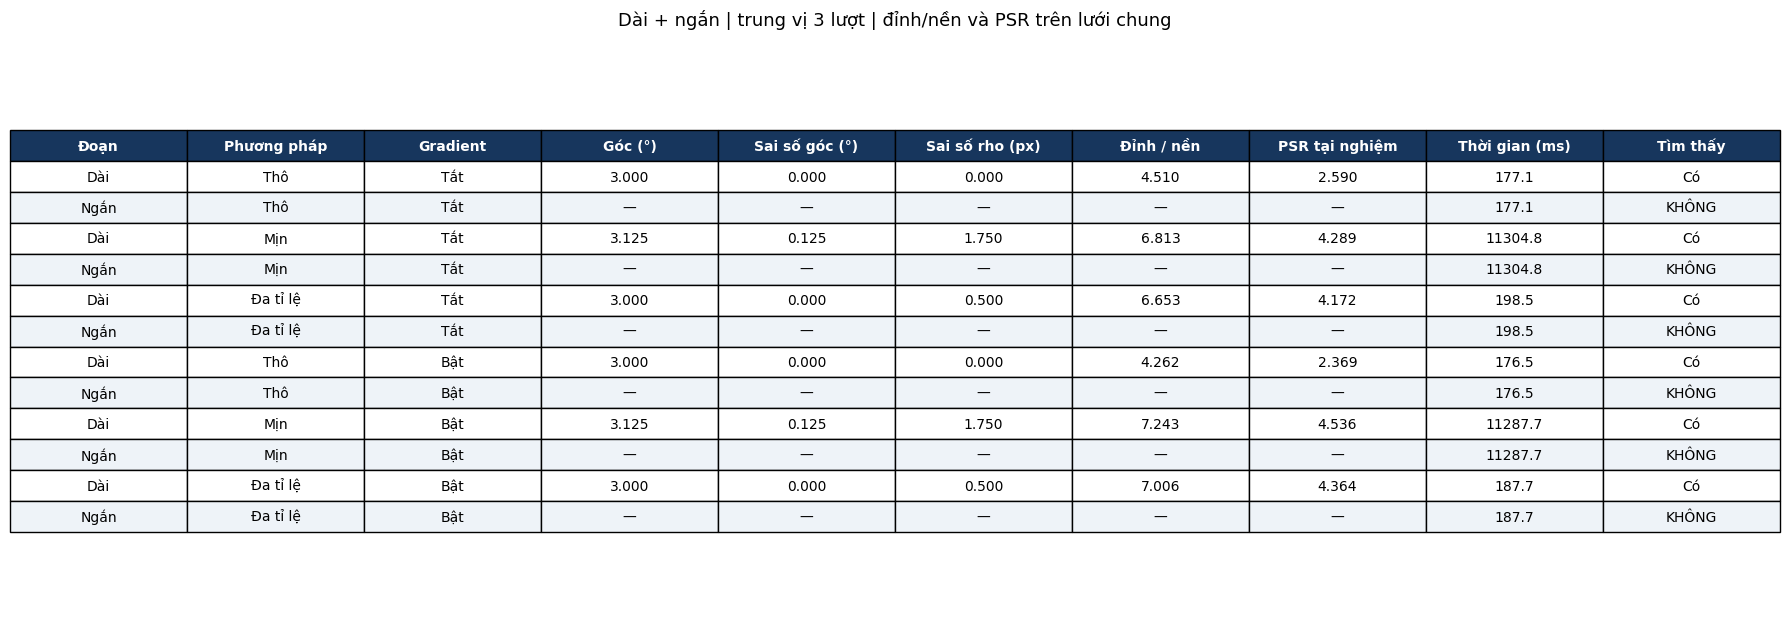

CHI TIẾT THỜI GIAN (ms): trung vị [min, max]
Gần 0°       | Tắt | Thô       |     173.3 [169.5, 174.5]
Gần 0°       | Tắt | Mịn       |   11221.4 [10914.7, 11273.9]
Gần 0°       | Tắt | Đa tỉ lệ  |     188.7 [183.1, 190.3]
Gần 0°       | Bật | Thô       |     176.9 [175.0, 179.6]
Gần 0°       | Bật | Mịn       |   11183.8 [11074.8, 11251.9]
Gần 0°       | Bật | Đa tỉ lệ  |     189.2 [186.9, 190.2]
Gần 180°     | Tắt | Thô       |     175.6 [171.7, 175.8]
Gần 180°     | Tắt | Mịn       |   11097.0 [11086.1, 11132.6]
Gần 180°     | Tắt | Đa tỉ lệ  |     186.8 [185.1, 190.6]
Gần 180°     | Bật | Thô       |     171.4 [170.3, 172.1]
Gần 180°     | Bật | Mịn       |   11215.7 [11008.2, 11452.0]
Gần 180°     | Bật | Đa tỉ lệ  |     185.2 [182.9, 191.4]
Dài + ngắn   | Tắt | Thô       |     177.1 [170.8, 195.0]
Dài + ngắn   | Tắt | Mịn       |   11304.8 [11123.0, 11410.5]
Dài + ngắn   | Tắt | Đa tỉ lệ  |     198.5 [190.5, 210.9]
Dài + ngắn   | Bật | Thô       |     176.5 [171.1, 195.5]
Dài + n

In [60]:
v3_records = []
for case in v3_cases:
    for mode in V3_MODES:
        grad = case['grad'] if mode == 'Bật' else None
        for method in V3_METHODS:
            run = v3_runs[(case['name'], mode, method)]
            matches = v3_match(run['peaks'], case['truth'])
            run['matches'] = matches
            for ti, (target, r0, t0, length) in enumerate(case['truth']):
                row = dict(image=case['name'], target=target, method=method,
                           gradient=mode, found=ti in matches,
                           theta=np.nan, angle_error=np.nan, rho_error=np.nan,
                           psr=np.nan, peak_ratio=np.nan, peak=np.nan, background=np.nan, time_ms=float(np.median(run['times'])))
                if ti in matches:
                    r, t = run['peaks'][matches[ti]]
                    row.update(theta=float(np.rad2deg(t)),
                               angle_error=v3_angle_error(t0, np.rad2deg(t)),
                               rho_error=v3_rho_error(r0, t0, r, np.rad2deg(t)))
                    row.update(v3_peak_metrics(case['edges'], grad, r, t))
                v3_records.append(row)

def v3_fmt(value, digits=3):
    return f'{value:.{digits}f}' if np.isfinite(value) else '—'

for case in v3_cases:
    rows = [r for r in v3_records if r['image'] == case['name']]
    values = [[r['target'], r['method'], r['gradient'], v3_fmt(r['theta']),
               v3_fmt(r['angle_error']), v3_fmt(r['rho_error']),
               v3_fmt(r['peak_ratio']), v3_fmt(r['psr']),
               v3_fmt(r['time_ms'], 1), 'Có' if r['found'] else 'KHÔNG'] for r in rows]
    fig, ax = plt.subplots(figsize=(18, 1.8 + 0.38 * len(rows)))
    ax.axis('off')
    table = ax.table(cellText=values,
        colLabels=['Đoạn', 'Phương pháp', 'Gradient', 'Góc (°)', 'Sai số góc (°)',
                   'Sai số rho (px)', 'Đỉnh / nền', 'PSR tại nghiệm', 'Thời gian (ms)', 'Tìm thấy'],
        loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.6)
    for (ri, ci), tc in table.get_celld().items():
        if ri == 0:
            tc.set_facecolor('#17365d')
            tc.set_text_props(color='white', weight='bold')
        elif ri % 2 == 0:
            tc.set_facecolor('#eef3f8')
    ax.set_title(case['name'] + ' | trung vị 3 lượt | đỉnh/nền và PSR trên lưới chung',
                 fontsize=13, pad=16)
    plt.tight_layout()
    plt.show()

print('CHI TIẾT THỜI GIAN (ms): trung vị [min, max]')
for (name, mode, method), run in v3_runs.items():
    t = run['times']
    print(f'{name:12s} | {mode:3s} | {method:9s} | '
          f'{np.median(t):9.1f} [{min(t):.1f}, {max(t):.1f}]')
print('\nSỐ LIỆU CHI TIẾT (để chép vào báo cáo):')
for row in v3_records:
    print(row)

### Biểu đồ sai số, PSR và thời gian


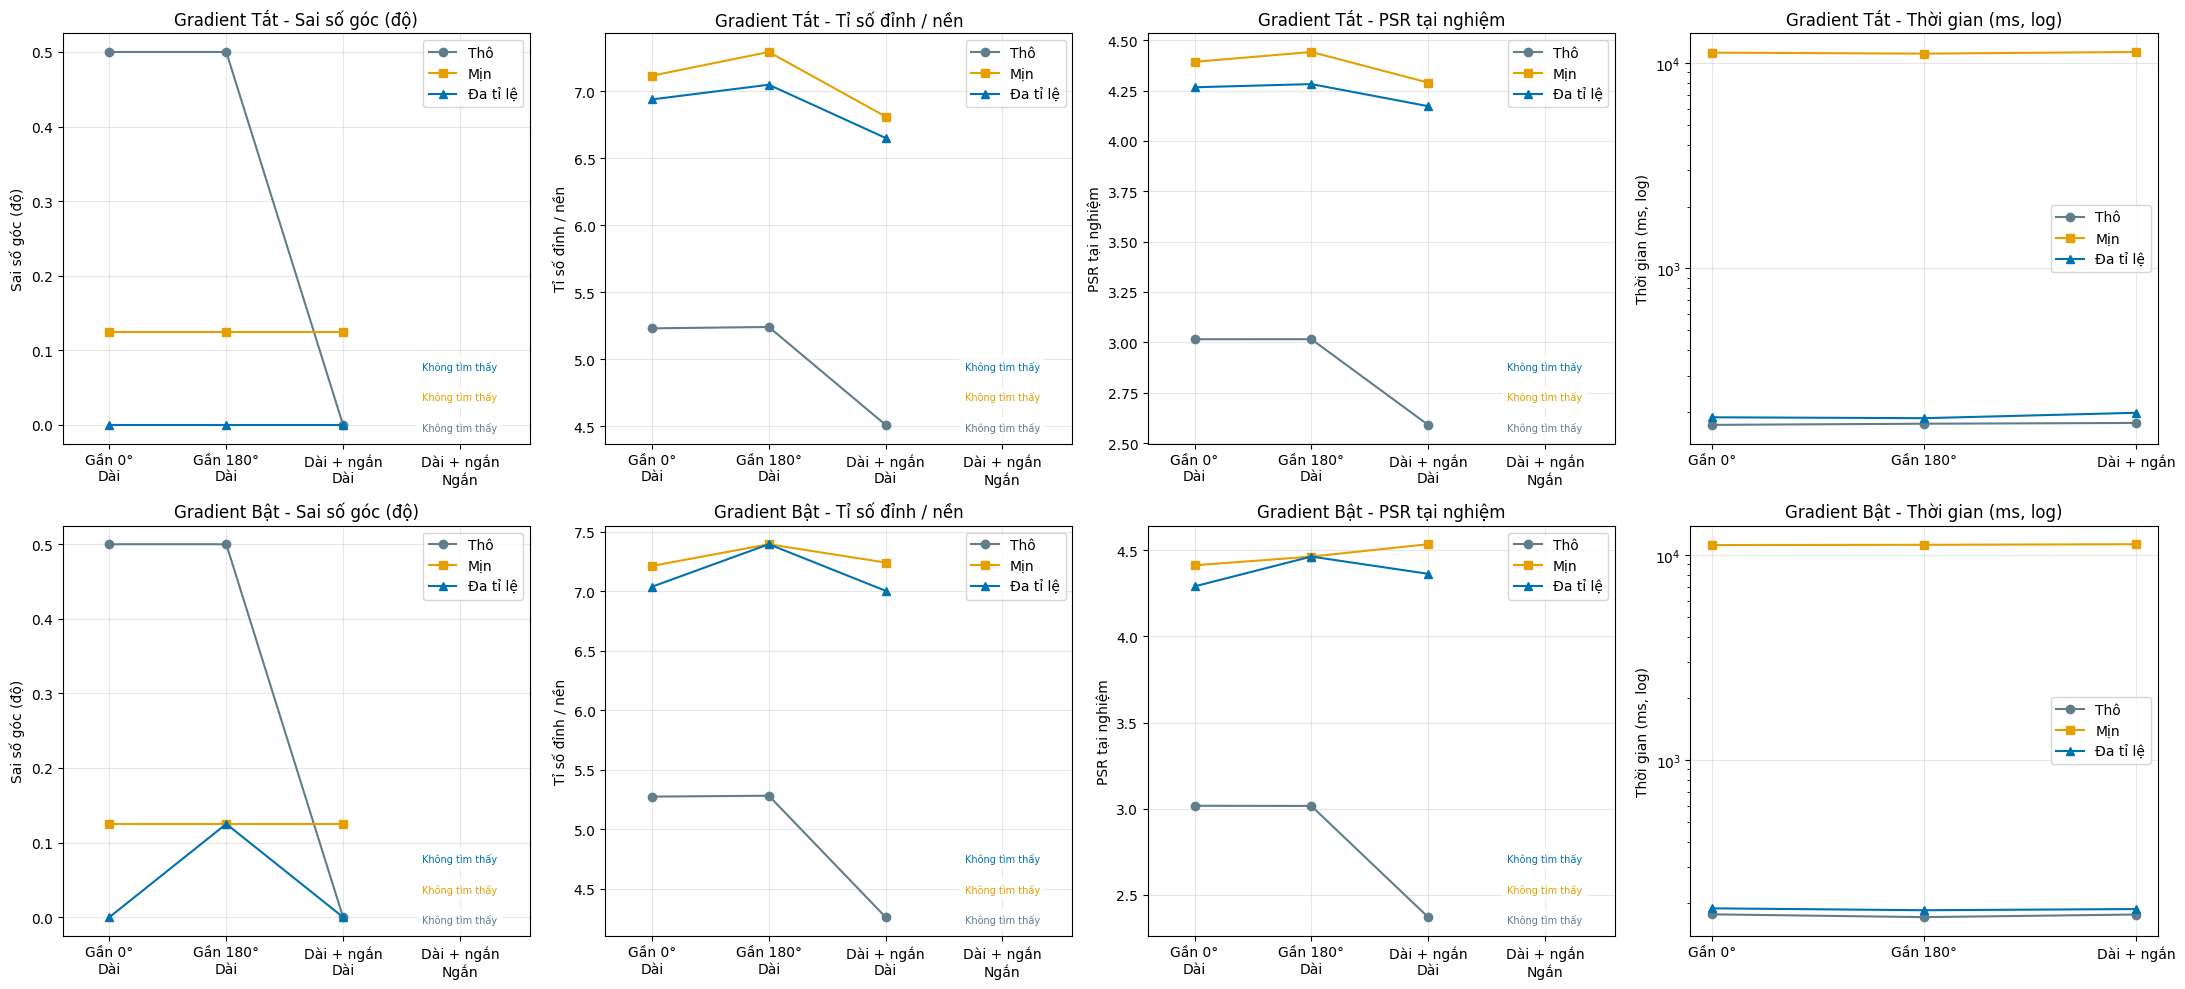

In [61]:
v3_labels = [(c['name'], target[0]) for c in v3_cases for target in c['truth']]
v3_colors = {'Thô': '#607d8b', 'Mịn': '#e69f00', 'Đa tỉ lệ': '#0072b2'}
v3_markers = {'Thô': 'o', 'Mịn': 's', 'Đa tỉ lệ': '^'}
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ri, mode in enumerate(V3_MODES):
    for mi, method in enumerate(V3_METHODS):
        selected = [next(r for r in v3_records if r['image'] == name
                         and r['target'] == target and r['method'] == method
                         and r['gradient'] == mode) for name, target in v3_labels]
        for ci, metric in enumerate(['angle_error', 'peak_ratio', 'psr']):
            ax = axes[ri, ci]
            ax.plot(range(len(selected)), [r[metric] for r in selected],
                    marker=v3_markers[method], linestyle='-',
                    label=method, color=v3_colors[method])
            for xi, row in enumerate(selected):
                if not row['found'] or not np.isfinite(row[metric]):
                    text = 'Không tìm thấy' if not row['found'] else 'Không xác định'
                    ax.text(xi, 0.03 + 0.075 * mi, text, transform=ax.get_xaxis_transform(),
                            ha='center', fontsize=7, color=v3_colors[method],
                            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
        ts = [np.median(v3_runs[(c['name'], mode, method)]['times']) for c in v3_cases]
        axes[ri, 3].plot(range(len(ts)), ts, marker=v3_markers[method],
                         label=method, color=v3_colors[method])
    for ci in range(3):
        axes[ri, ci].set_xticks(range(len(v3_labels)),
                              [f'{name}\n{target}' for name, target in v3_labels])
        axes[ri, ci].set_xlim(-0.4, len(v3_labels) - 0.4)
    axes[ri, 3].set_xticks(range(len(v3_cases)), [c['name'] for c in v3_cases])
    axes[ri, 3].set_yscale('log')
    for ci, ylabel in enumerate(['Sai số góc (độ)', 'Tỉ số đỉnh / nền',
                                  'PSR tại nghiệm', 'Thời gian (ms, log)']):
        axes[ri, ci].set_title(f'Gradient {mode} - {ylabel}')
        axes[ri, ci].set_ylabel(ylabel)
        axes[ri, ci].grid(alpha=0.3)
        axes[ri, ci].legend()
plt.tight_layout()
plt.show()


###  Kiểm tra trực quan đoạn dài và đoạn ngắn

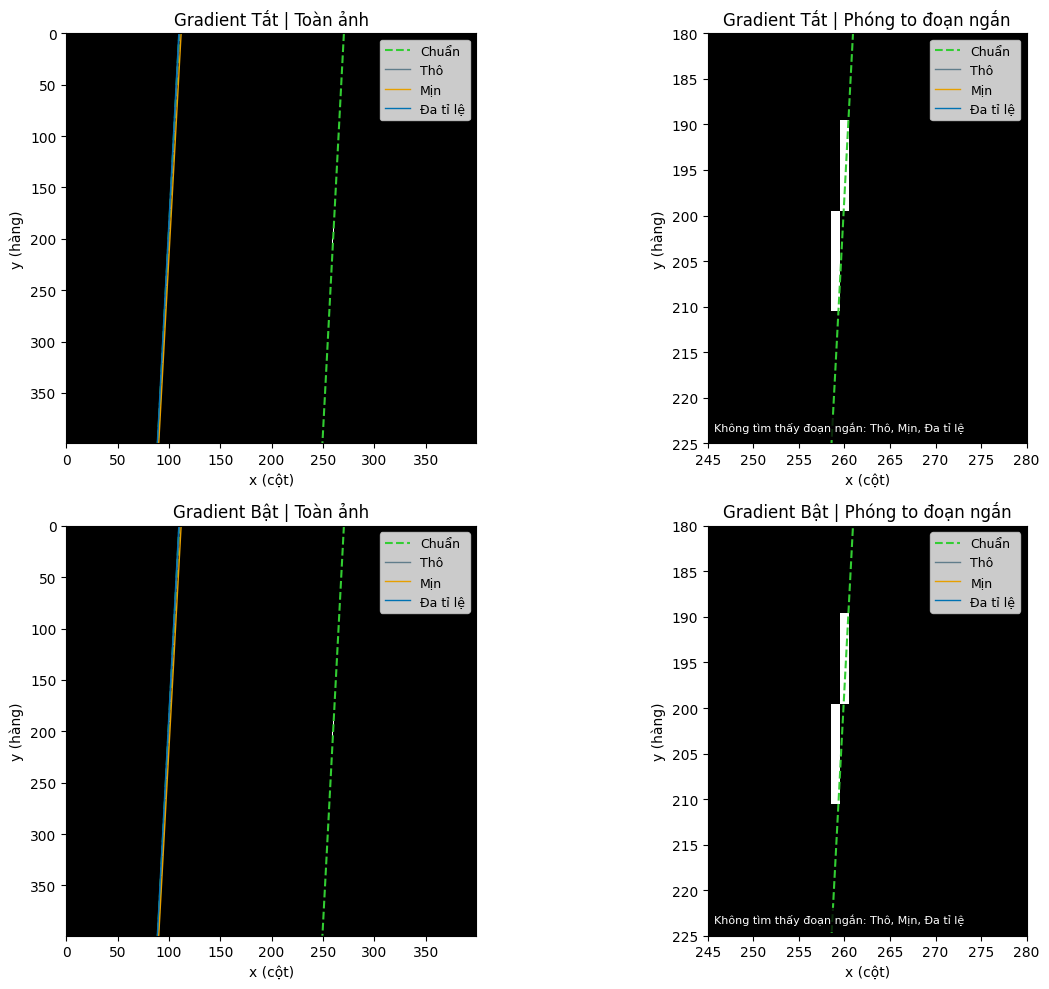

In [62]:
case = v3_cases[2]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
y = np.arange(case['image'].shape[0])
for ri, mode in enumerate(V3_MODES):
    for ci in range(2):
        ax = axes[ri, ci]
        ax.imshow(case['image'], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        for ti, (_, rho, td, _) in enumerate(case['truth']):
            t = np.deg2rad(td)
            ax.plot((rho - y * np.sin(t)) / np.cos(t), y,
                    '--', color='limegreen', linewidth=1.5,
                    label='Chuẩn' if ti == 0 else None)
        for method in V3_METHODS:
            run = v3_runs[(case['name'], mode, method)]
            labeled = False
            for ti, pi in run['matches'].items():
                rho, t = run['peaks'][pi]
                ax.plot((rho - y * np.sin(t)) / np.cos(t), y,
                        color=v3_colors[method], linewidth=1,
                        label=method if not labeled else None)
                labeled = True
        if ci == 0:
            ax.set_xlim(0, 399)
            ax.set_ylim(399, 0)
        else:
            ax.set_xlim(245, 280)
            ax.set_ylim(225, 180)
        ax.set_title(f'Gradient {mode} | ' + ('Toàn ảnh' if ci == 0 else 'Phóng to đoạn ngắn'))
        ax.set_xlabel('x (cột)')
        ax.set_ylabel('y (hàng)')
        ax.legend(fontsize=9)
        if ci == 1:
            missing = [method for method in V3_METHODS
                       if 1 not in v3_runs[(case['name'], mode, method)]['matches']]
            if missing:
                ax.text(0.02, 0.03, 'Không tìm thấy đoạn ngắn: ' + ', '.join(missing),
                        transform=ax.transAxes, color='white', fontsize=8,
                        bbox=dict(facecolor='black', alpha=0.8))
plt.tight_layout()
plt.show()

###  Nhận xét tự động từ kết quả

In [63]:
print('1. SO ĐA TỈ LỆ VỚI THÔ VÀ MỊN')
for name, target in v3_labels:
    for mode in V3_MODES:
        rr = {r['method']: r for r in v3_records if r['image'] == name
              and r['target'] == target and r['gradient'] == mode}
        c, f, m = [rr[key] for key in V3_METHODS]
        print(f'\n{name}, đoạn {target}, gradient {mode}:')
        for method in V3_METHODS:
            r = rr[method]
            if r['found']:
                print(f"  {method}: sai số góc {r['angle_error']:.3f}°, "
                      f"PSR {v3_fmt(r['psr'])}, {r['time_ms']:.1f} ms.")
            else:
                print(f'  {method}: KHÔNG TÌM THẤY trong cửa sổ ghép đã công bố.')
        if c['found'] and m['found']:
            print(f"  Đa tỉ lệ trừ thô: {m['angle_error'] - c['angle_error']:+.3f}° sai số.")
        print(f"  Tốc độ mịn/đa tỉ lệ: {f['time_ms'] / m['time_ms']:.2f} lần "
              '(>1: đa tỉ lệ nhanh hơn).')

print('\n2. ẢNH HƯỞNG BẬT GRADIENT: thời gian tắt/bật (>1: bật nhanh hơn)')
for case in v3_cases:
    for method in V3_METHODS:
        off = np.median(v3_runs[(case['name'], 'Tắt', method)]['times'])
        on = np.median(v3_runs[(case['name'], 'Bật', method)]['times'])
        print(f"{case['name']:12s} | {method:9s}: {off / on:.3f} lần")
        for target, *_ in case['truth']:
            rr = {r['gradient']: r for r in v3_records if r['image'] == case['name']
                  and r['target'] == target and r['method'] == method}
            if all(r['found'] for r in rr.values()):
                print(f"  {target}: sai số bật−tắt = "
                      f"{rr['Bật']['angle_error'] - rr['Tắt']['angle_error']:+.3f}°; "
                      f"PSR tắt/bật = {v3_fmt(rr['Tắt']['psr'])}/{v3_fmt(rr['Bật']['psr'])}.")
            else:
                print(f"  {target}: tìm thấy tắt/bật = {rr['Tắt']['found']}/{rr['Bật']['found']}.")

print('\n3. TỰ KIỂM TRA')
assert len(v3_runs) == 18 and len(v3_records) == 24
assert all(len(r['times']) == V3_REPEATS for r in v3_runs.values())
assert all(np.isfinite(r['times']).all() and min(r['times']) > 0 for r in v3_runs.values())
assert all(0 <= t < np.pi for r in v3_runs.values() for _, t in r['peaks'])
for method in V3_METHODS:
    rs = [r for r in v3_records if r['method'] == method]
    print(f'{method}: tìm thấy {sum(r["found"] for r in rs)}/{len(rs)} đường chuẩn qua 2 chế độ.')
print('Đủ 3 phương pháp × 2 chế độ × 3 ảnh; đủ sai số góc, PSR và thời gian.')
print('NaN/— ở kết quả không tìm thấy hoặc PSR không xác định không được đổi thành 0.')

1. SO ĐA TỈ LỆ VỚI THÔ VÀ MỊN

Gần 0°, đoạn Dài, gradient Tắt:
  Thô: sai số góc 0.500°, PSR 3.015, 173.3 ms.
  Mịn: sai số góc 0.125°, PSR 4.392, 11221.4 ms.
  Đa tỉ lệ: sai số góc 0.000°, PSR 4.266, 188.7 ms.
  Đa tỉ lệ trừ thô: -0.500° sai số.
  Tốc độ mịn/đa tỉ lệ: 59.46 lần (>1: đa tỉ lệ nhanh hơn).

Gần 0°, đoạn Dài, gradient Bật:
  Thô: sai số góc 0.500°, PSR 3.016, 176.9 ms.
  Mịn: sai số góc 0.125°, PSR 4.414, 11183.8 ms.
  Đa tỉ lệ: sai số góc 0.000°, PSR 4.291, 189.2 ms.
  Đa tỉ lệ trừ thô: -0.500° sai số.
  Tốc độ mịn/đa tỉ lệ: 59.11 lần (>1: đa tỉ lệ nhanh hơn).

Gần 180°, đoạn Dài, gradient Tắt:
  Thô: sai số góc 0.500°, PSR 3.016, 175.6 ms.
  Mịn: sai số góc 0.125°, PSR 4.441, 11097.0 ms.
  Đa tỉ lệ: sai số góc 0.000°, PSR 4.282, 186.8 ms.
  Đa tỉ lệ trừ thô: -0.500° sai số.
  Tốc độ mịn/đa tỉ lệ: 59.41 lần (>1: đa tỉ lệ nhanh hơn).

Gần 180°, đoạn Dài, gradient Bật:
  Thô: sai số góc 0.500°, PSR 3.015, 171.4 ms.
  Mịn: sai số góc 0.125°, PSR 4.465, 11215.7 ms.
  Đa tỉ l

In [64]:
v3_short_trials = []
case = v3_cases[2]
trial_configs = [(10, 6.0, 3.0), (30, 6.0, 3.0), (30, 12.0, 6.0)]
print('THỬ THÊM SỐ ĐỈNH / NMS - cùng ảnh dài + ngắn, không dùng đáp án để tìm đỉnh')
print('Phương pháp | Gradient | Số đỉnh | NMS px/độ | Tìm dài/ngắn | Sai số góc đoạn ngắn')
for mode in V3_MODES:
    grad = case['grad'] if mode == 'Bật' else None
    for method in ['Thô', 'Đa tỉ lệ']:
        for n_peaks, nr, nt in trial_configs:
            if (n_peaks, nr, nt) == trial_configs[0]:
                peaks = v3_runs[(case['name'], mode, method)]['peaks']
            else:
                peaks = v3_detect(case['edges'], grad, method,
                                  n_peaks=n_peaks, nms_rho=nr, nms_theta=nt)
            matches = v3_match(peaks, case['truth'])
            error = np.nan
            if 1 in matches:
                error = v3_angle_error(3, np.rad2deg(peaks[matches[1]][1]))
            v3_short_trials.append(dict(method=method, gradient=mode,
                n_peaks=n_peaks, nms_rho=nr, nms_theta=nt,
                long_found=0 in matches, short_found=1 in matches, short_angle_error=error))
            print(f'{method:9s} | {mode:3s} | {n_peaks:2d} | {nr:g}/{nt:g} | '
                  f'{0 in matches}/{1 in matches} | {v3_fmt(error)}')
print('Thử thêm chỉ áp dụng thô và đa tỉ lệ; bảng chính vẫn giữ nguyên 18 cấu hình.')


THỬ THÊM SỐ ĐỈNH / NMS - cùng ảnh dài + ngắn, không dùng đáp án để tìm đỉnh
Phương pháp | Gradient | Số đỉnh | NMS px/độ | Tìm dài/ngắn | Sai số góc đoạn ngắn
Thô       | Tắt | 10 | 6/3 | True/False | —
Thô       | Tắt | 30 | 6/3 | True/True | 0.000
Thô       | Tắt | 30 | 12/6 | True/True | 0.000
Đa tỉ lệ  | Tắt | 10 | 6/3 | True/False | —
Đa tỉ lệ  | Tắt | 30 | 6/3 | True/True | 0.375
Đa tỉ lệ  | Tắt | 30 | 12/6 | True/True | 0.375
Thô       | Bật | 10 | 6/3 | True/False | —
Thô       | Bật | 30 | 6/3 | True/True | 2.000
Thô       | Bật | 30 | 12/6 | True/True | 0.000
Đa tỉ lệ  | Bật | 10 | 6/3 | True/False | —
Đa tỉ lệ  | Bật | 30 | 6/3 | True/True | 1.375
Đa tỉ lệ  | Bật | 30 | 12/6 | True/True | 0.375
Thử thêm chỉ áp dụng thô và đa tỉ lệ; bảng chính vẫn giữ nguyên 18 cấu hình.


In [65]:
def create_line_image(segments, size=400):
    image = np.zeros((size, size), dtype=np.uint8)
    answers = []

    for rho0, theta0, length in segments:
        theta = np.deg2rad(theta0)

        normal = np.array([np.cos(theta), np.sin(theta)])
        direction = np.array([-np.sin(theta), np.cos(theta)])

        center = normal * rho0
        # Lấy tâm đoạn là giao điểm với đường giữa ảnh: y = size/2 nếu đường gần dọc,
        # x = size/2 nếu đường gần ngang (tránh chia cho 0 khi theta = 90°)
        if abs(direction[1]) >= abs(direction[0]):
            center = center + direction * (size / 2 - center[1]) / direction[1]
        else:
            center = center + direction * (size / 2 - center[0]) / direction[0]

        p1 = center - direction * length / 2
        p2 = center + direction * length / 2

        if np.any(p1 < 0) or np.any(p1 >= size) or np.any(p2 < 0) or np.any(p2 >= size):
            raise ValueError("Đoạn thẳng nằm ngoài ảnh")

        shift = 8
        scale = 1 << shift

        pt1 = tuple(np.rint(p1 * scale).astype(int))
        pt2 = tuple(np.rint(p2 * scale).astype(int))

        cv2.line(image, pt1, pt2, 255, 1, cv2.LINE_8, shift)

        answers.append((rho0, theta0, length))

    return image, answers

In [66]:
# Kiểm tra đường ngang: pháp tuyến 90° (y = 200), dài 20 px
horizontal_image, _ = create_line_image([(200, 90, 20)])
ys, xs = np.nonzero(horizontal_image)
print(f"Số pixel: {len(xs)}, y thuộc [{ys.min()}, {ys.max()}], x thuộc [{xs.min()}, {xs.max()}]")

Số pixel: 21, y thuộc [200, 200], x thuộc [190, 210]


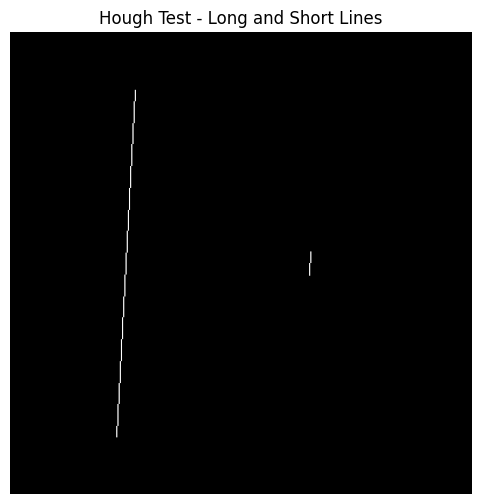

Đoạn 1: rho = 110, theta = 3°, length = 300px
Đoạn 2: rho = 270, theta = 3°, length = 20px


In [67]:
segments = [
    (110, 3, 300),
    (270, 3, 20)
]

hough_image, answers = create_line_image(segments)

cv2.imwrite(str(IMG_DIR / "hough_test.png"), hough_image)

plt.figure(figsize=(6, 6))
plt.imshow(hough_image, cmap="gray", vmin=0, vmax=255)
plt.title("Hough Test - Long and Short Lines")
plt.axis("off")
plt.show()

for i, (rho, theta, length) in enumerate(answers, 1):
    print(f"Đoạn {i}: rho = {rho}, theta = {theta}°, length = {length}px")

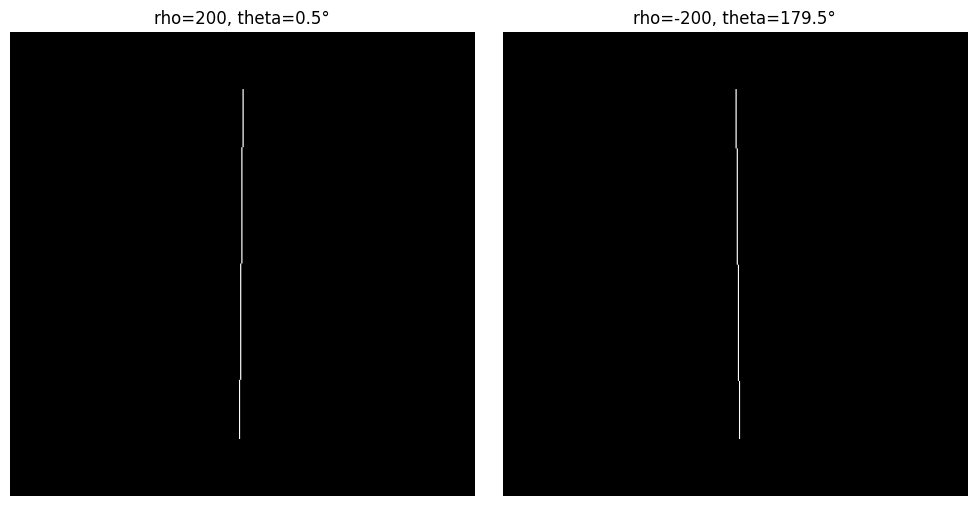

In [68]:
angle_tests = [
    (200, 0.5, 300),
    (-200, 179.5, 300)
]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (rho, theta, length) in zip(axes, angle_tests):
    image, answer = create_line_image([(rho, theta, length)])

    filename = f"hough_angle_{str(theta).replace('.', '_')}.png"
    cv2.imwrite(str(IMG_DIR / filename), image)

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rho={rho}, theta={theta}°")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [69]:
def hough_errors(rho_true, theta_true_deg, rho_detected, theta_detected_rad):
    t0 = np.deg2rad(theta_true_deg)
    t1 = theta_detected_rad

    delta = (t1 - t0 + np.pi / 2) % np.pi - np.pi / 2
    sign = 1 if np.cos(t1 - t0) >= 0 else -1

    return abs(np.rad2deg(delta)), abs(rho_true - sign * rho_detected)


def strongest_peak(edges, theta_step_deg=1, rho_step=1, n_peaks=1):
    h, w = edges.shape

    D = np.ceil(np.hypot(h - 1, w - 1) / rho_step) * rho_step
    n_theta = int(np.ceil(180 / theta_step_deg))
    n_rho = int(round(2 * D / rho_step)) + 1

    A, thetas, rhos = hough_accumulate(
        edges,
        n_theta=n_theta,
        rho_range=(-D, D),
        n_rho=n_rho
    )

    peaks = find_peaks(
        A,
        n_peaks,
        thetas=thetas,
        rhos=rhos,
        smooth_sigma=0,
        nms_radius=5
    )

    return A, thetas, rhos, peaks

In [70]:
def draw_line(ax, rho, theta_rad, size, **kwargs):
    """Vẽ đường x*cos(theta) + y*sin(theta) = rho trong khung ảnh size x size."""
    c, s = np.cos(theta_rad), np.sin(theta_rad)
    if abs(s) >= abs(c):
        x = np.array([0, size - 1], dtype=np.float64)
        y = (rho - x * c) / s
    else:
        y = np.array([0, size - 1], dtype=np.float64)
        x = (rho - y * s) / c
    ax.plot(x, y, **kwargs)


def show_lines(ax, image, truths, detections, title):
    """truths: [(rho, theta_deg, ...)], detections: [(rho, theta_rad, ...)]."""
    size = image.shape[0]
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    for k, (rho, theta_deg, *_) in enumerate(truths):
        draw_line(ax, rho, np.deg2rad(theta_deg), size, color="lime", ls="--", lw=1.5,
                  label="Ground truth" if k == 0 else None)
    for k, (rho, theta, *_) in enumerate(detections):
        draw_line(ax, rho, theta, size, color="red", lw=0.8, alpha=0.8,
                  label="Detected" if k == 0 else None)
    ax.set_xlim(0, size - 1)
    ax.set_ylim(size - 1, 0)
    ax.set_title(title)
    ax.axis("off")
    ax.legend(fontsize=8, loc="lower right")

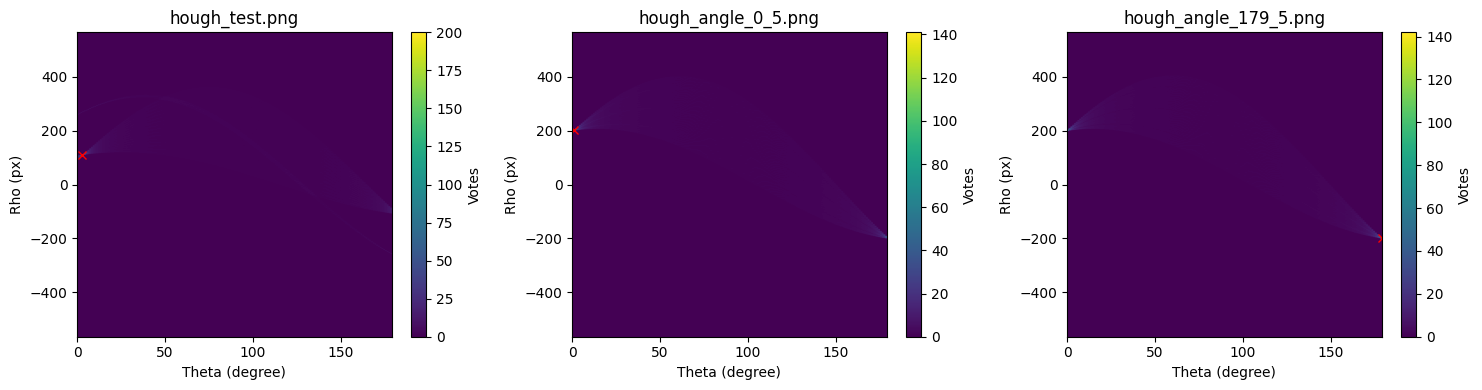

In [71]:
images = {
    "hough_test.png": hough_image
}

for rho, theta, length in angle_tests:
    image, _ = create_line_image([(rho, theta, length)])
    filename = f"hough_angle_{str(theta).replace('.', '_')}.png"
    images[filename] = image

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (filename, image) in zip(axes, images.items()):
    A, thetas, rhos, peaks = strongest_peak(image > 0)

    im = ax.imshow(
        A,
        origin="lower",
        aspect="auto",
        extent=[
            np.rad2deg(thetas[0]),
            np.rad2deg(thetas[-1]),
            rhos[0],
            rhos[-1]
        ]
    )

    for rho, theta, votes in peaks:
        ax.plot(np.rad2deg(theta), rho, "rx")

    ax.set_title(filename)
    ax.set_xlabel("Theta (degree)")
    ax.set_ylabel("Rho (px)")

    fig.colorbar(im, ax=ax, label="Votes")

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_accumulator.png", dpi=300, bbox_inches="tight")
plt.show()

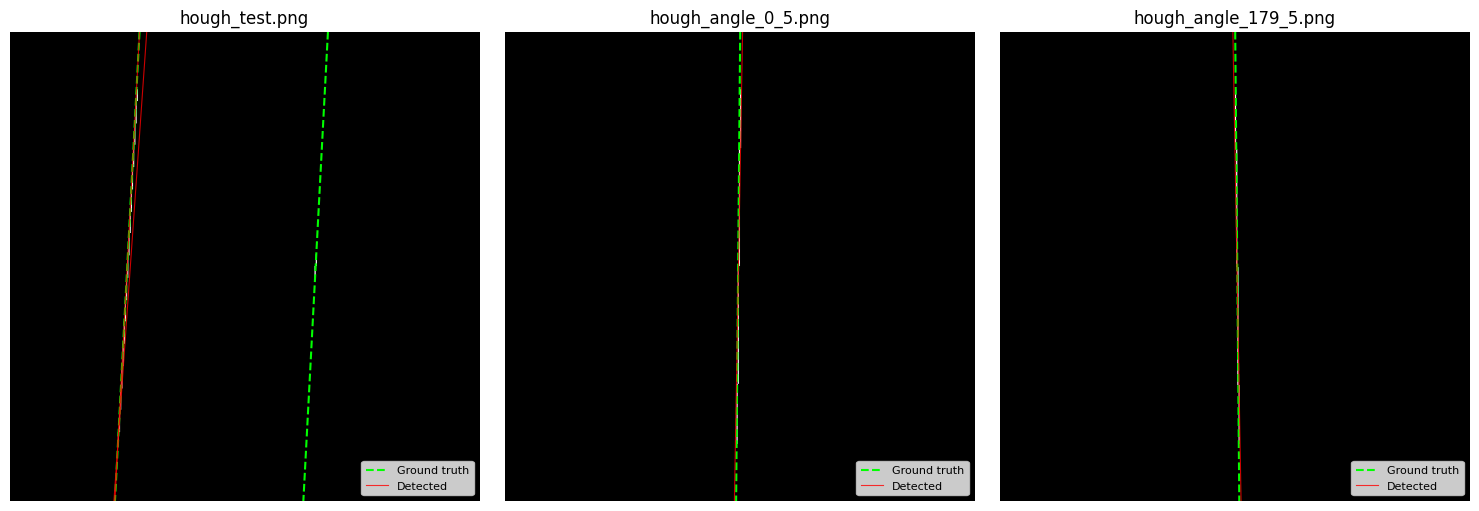

In [72]:
# Đường chuẩn (xanh, nét đứt) và đường tìm được từ đỉnh mạnh nhất (đỏ) vẽ chồng lên ảnh gốc
truth_by_image = {
    "hough_test.png": answers,
    "hough_angle_0_5.png": [angle_tests[0]],
    "hough_angle_179_5.png": [angle_tests[1]]
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (filename, image) in zip(axes, images.items()):
    _, _, _, peaks = strongest_peak(image > 0, n_peaks=len(truth_by_image[filename]))
    show_lines(ax, image, truth_by_image[filename], peaks, filename)

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_lines_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

In [73]:
theta_steps = [2, 1, 0.5, 0.25]
rho_steps = [4, 2, 1, 0.5]

angle_cases = [
    ("hough_angle_0_5.png", 200, 0.5),
    ("hough_angle_179_5.png", -200, 179.5)
]

scan_rows = []
scan_accumulators = {}

for variable, values in [("theta", theta_steps), ("rho", rho_steps)]:
    for step in values:
        for filename, rho0, theta0 in angle_cases:
            dt = step if variable == "theta" else 1
            dr = step if variable == "rho" else 1

            A, thetas, rhos, peaks = strongest_peak(
                images[filename] > 0,
                theta_step_deg=dt,
                rho_step=dr
            )

            scan_accumulators[(variable, step, filename)] = (A, thetas, rhos, peaks)

            if peaks:
                rho, theta, votes = peaks[0]
                et, er = hough_errors(rho0, theta0, rho, theta)
            else:
                rho, theta, votes = np.nan, np.nan, 0
                et, er = np.nan, np.nan

            scan_rows.append({
                "variable": variable,
                "step": step,
                "image": filename,
                "rho": rho,
                "theta_deg": np.rad2deg(theta),
                "votes": votes,
                "error_theta": et,
                "error_rho": er
            })

print("Parameter | Step | Image | Angle Error | Rho Error")

for r in scan_rows:
    print(
        f"{r['variable']:7s} | "
        f"{r['step']:4g} | "
        f"{r['image']:23s} | "
        f"{r['error_theta']:10.3f} | "
        f"{r['error_rho']:10.3f}"
    )

Parameter | Step | Image | Angle Error | Rho Error
theta   |    2 | hough_angle_0_5.png     |      0.500 |      2.000
theta   |    2 | hough_angle_179_5.png   |      0.500 |      1.000
theta   |    1 | hough_angle_0_5.png     |      0.500 |      2.000
theta   |    1 | hough_angle_179_5.png   |      0.500 |      2.000
theta   |  0.5 | hough_angle_0_5.png     |      0.000 |      0.000
theta   |  0.5 | hough_angle_179_5.png   |      0.000 |      0.000
theta   | 0.25 | hough_angle_0_5.png     |      0.250 |      1.000
theta   | 0.25 | hough_angle_179_5.png   |      0.250 |      1.000
rho     |    4 | hough_angle_0_5.png     |      0.500 |      0.000
rho     |    4 | hough_angle_179_5.png   |      0.500 |      0.000
rho     |    2 | hough_angle_0_5.png     |      0.500 |      2.000
rho     |    2 | hough_angle_179_5.png   |      0.500 |      2.000
rho     |    1 | hough_angle_0_5.png     |      0.500 |      2.000
rho     |    1 | hough_angle_179_5.png   |      0.500 |      2.000
rho     |  

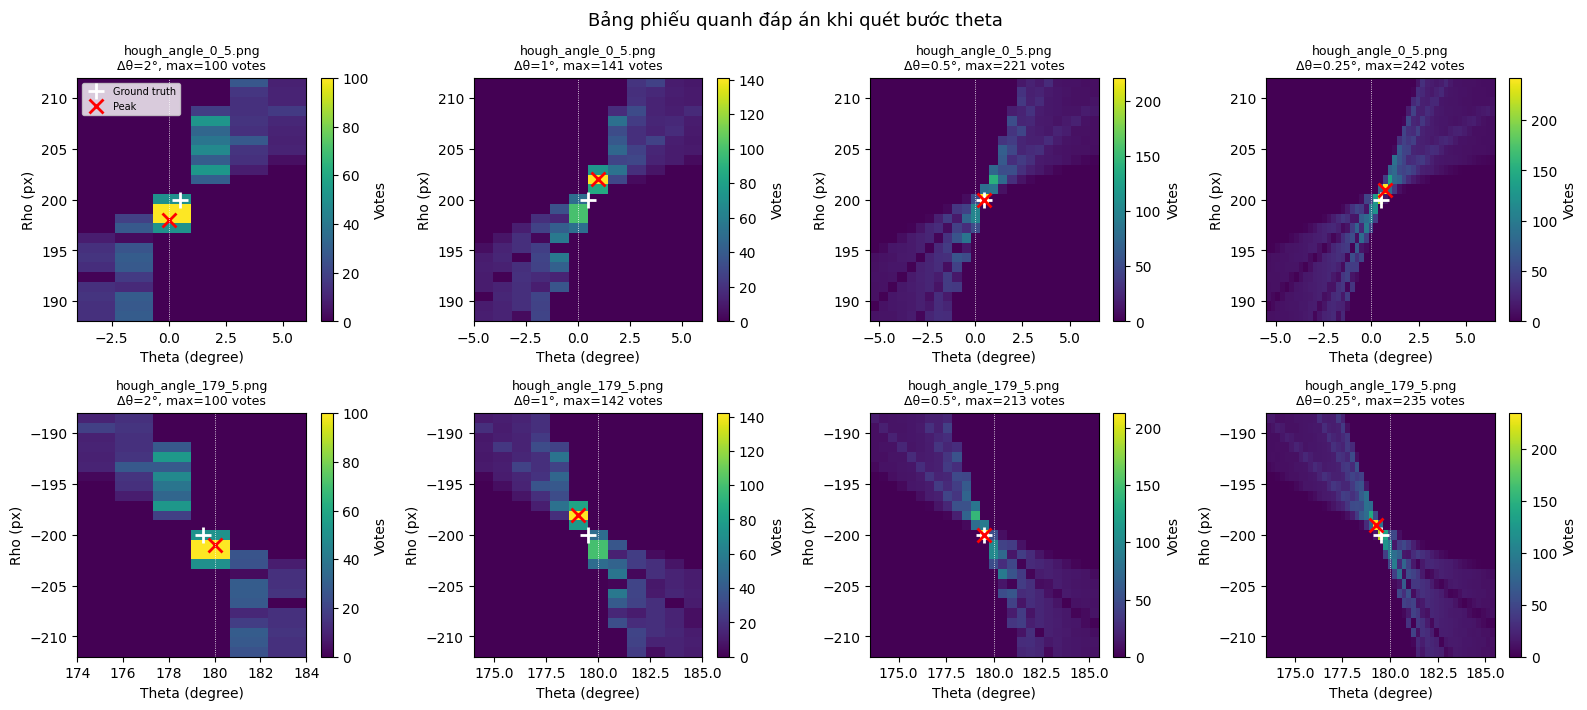

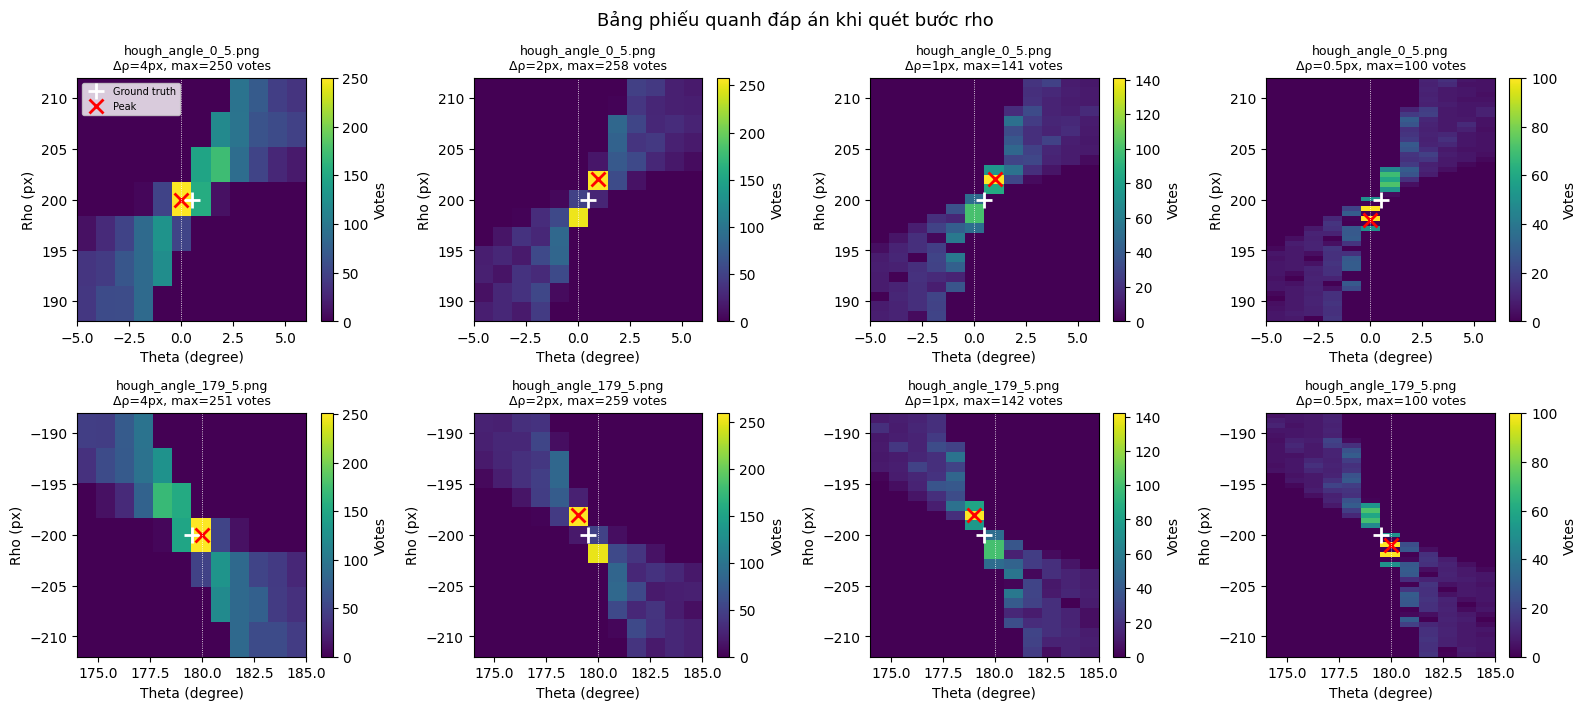

In [74]:
def zoom_accumulator(A, thetas, rhos, rho0, theta0_deg, half_theta=6, half_rho=12):
    """Cắt vùng bảng phiếu quanh đáp án. Nối thêm cột quấn vòng ở hai biên theta
    (theta ± 180°, rho đổi dấu) để thấy được đỉnh bị tách qua biên 0°/180°."""
    k = len(thetas) // 4
    A_ext = np.hstack([A[::-1, -k:], A, A[::-1, :k]])
    t_ext = np.rad2deg(np.concatenate([thetas[-k:] - np.pi, thetas, thetas[:k] + np.pi]))

    cols = np.abs(t_ext - theta0_deg) <= half_theta
    rows = np.abs(rhos - rho0) <= half_rho
    return A_ext[np.ix_(rows, cols)], t_ext[cols], rhos[rows]


def unwrap_peak(rho, theta_rad, theta0_deg):
    """Đưa đỉnh về cùng phía biên với đáp án để vẽ lên vùng đã cắt."""
    t = np.rad2deg(theta_rad)
    if t - theta0_deg > 90:
        return -rho, t - 180
    if theta0_deg - t > 90:
        return -rho, t + 180
    return rho, t


for variable, values in [("theta", theta_steps), ("rho", rho_steps)]:
    fig, axes = plt.subplots(len(angle_cases), len(values), figsize=(4 * len(values), 3.6 * len(angle_cases)))

    for row, (filename, rho0, theta0) in enumerate(angle_cases):
        for col, step in enumerate(values):
            ax = axes[row, col]
            A, thetas, rhos, peaks = scan_accumulators[(variable, step, filename)]
            Z, tz, rz = zoom_accumulator(A, thetas, rhos, rho0, theta0)

            im = ax.imshow(
                Z, origin="lower", aspect="auto", interpolation="nearest",
                extent=[tz[0], tz[-1], rz[0], rz[-1]]
            )
            ax.plot(theta0, rho0, "w+", ms=12, mew=2, label="Ground truth")
            if peaks:
                pr, pt = unwrap_peak(peaks[0][0], peaks[0][1], theta0)
                ax.plot(pt, pr, "rx", ms=10, mew=2, label="Peak")
            ax.axvline(0 if theta0 < 90 else 180, color="w", lw=0.6, ls=":")

            step_label = f"Δθ={step}°" if variable == "theta" else f"Δρ={step}px"
            ax.set_title(f"{filename}\n{step_label}, max={A.max()} votes", fontsize=9)
            ax.set_xlabel("Theta (degree)")
            ax.set_ylabel("Rho (px)")
            fig.colorbar(im, ax=ax, label="Votes")

    axes[0, 0].legend(fontsize=7, loc="upper left")
    fig.suptitle(f"Bảng phiếu quanh đáp án khi quét bước {variable}", fontsize=13)
    plt.tight_layout()
    plt.savefig(IMG_DIR / f"hough_vote_tables_{variable}.png", dpi=200, bbox_inches="tight")
    plt.show()

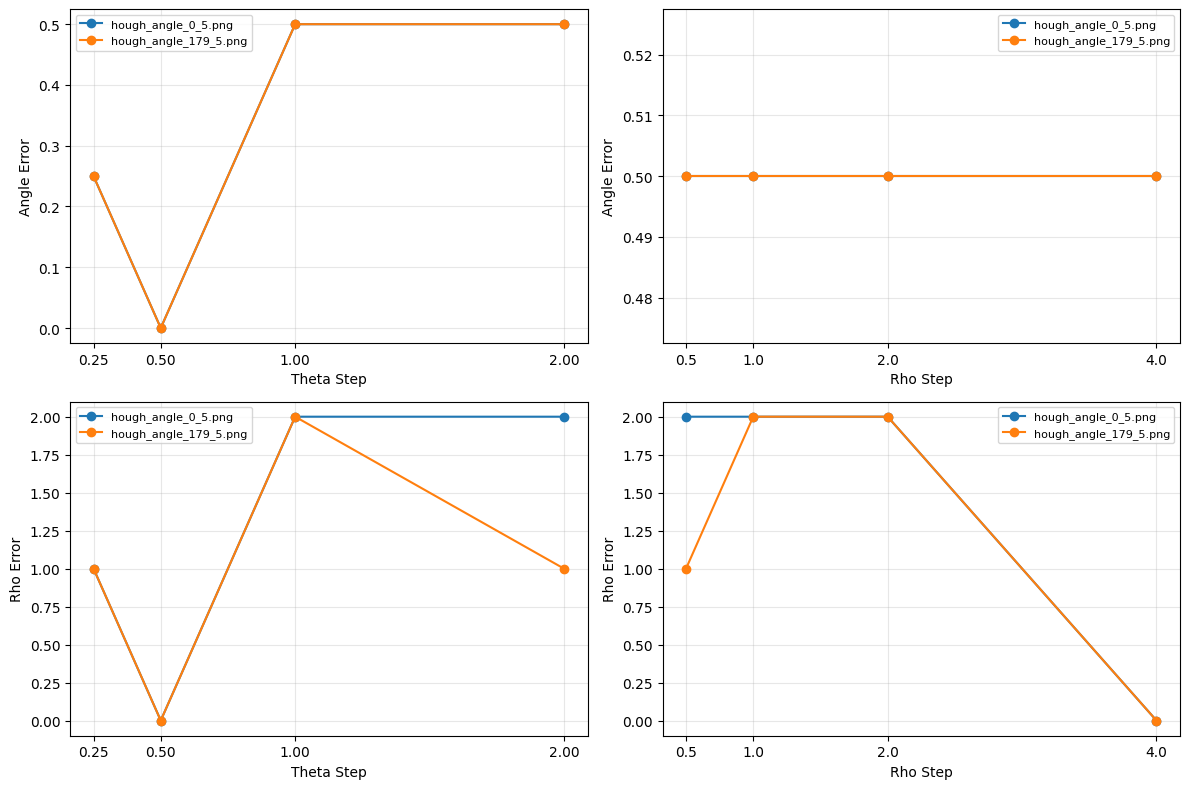

In [75]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, variable in enumerate(["theta", "rho"]):
    subset = [r for r in scan_rows if r["variable"] == variable]

    for filename, _, _ in angle_cases:
        rows = [r for r in subset if r["image"] == filename]

        for row, key in enumerate(["error_theta", "error_rho"]):
            axes[row, col].plot(
                [r["step"] for r in rows],
                [r[key] for r in rows],
                "o-",
                label=filename
            )

    for row in range(2):
        ax = axes[row, col]

        ax.set_xlabel("Theta Step" if variable == "theta" else "Rho Step")
        ax.set_ylabel("Angle Error" if row == 0 else "Rho Error")
        ax.set_xticks(theta_steps if variable == "theta" else rho_steps)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_parameter_errors.png", dpi=300, bbox_inches="tight")
plt.show()

In [76]:
level_rows = []

for n_levels in [0, 1, 2, 3]:
    for filename, rho0, theta0 in angle_cases:
        lines = hough_multiscale(
            images[filename] > 0,
            None,
            n_levels=n_levels,
            n_peaks=5,
            rho_step=2,
            theta_step_deg=1
        )

        if lines:
            rho, theta = lines[0]
            et, er = hough_errors(rho0, theta0, rho, theta)
        else:
            rho, theta = np.nan, np.nan
            et, er = np.nan, np.nan

        level_rows.append({
            "level": n_levels,
            "image": filename,
            "rho": rho,
            "theta_deg": np.rad2deg(theta),
            "error_theta": et,
            "error_rho": er
        })

print("Levels | Image | Detected Angle | Angle Error | Rho Error")

for r in level_rows:
    print(
        f"{r['level']:6d} | "
        f"{r['image']:23s} | "
        f"{r['theta_deg']:14.3f} | "
        f"{r['error_theta']:11.3f} | "
        f"{r['error_rho']:9.3f}"
    )

Levels | Image | Detected Angle | Angle Error | Rho Error
     0 | hough_angle_0_5.png     |          1.000 |       0.500 |     2.000
     0 | hough_angle_179_5.png   |        179.000 |       0.500 |     2.000
     1 | hough_angle_0_5.png     |          0.625 |       0.125 |     0.750
     1 | hough_angle_179_5.png   |        179.375 |       0.125 |     0.750
     2 | hough_angle_0_5.png     |          0.625 |       0.125 |     0.688
     2 | hough_angle_179_5.png   |        179.375 |       0.125 |     0.688
     3 | hough_angle_0_5.png     |          0.625 |       0.125 |     0.695
     3 | hough_angle_179_5.png   |        179.375 |       0.125 |     0.672


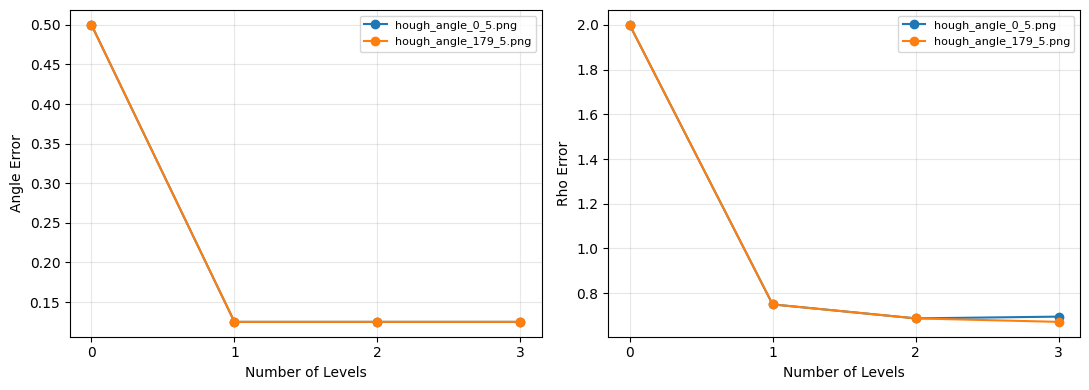

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for filename, _, _ in angle_cases:
    rows = [r for r in level_rows if r["image"] == filename]

    for ax, key in zip(axes, ["error_theta", "error_rho"]):
        ax.plot(
            [r["level"] for r in rows],
            [r[key] for r in rows],
            "o-",
            label=filename
        )

for ax, ylabel in zip(axes, ["Angle Error", "Rho Error"]):
    ax.set_xlabel("Number of Levels")
    ax.set_ylabel(ylabel)
    ax.set_xticks([0, 1, 2, 3])
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_multiscale_errors.png", dpi=300, bbox_inches="tight")
plt.show()

### Quét hệ số tinh chỉnh `refine_factor`

Giữ cố định lưới thô (Δρ = 2 px, Δθ = 1°), quét `refine_factor` ∈ {2, 4, 8, 16} với số tầng 1, 2, 3; ghi sai số và thời gian chạy.

In [78]:
refine_factors = [2, 4, 8, 16]
refine_levels = [1, 2, 3]
refine_rows = []

for n_levels in refine_levels:
    for refine_factor in refine_factors:
        for filename, rho0, theta0 in angle_cases:
            start = time.perf_counter()
            lines = hough_multiscale(
                images[filename] > 0,
                None,
                n_levels=n_levels,
                refine_factor=refine_factor,
                n_peaks=5,
                rho_step=2,
                theta_step_deg=1
            )
            elapsed = time.perf_counter() - start

            if lines:
                rho, theta = lines[0]
                et, er = hough_errors(rho0, theta0, rho, theta)
            else:
                rho, theta = np.nan, np.nan
                et, er = np.nan, np.nan

            refine_rows.append({
                "level": n_levels,
                "factor": refine_factor,
                "image": filename,
                "theta_deg": np.rad2deg(theta),
                "error_theta": et,
                "error_rho": er,
                "time": elapsed
            })

print("Levels | Factor | Image                   | Detected Angle | Angle Error | Rho Error | Time (s)")

for r in refine_rows:
    print(
        f"{r['level']:6d} | "
        f"{r['factor']:6d} | "
        f"{r['image']:23s} | "
        f"{r['theta_deg']:14.3f} | "
        f"{r['error_theta']:11.4f} | "
        f"{r['error_rho']:9.4f} | "
        f"{r['time']:8.3f}"
    )

Levels | Factor | Image                   | Detected Angle | Angle Error | Rho Error | Time (s)
     1 |      2 | hough_angle_0_5.png     |          0.500 |      0.0000 |    0.0000 |    0.177
     1 |      2 | hough_angle_179_5.png   |        179.500 |      0.0000 |    0.0000 |    0.176
     1 |      4 | hough_angle_0_5.png     |          0.750 |      0.2500 |    1.0000 |    0.181
     1 |      4 | hough_angle_179_5.png   |        179.250 |      0.2500 |    1.0000 |    0.184
     1 |      8 | hough_angle_0_5.png     |          0.625 |      0.1250 |    0.7500 |    0.221
     1 |      8 | hough_angle_179_5.png   |        179.375 |      0.1250 |    0.7500 |    0.190
     1 |     16 | hough_angle_0_5.png     |          0.688 |      0.1875 |    0.8750 |    0.188
     1 |     16 | hough_angle_179_5.png   |        179.312 |      0.1875 |    0.8750 |    0.186
     2 |      2 | hough_angle_0_5.png     |          0.500 |      0.0000 |    0.0000 |    0.176
     2 |      2 | hough_angle_179_5.png 

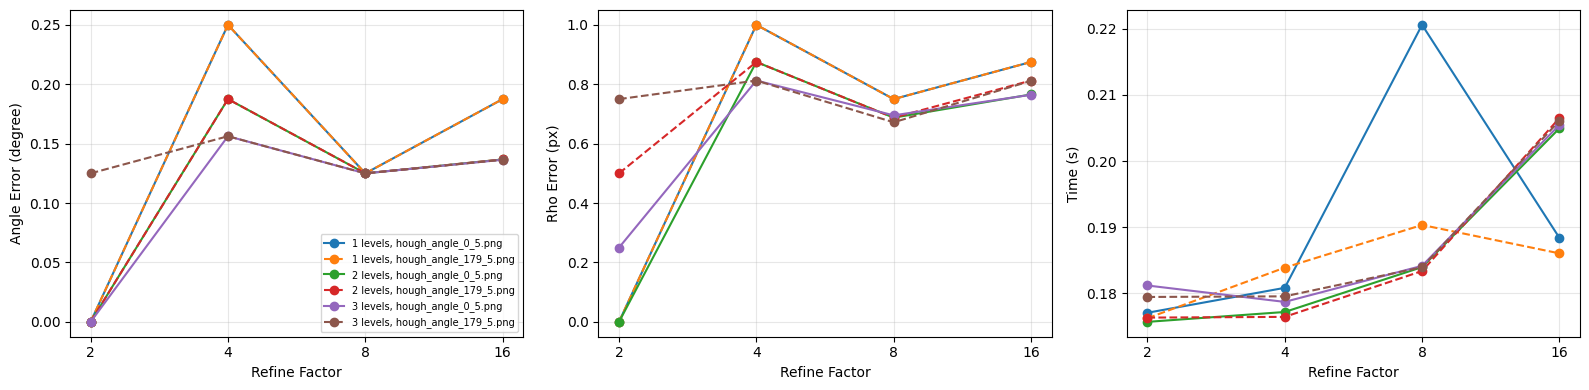

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for n_levels in refine_levels:
    for filename, _, _ in angle_cases:
        rows = [r for r in refine_rows if r["level"] == n_levels and r["image"] == filename]
        ls = "-" if filename == angle_cases[0][0] else "--"

        for ax, key in zip(axes, ["error_theta", "error_rho", "time"]):
            ax.plot(
                [r["factor"] for r in rows],
                [r[key] for r in rows],
                "o" + ls,
                label=f"{n_levels} levels, {filename}"
            )

for ax, ylabel in zip(axes, ["Angle Error (degree)", "Rho Error (px)", "Time (s)"]):
    ax.set_xscale("log", base=2)
    ax.set_xticks(refine_factors)
    ax.set_xticklabels(refine_factors)
    ax.set_xlabel("Refine Factor")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(IMG_DIR / "hough_refine_errors.png", dpi=300, bbox_inches="tight")
plt.show()

In [80]:
A, thetas, rhos, peaks = strongest_peak(
    hough_image > 0,
    theta_step_deg=0.5,
    rho_step=1,
    n_peaks=12
)

print("Ground Truth:")
print("Long Line: rho=110, theta=3°, length=300px")
print("Short Line: rho=270, theta=3°, length=20px")

print("\nDetected Peaks:")

for i, (rho, theta, votes) in enumerate(peaks, 1):
    print(
        f"{i:2d}. "
        f"rho={rho:8.2f}, "
        f"theta={np.rad2deg(theta):7.2f}°, "
        f"votes={votes:.1f}"
    )

Ground Truth:
Long Line: rho=110, theta=3°, length=300px
Short Line: rho=270, theta=3°, length=20px

Detected Peaks:
 1. rho=  110.00, theta=   3.00°, votes=200.0
 2. rho=  116.00, theta=   4.00°, votes=43.0
 3. rho=  103.00, theta=   1.50°, votes=38.0
 4. rho=  124.00, theta=   5.50°, votes=25.0
 5. rho=   97.00, theta=   0.50°, votes=20.0
 6. rho=  268.00, theta=   2.50°, votes=20.0
 7. rho=  276.00, theta=   5.00°, votes=20.0
 8. rho= -105.00, theta= 178.50°, votes=19.0
 9. rho=  -93.00, theta= 177.50°, votes=19.0
10. rho=  -87.00, theta= 179.00°, votes=19.0
11. rho=  114.00, theta=   7.00°, votes=17.0
12. rho=  130.00, theta=   6.50°, votes=17.0


In [81]:
def segment_support(segment, rho, theta, tol=1.0):
    """Số pixel của riêng đoạn chuẩn nằm cách đường phát hiện không quá tol px."""
    seg_image, _ = create_line_image([segment])
    ys, xs = np.nonzero(seg_image)
    dist = np.abs(xs * np.cos(theta) + ys * np.sin(theta) - rho)
    return int(np.sum(dist <= tol)), len(xs)


def match_segments(truths, detections, min_support=0.8):
    """Ghép mỗi đường chuẩn với đường phát hiện phủ được nhiều pixel của đoạn đó nhất
    (hòa, kể cả khi không phủ pixel nào, thì lấy đường gần nhất theo sai số góc + rho/3). Tìm thấy khi tỉ lệ pixel được phủ
    >= min_support. Mỗi đường phát hiện chỉ được ghép với một đường chuẩn."""
    used = set()
    result = []

    for rho0, theta0, length in truths:
        best = None
        for k, (rho, theta, *_) in enumerate(detections):
            if k in used:
                continue
            hit, total = segment_support((rho0, theta0, length), rho, theta)
            et, er = hough_errors(rho0, theta0, rho, theta)
            key = (hit, -(et + er / 3))
            if best is None or key > best[0]:
                best = (key, k, rho, theta, et, er, hit, total)

        if best is None:
            result.append({"truth": (rho0, theta0, length), "found": False, "rank": None,
                           "rho": np.nan, "theta_deg": np.nan, "error_theta": np.nan,
                           "error_rho": np.nan, "support": 0, "total": 0})
            continue

        _, k, rho, theta, et, er, hit, total = best
        found = hit >= min_support * total
        if found:
            used.add(k)
        result.append({
            "truth": (rho0, theta0, length),
            "found": found,
            "rank": k + 1,
            "rho": rho,
            "theta_deg": np.rad2deg(theta),
            "error_theta": et,
            "error_rho": er,
            "support": hit,
            "total": total
        })

    return result


def print_matches(title, truths, detections):
    print(title)
    print("Segment        | Status | Rank | Detected rho | Detected theta | Angle Error | Rho Error | Support")
    for m in match_segments(truths, detections):
        rho0, theta0, length = m["truth"]
        name = f"rho={rho0}, L={length}"
        if m["rank"] is None:
            print(f"{name:14s} | MISSED |    - |            - |              - |           - |         - |       -")
            continue
        status = "FOUND " if m["found"] else "MISSED"
        print(
            f"{name:14s} | {status} | {m['rank']:4d} | "
            f"{m['rho']:12.2f} | {m['theta_deg']:13.2f}° | "
            f"{m['error_theta']:11.3f} | {m['error_rho']:9.3f} | {m['support']:3d}/{m['total']:3d}"
        )
    print()


print_matches("Hough một tỉ lệ (Δθ = 0.5°, Δρ = 1 px, 12 đỉnh):", answers, peaks)

Hough một tỉ lệ (Δθ = 0.5°, Δρ = 1 px, 12 đỉnh):
Segment        | Status | Rank | Detected rho | Detected theta | Angle Error | Rho Error | Support
rho=110, L=300 | FOUND  |    1 |       110.00 |          3.00° |       0.000 |     0.000 | 301/301
rho=270, L=20  | FOUND  |    6 |       268.00 |          2.50° |       0.500 |     2.000 |  21/ 21



### Hough đa tỉ lệ trên ảnh dài + ngắn

Chạy `hough_multiscale` (lưới thô Δρ = 2 px, Δθ = 1°) với số tầng 0–3 và số đỉnh 12, 40; đánh giá riêng đoạn dài và đoạn ngắn.
Một đoạn được tính là tìm thấy khi đường ghép với nó phủ ít nhất 80% pixel của đoạn (cách đường không quá 1 px).

In [82]:
long_short_peaks = [12, 40]
long_short_rows = []
long_short_lines = {}

for n_peaks in long_short_peaks:
    for n_levels in [0, 1, 2, 3]:
        lines = hough_multiscale(
            hough_image > 0,
            None,
            n_levels=n_levels,
            n_peaks=n_peaks,
            rho_step=2,
            theta_step_deg=1
        )
        long_short_lines[(n_peaks, n_levels)] = lines
        print_matches(f"Hough đa tỉ lệ, {n_peaks} đỉnh, {n_levels} tầng:", answers, lines)

        for m in match_segments(answers, lines):
            long_short_rows.append({"peaks": n_peaks, "level": n_levels, **m})

Hough đa tỉ lệ, 12 đỉnh, 0 tầng:
Segment        | Status | Rank | Detected rho | Detected theta | Angle Error | Rho Error | Support
rho=110, L=300 | FOUND  |    1 |       110.00 |          3.00° |       0.000 |     0.000 | 301/301
rho=270, L=20  | MISSED |    8 |       142.00 |          9.00° |       6.000 |   128.000 |   0/ 21

Hough đa tỉ lệ, 12 đỉnh, 1 tầng:
Segment        | Status | Rank | Detected rho | Detected theta | Angle Error | Rho Error | Support
rho=110, L=300 | FOUND  |    1 |       110.75 |          3.12° |       0.125 |     0.750 | 301/301
rho=270, L=20  | MISSED |    8 |       141.25 |          8.75° |       5.750 |   128.750 |   0/ 21

Hough đa tỉ lệ, 12 đỉnh, 2 tầng:
Segment        | Status | Rank | Detected rho | Detected theta | Angle Error | Rho Error | Support
rho=110, L=300 | FOUND  |    1 |       110.69 |          3.09° |       0.094 |     0.688 | 301/301
rho=270, L=20  | MISSED |    8 |       141.06 |          8.78° |       5.781 |   128.938 |   0/ 21

Hough đ

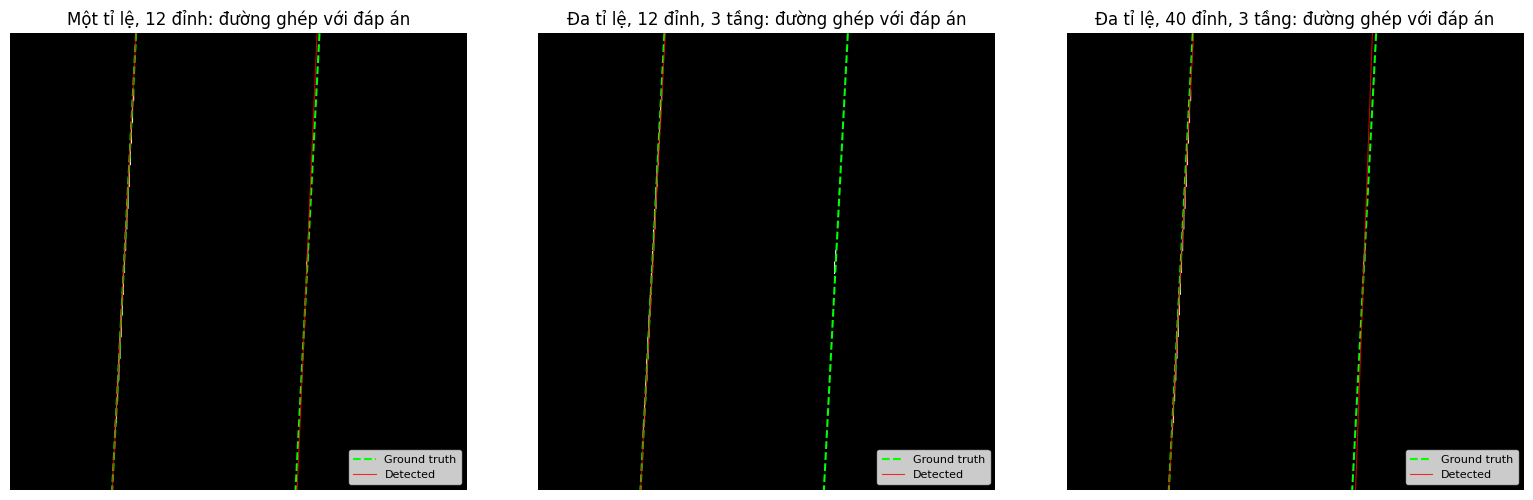

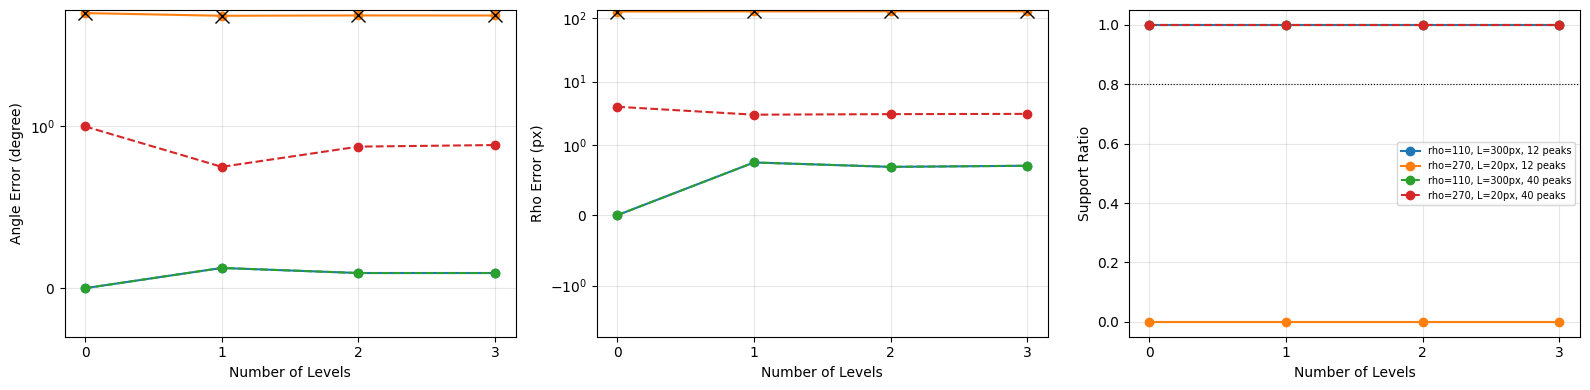

In [83]:
def matched_lines(detections):
    return [
        (m["rho"], np.deg2rad(m["theta_deg"]))
        for m in match_segments(answers, detections) if m["found"]
    ]


fig, axes = plt.subplots(1, 3, figsize=(16, 5))

show_lines(axes[0], hough_image, answers, matched_lines(peaks), "Một tỉ lệ, 12 đỉnh: đường ghép với đáp án")
show_lines(axes[1], hough_image, answers, matched_lines(long_short_lines[(12, 3)]), "Đa tỉ lệ, 12 đỉnh, 3 tầng: đường ghép với đáp án")
show_lines(axes[2], hough_image, answers, matched_lines(long_short_lines[(40, 3)]), "Đa tỉ lệ, 40 đỉnh, 3 tầng: đường ghép với đáp án")

plt.tight_layout()
plt.savefig(IMG_DIR / "hough_long_short_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for n_peaks in long_short_peaks:
    for truth in answers:
        rows = [r for r in long_short_rows if r["truth"] == truth and r["peaks"] == n_peaks]
        label = f"rho={truth[0]}, L={truth[2]}px, {n_peaks} peaks"
        ls = "-" if n_peaks == long_short_peaks[0] else "--"
        for ax, key in zip(axes, ["error_theta", "error_rho"]):
            ax.plot([r["level"] for r in rows], [r[key] for r in rows], "o" + ls, label=label)
            for r in rows:
                if not r["found"]:
                    ax.plot(r["level"], r[key], "kx", ms=10)
        axes[2].plot([r["level"] for r in rows], [r["support"] / r["total"] for r in rows], "o" + ls, label=label)

for ax, ylabel in zip(axes, ["Angle Error (degree)", "Rho Error (px)", "Support Ratio"]):
    ax.set_xlabel("Number of Levels")
    ax.set_ylabel(ylabel)
    ax.set_xticks([0, 1, 2, 3])
    ax.grid(True, alpha=0.3)

axes[0].set_yscale("symlog", linthresh=1)
axes[1].set_yscale("symlog", linthresh=1)
axes[2].axhline(0.8, color="k", lw=0.8, ls=":")
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(IMG_DIR / "hough_long_short_errors.png", dpi=300, bbox_inches="tight")
plt.show()

## Kiểm thử hai góc 0.5 độ và 179.5 độ

So Hough đa tỉ lệ với Hough thô bước 1 độ (`n_levels=0`) trên ảnh của Gấm (CV40 mục 4.3, 4.7c).

### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung kiểm thử hai góc 0.5 độ và 179.5 độ bằng các hàm có sẵn; lập bảng sai số và so sánh với Hough thô.

Prompt:
> Dùng hàm hough_multiscale mình đã viết để thử trên hai ảnh của Gấm có góc 0.5 và 179.5 độ. Chạy đa tỉ lệ với 2 lần tinh chỉnh, mỗi lần chia bước nhỏ hơn 8 lần, rồi so với Hough thô bước 1 độ. In bảng góc tìm được, sai số góc và sai số rho. Kiểm tra góc có nằm trong khoảng từ 0 đến dưới 180 độ, rho có đúng dấu và sai số góc có nhỏ hơn Hough thô không. Báo cả trường hợp chưa đạt, giữ nguyên các hàm đã viết nhé.

Đã sửa lại những gì: Chưa chỉnh sửa thêm. Giữ nguyên các hàm đã viết, chỉ bổ sung phần chạy thử và bảng so sánh kết quả.


In [84]:
thu_muc_anh = thu_muc.parent / "images"
cac_ca = [("hough_angle_0_5.png", 200.0, 0.5), ("hough_angle_179_5.png", -200.0, 179.5)]
ket_qua_nhom = []
print("Ảnh của Gấm. Hough đa tỉ lệ: n_levels=2, refine_factor=8; Hough thô: n_levels=0 (bước 1 độ).")
print("Góc chuẩn | Góc tìm được | Sai số góc | Sai số rho | Sai số góc Hough thô | Kết quả")
for ten_anh, rho0, theta0 in cac_ca:
    anh = np.round(plt.imread(thu_muc_anh / ten_anh) * 255).astype(np.uint8)
    rho, theta = hough_multiscale(anh > 0, None, n_levels=2, refine_factor=8)[0]
    theta_n0 = hough_multiscale(anh > 0, None, n_levels=0)[0][1]
    ss_goc = angle_error(theta0, np.rad2deg(theta))
    ss_rho = rho_error(rho0, theta0, rho, np.rad2deg(theta))
    ss_n0 = angle_error(theta0, np.rad2deg(theta_n0))
    dat = 0 <= theta < np.pi and rho * rho0 > 0 and ss_goc < ss_n0
    ket_qua_nhom.append((anh, rho0, theta0, rho, theta, ss_goc, ss_rho, ss_n0, dat))
    print(f"{theta0:9.2f} độ | {np.rad2deg(theta):11.3f} độ | {ss_goc:9.3f} độ | "
          f"{ss_rho:8.3f} | {ss_n0:19.3f} độ | {'ĐẠT' if dat else 'CHƯA ĐẠT'}")
print("Kiểm thử nhóm:", "ĐẠT" if all(kq[-1] for kq in ket_qua_nhom) else "CHƯA ĐẠT")

Ảnh của Gấm. Hough đa tỉ lệ: n_levels=2, refine_factor=8; Hough thô: n_levels=0 (bước 1 độ).
Góc chuẩn | Góc tìm được | Sai số góc | Sai số rho | Sai số góc Hough thô | Kết quả
     0.50 độ |       0.625 độ |     0.125 độ |    0.688 |               0.500 độ | ĐẠT
   179.50 độ |     179.375 độ |     0.125 độ |    0.688 |               0.500 độ | ĐẠT
Kiểm thử nhóm: ĐẠT


## Ô đối chiếu thư viện (chỉ ở đây mới được gọi hàm bị cấm)

In [85]:
lines = cv2.HoughLines(edge_map.astype(np.uint8) * 255, 1, np.pi / 180, 50)

print("cv2.HoughLines (bước 1 px, 1°), 3 đường đầu:")
for rho, theta in lines[:3, 0]:
    print(f"  rho = {rho:6.1f}, theta = {np.rad2deg(theta):5.1f}°")

rho_mine, theta_mine, _ = results["thường"][2][0]
print(f"\nHàm tự viết, đỉnh mạnh nhất: rho = {rho_mine:6.1f}, theta = {np.rad2deg(theta_mine):5.1f}°")

cv2.HoughLines (bước 1 px, 1°), 3 đường đầu:
  rho =  111.0, theta =   3.0°
  rho =  109.0, theta =   3.0°
  rho =  114.0, theta =   4.0°

Hàm tự viết, đỉnh mạnh nhất: rho =  110.0, theta =   3.0°


### Ô đối chiếu thư viện (mục 4.6)

Ô dưới dùng `cv2.HoughLines` **chỉ để kiểm chứng bộ ảnh thử** (đáp án rho, theta của ảnh tạo ra là đúng).
Đây **không phải** kết quả của thuật toán tự viết; kết quả tự viết nằm ở các ô dùng `hough_accumulate`, `find_peaks`, `hough_multiscale` bên dưới.

In [86]:
# ĐỐI CHIẾU THƯ VIỆN: cv2.HoughLines chỉ dùng để kiểm chứng ảnh thử, không phải thuật toán tự viết
def check_hough_opencv(image, rho_true, theta_true, threshold):
    lines = cv2.HoughLines(image, 1, np.pi / 360, threshold)

    if lines is None:
        print("[OpenCV] Không phát hiện được đường thẳng")
        return

    rho_detected, theta = lines[0][0]
    theta_detected = np.rad2deg(theta)

    e_theta = angle_error(theta_true, theta_detected)
    e_rho = rho_error(rho_true, theta_true, rho_detected, theta_detected)

    print(f"Đáp án: rho={rho_true}, theta={theta_true}°")
    print(f"[OpenCV] Phát hiện: rho={rho_detected:.2f}, theta={theta_detected:.2f}°")
    print(f"[OpenCV] Sai số góc: {e_theta:.2f}°")
    print(f"[OpenCV] Sai số rho: {e_rho:.2f}px")


for rho, theta, length in angle_tests:
    image, _ = create_line_image([(rho, theta, length)])
    print(f"\nĐối chiếu OpenCV, theta={theta}°")
    check_hough_opencv(image, rho, theta, 100)


Đối chiếu OpenCV, theta=0.5°
Đáp án: rho=200, theta=0.5°
[OpenCV] Phát hiện: rho=200.00, theta=0.50°
[OpenCV] Sai số góc: 0.00°
[OpenCV] Sai số rho: 0.00px

Đối chiếu OpenCV, theta=179.5°
Đáp án: rho=-200, theta=179.5°
[OpenCV] Phát hiện: rho=-200.00, theta=179.50°
[OpenCV] Sai số góc: 0.00°
[OpenCV] Sai số rho: 0.00px


### Ô đối chiếu thư viện

Chỉ dùng cv2.HoughLines ở ô mã bên dưới để so sánh với kết quả Hough của nhóm.

### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung đối chiếu kết quả Hough của nhóm với OpenCV; lập bảng sai số và vẽ đường chuẩn, đường phát hiện.

Prompt:
> Dùng kết quả Hough của nhóm để so sánh với cv2.HoughLines trên hai ảnh góc 0.5 và 179.5 độ. Cho OpenCV dùng bước rho 1 pixel, bước góc 1 độ và ngưỡng 50 phiếu. In bảng sai số góc, sai số rho và vẽ đường chuẩn, đường nhóm tìm được, đường OpenCV lên cùng ảnh. Phóng to một vùng để dễ nhìn chỗ lệch nhau. Giữ nguyên các hàm của nhóm nhé

Đã sửa lại những gì: Chưa chỉnh sửa thêm. Giữ nguyên các hàm của nhóm, chỉ bổ sung phần đối chiếu với OpenCV, bảng sai số và hình so sánh

OpenCV HoughLines: bước rho = 1 pixel, bước theta = 1 độ, ngưỡng phiếu = 50.
Góc chuẩn | Sai số góc nhóm | Sai số rho nhóm | Sai số góc OpenCV | Sai số rho OpenCV | Kết quả
     0.50 độ |           0.125 độ |           0.688 |             0.500 độ |             2.000 | ĐẠT
   179.50 độ |           0.125 độ |           0.688 |             0.500 độ |             2.000 | ĐẠT

Sai số góc trung bình: Hough đa tỉ lệ 0.125 độ, Hough thô nhóm 0.500 độ, OpenCV 0.500 độ
Đối chiếu toàn bộ: ĐẠT


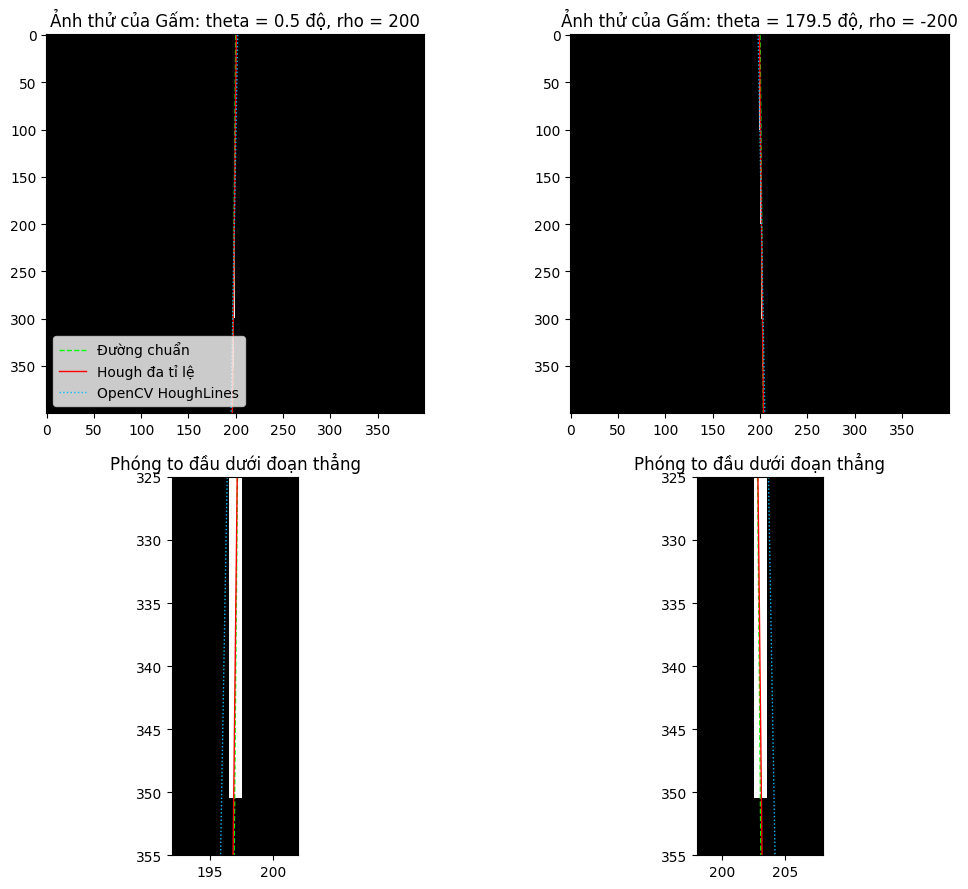

In [87]:
print("OpenCV HoughLines: bước rho = 1 pixel, bước theta = 1 độ, ngưỡng phiếu = 50.")
print("Góc chuẩn | Sai số góc nhóm | Sai số rho nhóm | Sai số góc OpenCV | Sai số rho OpenCV | Kết quả")
duong_cv, sai_so, tat_ca_dat = [], [], True
for anh, rho0, theta0, rho, theta, ss_goc, ss_rho, ss_n0, dat in ket_qua_nhom:
    rho_cv, theta_cv = cv2.HoughLines(anh, 1, np.pi / 180, 50)[0, 0]
    ss_cv = angle_error(theta0, np.rad2deg(theta_cv))
    ss_rho_cv = rho_error(rho0, theta0, rho_cv, np.rad2deg(theta_cv))
    dat = dat and ss_goc < ss_cv
    tat_ca_dat = tat_ca_dat and dat
    duong_cv.append((rho_cv, theta_cv))
    sai_so.append((ss_goc, ss_n0, ss_cv))
    print(f"{theta0:9.2f} độ | {ss_goc:15.3f} độ | {ss_rho:15.3f} | "
          f"{ss_cv:17.3f} độ | {ss_rho_cv:17.3f} | {'ĐẠT' if dat else 'CHƯA ĐẠT'}")
tb = np.mean(sai_so, axis=0)
print(f"\nSai số góc trung bình: Hough đa tỉ lệ {tb[0]:.3f} độ, Hough thô nhóm {tb[1]:.3f} độ, OpenCV {tb[2]:.3f} độ")
print("Đối chiếu toàn bộ:", "ĐẠT" if tat_ca_dat else "CHƯA ĐẠT")

fig, axes = plt.subplots(2, len(ket_qua_nhom), figsize=(11, 9))
for cot, (kq, (rho_cv, theta_cv)) in enumerate(zip(ket_qua_nhom, duong_cv)):
    anh, rho0, theta0, rho, theta = kq[:5]
    ys, xs = np.nonzero(anh)
    y_cuoi = ys.max()
    x_cuoi = xs[ys == y_cuoi].mean()
    y = np.arange(anh.shape[0])
    for hang, ax in enumerate(axes[:, cot]):
        ax.imshow(anh, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        for r, t, mau, kieu, nhan in [(rho0, np.deg2rad(theta0), "lime", "--", "Đường chuẩn"),
                                      (rho, theta, "red", "-", "Hough đa tỉ lệ"),
                                      (rho_cv, theta_cv, "deepskyblue", ":", "OpenCV HoughLines")]:
            ax.plot((r - y * np.sin(t)) / np.cos(t), y, linestyle=kieu, color=mau, linewidth=1, label=nhan)
        if hang == 0:
            ax.set_xlim(-0.5, anh.shape[1] - 0.5)
            ax.set_ylim(anh.shape[0] - 0.5, -0.5)
            ax.set_title(f"Ảnh thử của Gấm: theta = {theta0} độ, rho = {rho0:g}")
        else:
            ax.set_xlim(x_cuoi - 5, x_cuoi + 5)
            ax.set_ylim(y_cuoi + 5, y_cuoi - 25)
            ax.set_title("Phóng to đầu dưới đoạn thẳng")
axes[0, 0].legend(loc="lower left")
plt.tight_layout()
plt.show()

## Mở rộng – Bộ lọc song phương  _(Tấn Hiệp)_

## Mở rộng - Bộ lọc song phương (so với lọc Gaussian)

Làm mờ nhưng giữ cạnh, so với lọc Gaussian cùng sigma_s (CV40 mục 3.2; CV23 slide 27).

In [88]:
def bilateral_filter(anh, r, sigma_s, sigma_r):
    anh = np.asarray(anh, dtype=np.float64)
    H, W = anh.shape
    dem = np.pad(anh, r, mode="reflect")
    tong_trong_so_nhan = np.zeros((H, W))
    tong_trong_so = np.zeros((H, W))
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            hang_xom = dem[r + dy:r + dy + H, r + dx:r + dx + W]
            nhan_khong_gian = np.exp(-(dx * dx + dy * dy) / (2 * sigma_s ** 2))
            nhan_gia_tri = np.exp(-(hang_xom - anh) ** 2 / (2 * sigma_r ** 2))
            w = nhan_khong_gian * nhan_gia_tri
            tong_trong_so_nhan += w * hang_xom
            tong_trong_so += w
    return tong_trong_so_nhan / tong_trong_so

### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung thí nghiệm so sánh Gaussian và bộ lọc song phương có sẵn: tạo ảnh thử có nhiễu, chạy lọc và đo độ mịn vùng phẳng, độ rộng cạnh.

Prompt:
> Tạo giúp mình một ảnh có vài vùng sáng tối và cạnh rõ, rồi thêm nhiễu Gaussian để thử hai hàm lọc mình đã viết. Cho lọc Gaussian và lọc song phương dùng cùng bán kính và sigma không gian. Đo độ mịn ở vùng phẳng, độ rộng cạnh rồi in bảng so sánh trước và sau lọc. Thử thêm trường hợp sigma giá trị rất lớn để xem lọc song phương có gần giống Gaussian không. Giữ nguyên các hàm lọc của mình nhé.

Đã sửa lại những gì: Chưa chỉnh sửa thêm. Giữ nguyên các hàm lọc đã viết, chỉ bổ sung ảnh thử và phần đo kết quả thí nghiệm.


In [89]:
R_LOC, SIGMA_S, SIGMA_R = 4, 2.0, 30.0

anh_sach = np.full((96, 96), 60.0)
anh_sach[:, 32:64] = 140.0
anh_sach[:, 64:] = 200.0
anh_sach[56:84, 8:24] = 100.0
anh_nhieu = np.clip(anh_sach + np.random.default_rng(0).normal(0, 12, anh_sach.shape), 0, 255)

la_canh = (np.diff(anh_sach, axis=0, prepend=anh_sach[:1]) != 0) | (np.diff(anh_sach, axis=1, prepend=anh_sach[:, :1]) != 0)
cua_so = (2 * R_LOC + 3, 2 * R_LOC + 3)
vung_phang = ~np.lib.stride_tricks.sliding_window_view(np.pad(la_canh, R_LOC + 1), cua_so).any(axis=(2, 3))
vung_phang[:R_LOC] = vung_phang[-R_LOC:] = vung_phang[:, :R_LOC] = vung_phang[:, -R_LOC:] = False


def do_min_vung_phang(anh):
    return float(np.std((anh - anh_sach)[vung_phang]))


def do_rong_canh(anh, cot_canh=64, hang=slice(4, 48)):
    cat = anh[hang, cot_canh - 10:cot_canh + 10].mean(axis=0)
    thap, cao = cat[:5].mean(), cat[-5:].mean()
    x = np.arange(len(cat))
    x10 = np.interp(thap + 0.1 * (cao - thap), cat, x)
    x90 = np.interp(thap + 0.9 * (cao - thap), cat, x)
    return float(x90 - x10)


anh_gauss = convolve2d(anh_nhieu, gaussian_kernel(2 * R_LOC + 1, SIGMA_S), padding="reflect")
anh_song_phuong = bilateral_filter(anh_nhieu, R_LOC, SIGMA_S, SIGMA_R)
ket_qua_loc = {"Ảnh nhiễu": anh_nhieu,
               f"Gaussian sigma_s={SIGMA_S}": anh_gauss,
               f"Song phương sigma_s={SIGMA_S}, sigma_r={SIGMA_R}": anh_song_phuong}

lech_gauss = np.abs(bilateral_filter(anh_nhieu, R_LOC, SIGMA_S, 1e9) - anh_gauss)[R_LOC:-R_LOC, R_LOC:-R_LOC].max()
print(f"Kiểm tra sigma_r = 1e9 so với Gaussian: lệch lớn nhất {lech_gauss:.2e}", "(đạt)" if lech_gauss < 1e-6 else "(CHƯA ĐẠT)")

print(f"\n{'Ảnh':32s} | {'độ lệch chuẩn vùng phẳng':>24s} | {'độ rộng cạnh 10-90%':>20s}")
for ten, anh in {"Ảnh sạch (chuẩn)": anh_sach, **ket_qua_loc}.items():
    print(f"{ten:32s} | {do_min_vung_phang(anh):>24.2f} | {do_rong_canh(anh):>17.2f} px")
print("\nSong phương: vùng phẳng mịn hơn ảnh nhiễu:", "Có" if do_min_vung_phang(anh_song_phuong) < do_min_vung_phang(anh_nhieu) else "Không")
print("Song phương: cạnh sắc hơn lọc Gaussian:", "Có" if do_rong_canh(anh_song_phuong) < do_rong_canh(anh_gauss) else "Không")

Kiểm tra sigma_r = 1e9 so với Gaussian: lệch lớn nhất 3.13e-13 (đạt)

Ảnh                              | độ lệch chuẩn vùng phẳng |  độ rộng cạnh 10-90%
Ảnh sạch (chuẩn)                 |                     0.00 |              0.80 px
Ảnh nhiễu                        |                    11.99 |              0.81 px
Gaussian sigma_s=2.0             |                     1.73 |              5.11 px
Song phương sigma_s=2.0, sigma_r=30.0 |                     2.66 |              1.48 px

Song phương: vùng phẳng mịn hơn ảnh nhiễu: Có
Song phương: cạnh sắc hơn lọc Gaussian: Có


### Ô đối chiếu thư viện

Chỉ dùng `cv2.bilateralFilter` ở ô bên dưới để đối chiếu với bộ lọc song phương của nhóm.


### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung đối chiếu bộ lọc song phương có sẵn với cv2.bilateralFilter bằng cùng bộ tham số và báo sai lệch.

Prompt:
> Dùng ảnh nhiễu đang có để so sánh hàm lọc song phương mình đã viết với cv2.bilateralFilter. Cho hai cách dùng cùng tham số, bỏ phần viền khi tính sai lệch rồi in sai lệch trung bình và lớn nhất. In thêm độ mịn vùng phẳng và độ rộng cạnh của ảnh OpenCV giúp mình. Giữ nguyên hàm mình đã viết nhé. 

Đã sửa lại những gì: Chưa chỉnh sửa thêm. Giữ nguyên hàm lọc của mình, chỉ dùng OpenCV để đối chiếu kết quả.


In [90]:
anh_cv = cv2.bilateralFilter(anh_nhieu.astype(np.float32), 2 * R_LOC + 1, SIGMA_R, SIGMA_S,
                             borderType=cv2.BORDER_REFLECT).astype(np.float64)
lech = np.abs(anh_song_phuong - anh_cv)[R_LOC:-R_LOC, R_LOC:-R_LOC]
print(f"OpenCV bilateralFilter: độ lệch chuẩn vùng phẳng {do_min_vung_phang(anh_cv):.2f}, độ rộng cạnh {do_rong_canh(anh_cv):.2f} px")
print(f"bilateral_filter so với OpenCV (bỏ viền): lệch trung bình {lech.mean():.3f}, lớn nhất {lech.max():.3f} mức xám")

OpenCV bilateralFilter: độ lệch chuẩn vùng phẳng 2.80, độ rộng cạnh 1.33 px
bilateral_filter so với OpenCV (bỏ viền): lệch trung bình 0.257, lớn nhất 2.773 mức xám


### Có dùng AI hỗ trợ

Công cụ: Claude (Anthropic), qua Claude Code

Mục đích: Dựng khung trực quan hóa thí nghiệm: vẽ lưới ảnh, vùng phóng to, mặt cắt cường độ, so sánh trên ảnh thật và lưu hình.

Prompt:
> Dùng các hàm lọc mình đã viết để vẽ ảnh so sánh lọc Gaussian với lọc song phương. Cho ảnh gốc, ảnh nhiễu và ảnh sau lọc nằm cạnh nhau, phóng to cùng một vùng để dễ nhìn cạnh hơn. Vẽ thêm đồ thị mức sáng qua cạnh, rồi thử trên ảnh home.jpg và lưu hình lại giúp mình. Giữ nguyên các hàm mình đã viết nhé.

Đã sửa lại những gì: Bổ sung lưới chính/phụ và mốc chia trục để dễ đọc giá trị trên đồ thị mặt cắt; ngắt dòng tiêu đề cho vừa khung hình.


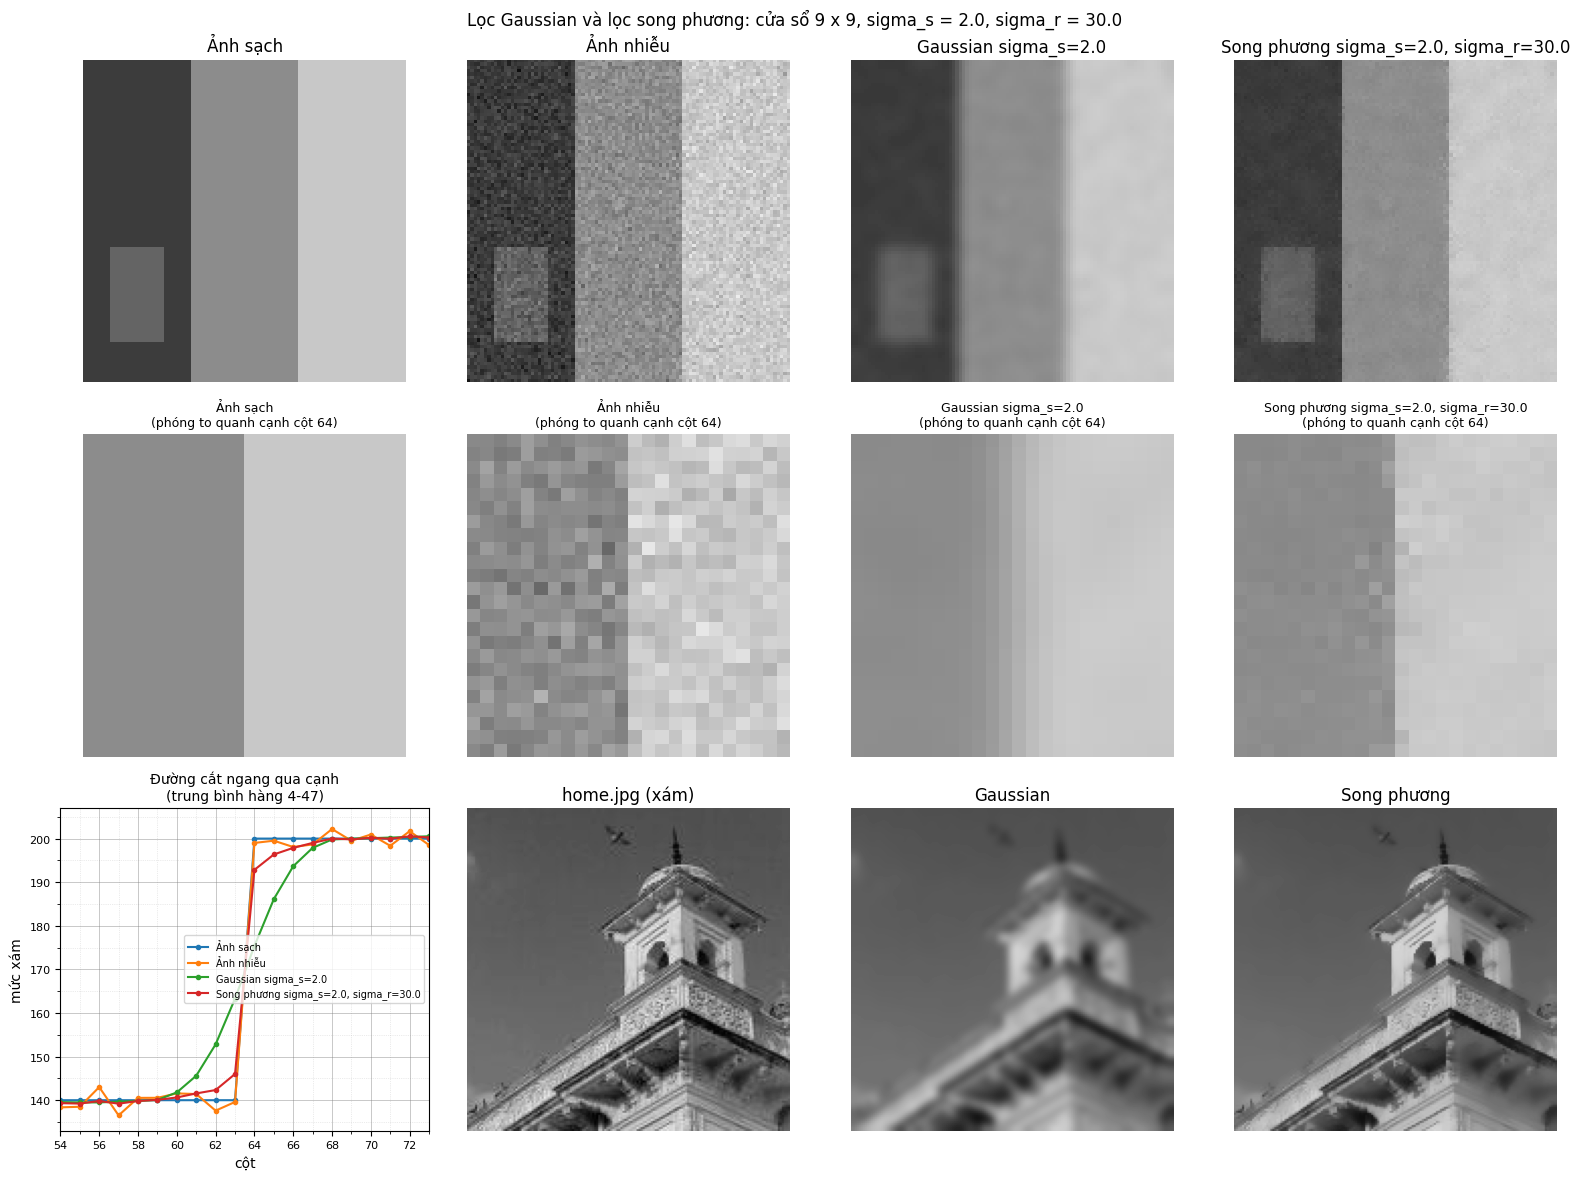

In [91]:
anh_mau = plt.imread(thu_muc.parent / "images" / "home.jpg")[..., :3].astype(np.float64)
anh_that = (0.299 * anh_mau[..., 0] + 0.587 * anh_mau[..., 1] + 0.114 * anh_mau[..., 2])[120:280, 180:340]
that_loc = {"home.jpg (xám)": anh_that,
            "Gaussian": convolve2d(anh_that, gaussian_kernel(2 * R_LOC + 1, SIGMA_S), padding="reflect"),
            "Song phương": bilateral_filter(anh_that, R_LOC, SIGMA_S, SIGMA_R)}
hang_1 = {"Ảnh sạch": anh_sach, **ket_qua_loc}

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, (ten, anh) in zip(axes[0], hang_1.items()):
    ax.imshow(anh, cmap="gray", vmin=0, vmax=255)
    ax.set_title(ten)
for ax, (ten, anh) in zip(axes[1], hang_1.items()):
    ax.imshow(anh[20:44, 52:76], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(ten + "\n(phóng to quanh cạnh cột 64)", fontsize=9)
for ten, anh in hang_1.items():
    axes[2, 0].plot(np.arange(54, 74), anh[4:48, 54:74].mean(axis=0), "o-", markersize=3, label=ten)
axes[2, 0].set_title("Đường cắt ngang qua cạnh\n(trung bình hàng 4-47)", fontsize=10)
axes[2, 0].set_xlabel("cột")
axes[2, 0].set_ylabel("mức xám")
axes[2, 0].set_xlim(54, 73)
axes[2, 0].set_ylim(133, 207)
axes[2, 0].set_xticks(np.arange(54, 74, 2))
axes[2, 0].set_xticks(np.arange(54, 74, 1), minor=True)
axes[2, 0].set_yticks(np.arange(140, 201, 10))
axes[2, 0].set_yticks(np.arange(135, 206, 5), minor=True)
axes[2, 0].tick_params(axis="both", labelsize=8)
axes[2, 0].set_axisbelow(True)
axes[2, 0].grid(True, which="major", color="gray", linewidth=0.6, alpha=0.5)
axes[2, 0].grid(True, which="minor", color="gray", linestyle=":", linewidth=0.5, alpha=0.3)
axes[2, 0].legend(fontsize=7)
for ax, (ten, anh) in zip(axes[2, 1:], that_loc.items()):
    ax.imshow(anh, cmap="gray", vmin=0, vmax=255)
    ax.set_title(ten)
for ax in axes.flat:
    if ax is not axes[2, 0]:
        ax.axis("off")
fig.suptitle(f"Lọc Gaussian và lọc song phương: cửa sổ {2 * R_LOC + 1} x {2 * R_LOC + 1}, sigma_s = {SIGMA_S}, sigma_r = {SIGMA_R}")
plt.tight_layout()
plt.savefig(thu_muc.parent / "images" / "song_phuong_so_sanh.png", dpi=110)
plt.show()

---
### Mẫu khai báo khi dùng AI (chép lên trên ô mã tương ứng)

```
### Có dùng AI hỗ trợ
Công cụ: <tên công cụ>
Mục đích: <sinh ảnh thử / dựng vòng lặp quét tham số / vẽ lưới ảnh / ...>
Prompt:
> <chép nguyên văn prompt>
Đã sửa lại những gì: <mô tả ngắn>
```